In [ ]:
import numpy as np
import pandas as pd
import re

# =========================
# CONFIG
# =========================
FILE_IN  = "dataset_1.csv"
TARGET   = "Label"
FILE_OUT = "dataset_1_cleaned.csv"

# =========================
# LOAD
# =========================
df = pd.read_csv(FILE_IN, low_memory=False)
print(f"Loaded: {FILE_IN}")
print("Original shape:", df.shape)

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found. Columns are: {list(df.columns)[:30]} ...")

# =========================
# 1) STANDARDIZE MISSING TOKENS -> NaN
# =========================
# Convert common string-missing tokens (case-insensitive, whitespace-tolerant) to NaN
missing_regex = r"^\s*(?:na|n/a|none|null|nan)\s*$"
df = df.replace(to_replace=missing_regex, value=np.nan, regex=True)

# Also treat empty/whitespace-only strings as NaN
df = df.replace(to_replace=r"^\s*$", value=np.nan, regex=True)

# Snapshot missing counts BEFORE fixes
missing_before = df.isna().sum()
total_missing_before = int(missing_before.sum())

print("\nTop missing columns (before):")
print(missing_before[missing_before > 0].sort_values(ascending=False).head(30))

# =========================
# 2) DUPLICATE ROWS -> REMOVE
# =========================
dup_count = int(df.duplicated().sum())
df = df.drop_duplicates()
print(f"\nDuplicate rows found: {dup_count}")
print("Shape after drop_duplicates:", df.shape)

# =========================
# 3) DROP ROWS WHERE TARGET IS MISSING
# =========================
missing_target_rows = int(df[TARGET].isna().sum())
df = df.dropna(subset=[TARGET])
print(f"Rows with missing {TARGET} removed: {missing_target_rows}")
print("Shape after dropping missing target:", df.shape)

# =========================
# 4) TRY CONVERT "MOSTLY-NUMERIC" OBJECT COLUMNS TO NUMERIC
#    (so they get mean-imputed instead of mode)
# =========================
for col in df.columns:
    if col == TARGET:
        continue
    if pd.api.types.is_object_dtype(df[col]):
        s = df[col]
        non_missing = int(s.notna().sum())
        if non_missing == 0:
            continue
        # remove commas then numeric convert
        conv = pd.to_numeric(s.astype(str).str.replace(",", "", regex=False), errors="coerce")
        convertible = int(conv.notna().sum())
        ratio = convertible / non_missing
        if ratio >= 0.95:  # threshold: 95% of non-missing values look numeric
            df[col] = conv

# =========================
# 5) IMPUTE MISSING: mean (numeric), mode (categorical)
#    Drop columns that are entirely missing.
# =========================
dropped_all_missing_cols = []

for col in list(df.columns):
    if col == TARGET:
        continue

    if df[col].isna().all():
        dropped_all_missing_cols.append(col)
        df = df.drop(columns=[col])
        continue

    if df[col].isna().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].mean())
        else:
            mode_series = df[col].mode(dropna=True)
            if mode_series.empty:
                dropped_all_missing_cols.append(col)
                df = df.drop(columns=[col])
            else:
                df[col] = df[col].fillna(mode_series.iloc[0])

# If anything still missing (rare edge cases), drop those rows
remaining_missing = int(df.isna().sum().sum())
if remaining_missing > 0:
    before = df.shape[0]
    df = df.dropna()
    after = df.shape[0]
    print(f"\nRemaining missing after impute: {remaining_missing} -> dropped {before-after} rows")

print("\nColumns dropped (all-missing or no-mode):", dropped_all_missing_cols)

# =========================
# FINAL REPORT
# =========================
missing_after = df.isna().sum()
total_missing_after = int(missing_after.sum())

print("\n================ FINAL =================")
print("Final shape:", df.shape)
print("Total missing BEFORE:", total_missing_before)
print("Total missing AFTER :", total_missing_after)

# Count rows + dtype of each column (as requested)
dtype_table = df.dtypes.reset_index()
dtype_table.columns = ["column", "dtype"]

print("\nRow count:", df.shape[0])
print("\nDtypes (all columns):")
print(dtype_table.to_string(index=False))

# =========================
# SAVE
# =========================
df.to_csv(FILE_OUT, index=False)
print(f"\nSaved cleaned file -> {FILE_OUT}")


Loaded: dataset_1.csv
Original shape: (368017, 29)

Top missing columns (before):
Series([], dtype: int64)

Duplicate rows found: 5572
Shape after drop_duplicates: (362445, 29)
Rows with missing Label removed: 0
Shape after dropping missing target: (362445, 29)

Columns dropped (all-missing or no-mode): []

================ FINAL =================
Final shape: (362445, 29)
Total missing BEFORE: 0
Total missing AFTER : 0

Row count: 362445

Dtypes (all columns):
         column   dtype
          srcip  object
          sport float64
          dstip  object
         dsport float64
          proto  object
          state  object
            dur float64
         sbytes float64
         dbytes float64
           sttl float64
        service float64
          Sload float64
          Dload float64
          Spkts float64
          Dpkts float64
           swin float64
          stcpb float64
          dtcpb float64
        smeansz float64
        dmeansz float64
    trans_depth float64
    re

# **TreeFed-CERT+**

RUN_DIR: treefed_cert_run/treefed_20251217_160455
Rows=362445 | Features=28 | Cat=9 | Num=19 | Classes=2
Train_pool=(289956, 28) | Test=(72489, 28)
Anchor=(20000, 28) -> anchor_tr=(16000, 28), anchor_va=(4000, 28)
Client_pool=(269956, 28)
Client-1: n=28366 | dist={0: np.int64(13973), 1: np.int64(14393)}
Client-2: n=52838 | dist={0: np.int64(39), 1: np.int64(52799)}
Client-3: n=51331 | dist={0: np.int64(86), 1: np.int64(51245)}
Client-4: n=137421 | dist={0: np.int64(6136), 1: np.int64(131285)}

============= CLIENT 1 : NESTED CV ================
Client-1 Outer-1: acc=0.9903 prec=0.9854 rec=0.9956 f1=0.9905 auc=0.9996 logloss=0.0225 | inner_best=0.9903168186518755 | search=1.1m refit=0.1m
Client-1 Outer-2: acc=0.9908 prec=0.9884 rec=0.9936 f1=0.9910 auc=0.9990 logloss=0.0379 | inner_best=0.9894707154272822 | search=0.8m refit=0.1m
Client-1 Outer-3: acc=0.9897 prec=0.9849 rec=0.9950 f1=0.9899 auc=0.9994 logloss=0.0287 | inner_best=0.9910222846773695 | search=0.7m refit=0.0m
Client-1 Outer

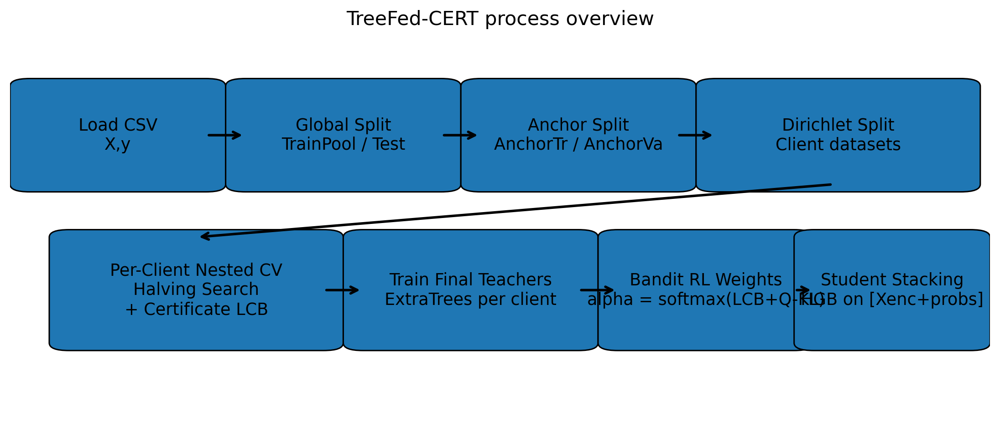

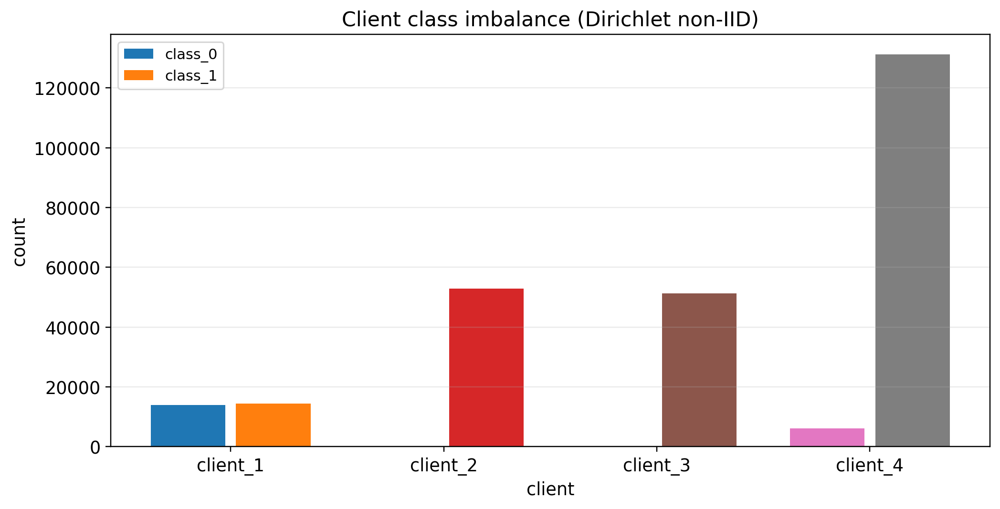

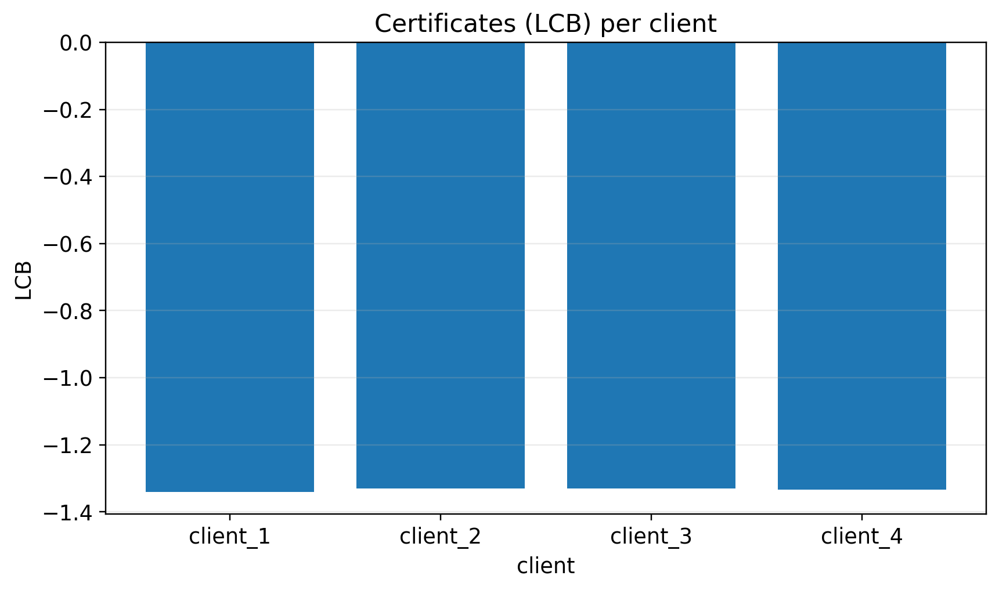

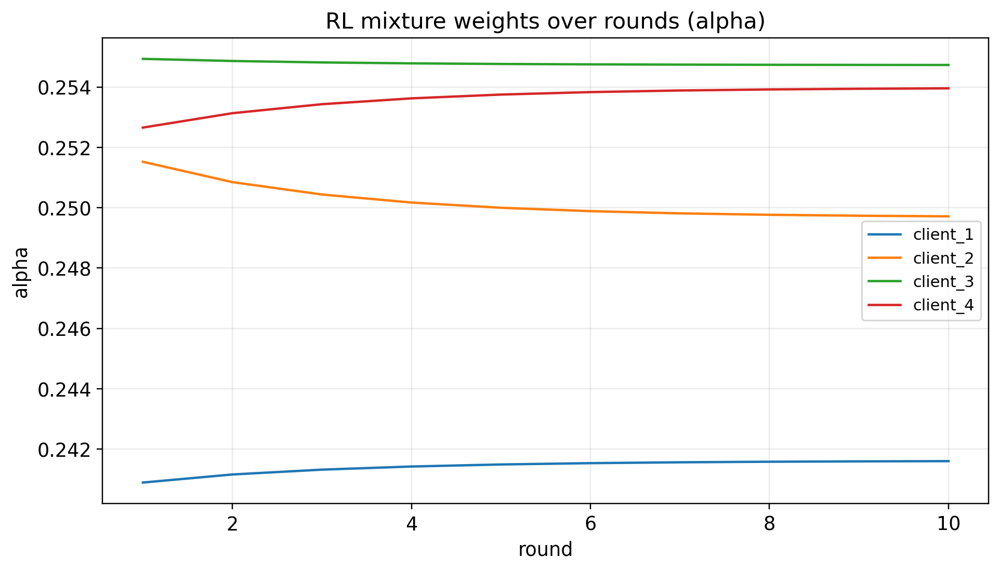

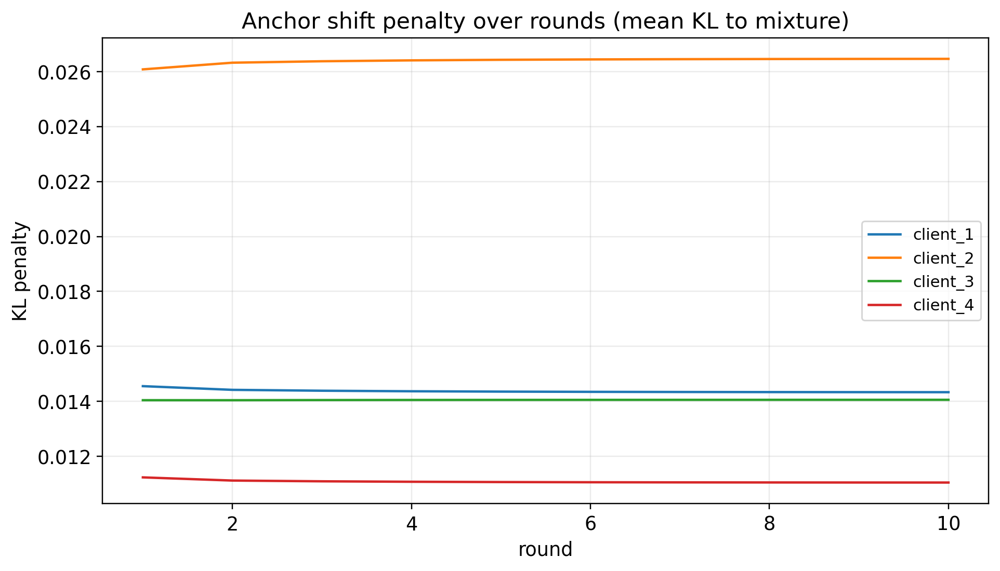

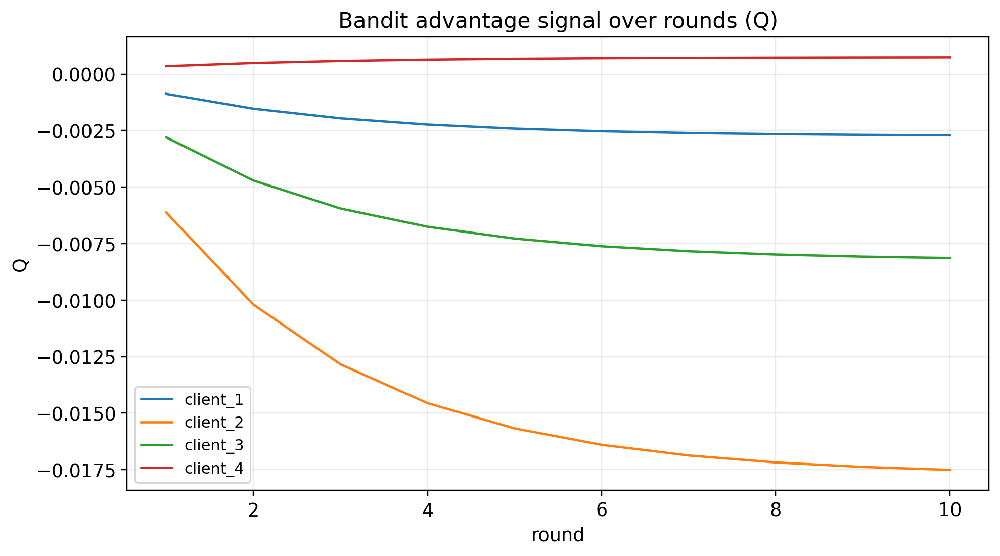

In [4]:
# ============================================================
# TreeFed-CERT (FAST + TREE-BASED + NOVEL + LEAKAGE-SAFE)
# ------------------------------------------------------------
# FIXED: robust target(Label) handling (drops NaN/inf safely)
# Adds:
#  - ROC-AUC in all metric reports
#  - Process diagrams at the end (display only; no file saving)
#
# OUTPUTS (minimal):
#   1) artifacts.pkl  -> everything (models + metrics + probs + RL history)
#   2) metrics.csv    -> tidy table
# ============================================================

import time, json, math, pickle, random, inspect, warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.patches as patches

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, log_loss,
    roc_auc_score
)
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier

from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.model_selection import HalvingRandomSearchCV

warnings.filterwarnings("ignore")

# =========================
# CONFIG
# =========================
CFG = {
    "data_path": "dataset_1_cleaned.csv",
    "target_col": "Label",   # <- fixed as you said
    "seed": 42,

    "global_test_size": 0.20,
    "anchor_size": 20000,
    "anchor_val_size": 0.20,

    "n_clients": 4,
    "dirichlet_alpha": 0.6,

    "topk": 4,
    "max_cat_classes": 5,

    "outer_folds": 4,
    "inner_folds": 2,

    "inner_search_max_rows": 60000,

    "halving_candidates": 12,
    "halving_min_estimators": 40,
    "halving_max_estimators": 140,
    "halving_factor": 2,

    "teacher_refit_estimators": 200,

    "rl_rounds": 10,
    "rl_beta": 0.35,
    "eta_softmax": 6.0,
    "shift_gamma": 1.0,
    "delta_cert": 0.10,

    "student_max_iter": 250,
    "student_lr": 0.08,
    "student_max_depth": 8,

    "out_dir": "treefed_cert_run",
    "save_metrics_csv": True,
}

plt.rcParams.update({
    "figure.dpi": 220,
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
})

# =========================
# Utilities
# =========================
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)

def softmax(x):
    x = np.asarray(x, dtype=float)
    x = x - np.max(x)
    e = np.exp(x)
    return e / (e.sum() + 1e-12)

def empirical_bernstein_lcb(accs, delta=0.10):
    accs = np.asarray(accs, dtype=float)
    n = len(accs)
    mu = float(accs.mean())
    v = float(((accs - mu) ** 2).mean())
    term1 = math.sqrt((2.0 * v * math.log(2.0 / delta)) / max(1, n))
    term2 = (7.0 * math.log(2.0 / delta)) / (3.0 * max(1, n - 1))
    return float(mu - term1 - term2)

def mean_kl(p, q, eps=1e-12):
    p = np.clip(p, eps, 1.0)
    q = np.clip(q, eps, 1.0)
    return float(np.mean(np.sum(p * (np.log(p) - np.log(q)), axis=1)))

def stratified_cap(X, y, max_n, seed):
    if max_n is None or len(y) <= max_n:
        return X, y
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    parts = []
    for cls in np.unique(y):
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)
        take = max(1, int(max_n * (len(idx) / len(y))))
        take = min(take, len(idx))
        parts.append(idx[:take])
    pick = np.concatenate(parts)
    rng.shuffle(pick)
    return X.iloc[pick].reset_index(drop=True), y[pick]

def split_clients_dirichlet(y, n_clients=4, alpha=0.6, seed=42):
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    classes = np.unique(y)
    client_indices = [[] for _ in range(n_clients)]

    for cls in classes:
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)
        props = rng.dirichlet(alpha * np.ones(n_clients))
        counts = (props * len(idx)).astype(int)
        diff = len(idx) - counts.sum()
        order = np.argsort(-props)
        for k in range(abs(diff)):
            counts[order[k % n_clients]] += 1 if diff > 0 else -1

        start = 0
        for ci in range(n_clients):
            cnt = counts[ci]
            if cnt > 0:
                client_indices[ci].extend(idx[start:start+cnt].tolist())
            start += cnt

    for ci in range(n_clients):
        rng.shuffle(client_indices[ci])
    return [np.array(ix, dtype=int) for ix in client_indices]

def safe_proba_for_logloss(proba, eps=1e-12):
    proba = np.asarray(proba, dtype=float)
    proba = np.clip(proba, eps, 1.0)
    proba = proba / (proba.sum(axis=1, keepdims=True) + eps)
    return proba

def compute_metrics(y_true, y_pred, proba=None, labels=None):
    labels = np.asarray(labels) if labels is not None else np.unique(y_true)
    K = len(labels)
    out = {}
    out["accuracy"] = float(accuracy_score(y_true, y_pred))

    if K == 2:
        pos = labels[1]
        out["precision"] = float(precision_score(y_true, y_pred, average="binary", pos_label=pos, zero_division=0))
        out["recall"]    = float(recall_score(y_true, y_pred, average="binary", pos_label=pos, zero_division=0))
        out["f1"]        = float(f1_score(y_true, y_pred, average="binary", pos_label=pos, zero_division=0))
    else:
        out["precision"] = float(precision_score(y_true, y_pred, average="macro", zero_division=0))
        out["recall"]    = float(recall_score(y_true, y_pred, average="macro", zero_division=0))
        out["f1"]        = float(f1_score(y_true, y_pred, average="macro", zero_division=0))
        out["precision_weighted"] = float(precision_score(y_true, y_pred, average="weighted", zero_division=0))
        out["recall_weighted"]    = float(recall_score(y_true, y_pred, average="weighted", zero_division=0))
        out["f1_weighted"]        = float(f1_score(y_true, y_pred, average="weighted", zero_division=0))

    if proba is not None:
        proba = safe_proba_for_logloss(proba)
        out["logloss"] = float(log_loss(y_true, proba, labels=labels))

        try:
            if K == 2:
                pos = labels[1]
                y_bin = (np.asarray(y_true) == pos).astype(int)
                out["auc_roc"] = float(roc_auc_score(y_bin, proba[:, 1]))
            else:
                out["auc_roc"] = float(roc_auc_score(y_true, proba, multi_class="ovr", average="macro"))
        except Exception:
            out["auc_roc"] = None

    return out

def convert_object_numeric(df, object_cols, threshold=0.98):
    df = df.copy()
    moved = []
    for c in object_cols:
        s = pd.to_numeric(df[c], errors="coerce")
        ok = float(s.notna().mean())
        if ok >= threshold:
            df[c] = s
            moved.append(c)
    return df, moved

def folds_possible(y, desired):
    y = np.asarray(y)
    if len(np.unique(y)) < 2:
        return 1
    min_count = int(pd.Series(y).value_counts().min())
    return int(max(1, min(desired, min_count)))

# =========================
# FIX: robust target cleaning
# =========================
def clean_target_and_drop_bad_rows(df: pd.DataFrame, target_col: str):
    df = df.copy()
    # normalize obvious missing strings in target
    df[target_col] = df[target_col].replace(
        [np.inf, -np.inf, "inf", "-inf", "INF", "-INF", "nan", "NaN", "NAN", "", " ", "None", "none", "NULL", "null"],
        np.nan
    )
    # numeric if possible, otherwise factorize
    y_num = pd.to_numeric(df[target_col], errors="coerce")
    if y_num.notna().sum() >= max(1, int(0.5 * len(df))):
        df[target_col] = y_num
        before = len(df)
        df = df[df[target_col].notna()].copy()
        dropped = before - len(df)
        df[target_col] = df[target_col].astype(int)
        return df, dropped, "numeric"
    else:
        # categorical labels -> factorize (drop missing first)
        before = len(df)
        df = df[df[target_col].notna()].copy()
        dropped = before - len(df)
        codes, uniques = pd.factorize(df[target_col].astype(str), sort=True)
        df[target_col] = codes.astype(int)
        return df, dropped, f"factorized({list(uniques)[:10]}{'...' if len(uniques)>10 else ''})"

# =========================
# Encoder fix
# =========================
def make_ordinal_encoder():
    sig = inspect.signature(OrdinalEncoder.__init__)
    kwargs = dict(handle_unknown="use_encoded_value", unknown_value=-1)
    if "encoded_missing_value" in sig.parameters:
        kwargs["encoded_missing_value"] = -2
    return OrdinalEncoder(**kwargs)

class TopKCategory(BaseEstimator, TransformerMixin):
    def __init__(self, topk=4):
        self.topk = int(topk)
        self.maps_ = None
        self.cols_ = None

    def fit(self, X, y=None):
        X = pd.DataFrame(X).copy()
        self.cols_ = list(X.columns)
        self.maps_ = {}
        for c in self.cols_:
            s = X[c].astype(str)
            s = s.replace(r"^\s*(?:na|n/a|none|null|nan)\s*$", np.nan, regex=True)
            s = s.replace(r"^\s*$", np.nan, regex=True)
            vc = s.dropna().value_counts()
            top = vc.head(self.topk).index.tolist()
            self.maps_[c] = set(top)
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        X.columns = self.cols_
        for c in self.cols_:
            s = X[c].astype(str)
            s = s.replace(r"^\s*(?:na|n/a|none|null|nan)\s*$", np.nan, regex=True)
            s = s.replace(r"^\s*$", np.nan, regex=True)
            s = s.fillna("OTHER")
            allowed = self.maps_[c]
            X[c] = s.where(s.isin(allowed), "OTHER")
        return X

def build_preprocessor(cat_cols, num_cols, topk=4):
    cat_pipe = Pipeline(steps=[
        ("topk", TopKCategory(topk=topk)),
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ord", make_ordinal_encoder()),
    ])
    num_pipe = Pipeline(steps=[
        ("imp", SimpleImputer(strategy="median")),
    ])
    return ColumnTransformer(
        transformers=[
            ("cat", cat_pipe, cat_cols),
            ("num", num_pipe, num_cols),
        ],
        remainder="drop",
        sparse_threshold=0.0
    )

def predict_proba_aligned(model_pipeline, X, classes_all):
    probs = model_pipeline.predict_proba(X)
    model_classes = model_pipeline.named_steps["clf"].classes_
    out = np.zeros((len(X), len(classes_all)), dtype=np.float32)
    idx_map = {c: i for i, c in enumerate(classes_all)}
    for j, c in enumerate(model_classes):
        out[:, idx_map[c]] = probs[:, j]
    return out

def probs_to_features(P):
    C, N, K = P.shape
    return np.concatenate([P[i] for i in range(C)], axis=1).astype(np.float32)

# =========================
# Run dir
# =========================
set_seed(CFG["seed"])
RUN_DIR = Path(CFG["out_dir"]) / time.strftime("treefed_%Y%m%d_%H%M%S")
RUN_DIR.mkdir(parents=True, exist_ok=True)
with open(RUN_DIR / "config.json", "w", encoding="utf-8") as f:
    json.dump(CFG, f, indent=2)
print("RUN_DIR:", RUN_DIR)

# ============================================================
# 1) LOAD DATA (FIXED LABEL NaN issue)
# ============================================================
df = pd.read_csv(CFG["data_path"], low_memory=False)
assert CFG["target_col"] in df.columns

df, dropped_target, target_mode = clean_target_and_drop_bad_rows(df, CFG["target_col"])
if dropped_target > 0:
    print(f"Dropped rows with bad/missing target(Label): {dropped_target} | target_mode={target_mode}")

y_all = df[CFG["target_col"]].values.astype(int)
X_all = df.drop(columns=[CFG["target_col"]]).copy()

obj_cols = [c for c in X_all.columns if X_all[c].dtype == "object"]
X_all, moved_to_num = convert_object_numeric(X_all, obj_cols, threshold=0.98)

cat_cols = [c for c in X_all.columns if X_all[c].dtype == "object"]
num_cols = [c for c in X_all.columns if c not in cat_cols]

classes_all = np.unique(y_all)
n_classes = len(classes_all)

print(f"Rows={len(df)} | Features={X_all.shape[1]} | Cat={len(cat_cols)} | Num={len(num_cols)} | Classes={n_classes}")
if moved_to_num:
    print(f"Object->Numeric converted ({len(moved_to_num)}): {moved_to_num[:10]}{'...' if len(moved_to_num)>10 else ''}")

# ============================================================
# 2) GLOBAL SPLITS (NO LEAKAGE) + anchor class coverage
# ============================================================
X_train_pool, X_test, y_train_pool, y_test = train_test_split(
    X_all, y_all,
    test_size=CFG["global_test_size"],
    random_state=CFG["seed"],
    stratify=y_all
)
X_train_pool = X_train_pool.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

anchor_size = min(CFG["anchor_size"], len(y_train_pool) - 10)

def make_anchor_splits(seed0, max_tries=30):
    for t in range(max_tries):
        rs = seed0 + t
        X_anchor, X_client_pool, y_anchor, y_client_pool = train_test_split(
            X_train_pool, y_train_pool,
            test_size=(len(y_train_pool) - anchor_size) / len(y_train_pool),
            random_state=rs,
            stratify=y_train_pool
        )
        if set(np.unique(y_anchor)) != set(classes_all):
            continue

        X_anchor = X_anchor.reset_index(drop=True)
        X_client_pool = X_client_pool.reset_index(drop=True)

        X_anchor_tr, X_anchor_va, y_anchor_tr, y_anchor_va = train_test_split(
            X_anchor, y_anchor,
            test_size=CFG["anchor_val_size"],
            random_state=rs,
            stratify=y_anchor
        )
        if set(np.unique(y_anchor_tr)) != set(classes_all):
            continue
        if set(np.unique(y_anchor_va)) != set(classes_all):
            continue

        return (X_anchor, y_anchor,
                X_anchor_tr.reset_index(drop=True), y_anchor_tr,
                X_anchor_va.reset_index(drop=True), y_anchor_va,
                X_client_pool, y_client_pool)

    X_anchor, X_client_pool, y_anchor, y_client_pool = train_test_split(
        X_train_pool, y_train_pool,
        test_size=(len(y_train_pool) - anchor_size) / len(y_train_pool),
        random_state=seed0,
        stratify=y_train_pool
    )
    X_anchor = X_anchor.reset_index(drop=True)
    X_client_pool = X_client_pool.reset_index(drop=True)
    X_anchor_tr, X_anchor_va, y_anchor_tr, y_anchor_va = train_test_split(
        X_anchor, y_anchor,
        test_size=CFG["anchor_val_size"],
        random_state=seed0,
        stratify=y_anchor
    )
    return (X_anchor, y_anchor,
            X_anchor_tr.reset_index(drop=True), y_anchor_tr,
            X_anchor_va.reset_index(drop=True), y_anchor_va,
            X_client_pool, y_client_pool)

X_anchor, y_anchor, X_anchor_tr, y_anchor_tr, X_anchor_va, y_anchor_va, X_client_pool, y_client_pool = make_anchor_splits(CFG["seed"])

print(f"Train_pool={X_train_pool.shape} | Test={X_test.shape}")
print(f"Anchor={X_anchor.shape} -> anchor_tr={X_anchor_tr.shape}, anchor_va={X_anchor_va.shape}")
print(f"Client_pool={X_client_pool.shape}")

# ============================================================
# 3) CLIENT SPLIT (Dirichlet non-IID)
# ============================================================
client_idxs = split_clients_dirichlet(
    y_client_pool,
    n_clients=CFG["n_clients"],
    alpha=CFG["dirichlet_alpha"],
    seed=CFG["seed"]
)

clients = []
for i, idx in enumerate(client_idxs, start=1):
    Xi = X_client_pool.iloc[idx].reset_index(drop=True)
    yi = y_client_pool[idx]
    dist = dict(pd.Series(yi).value_counts().sort_index())
    print(f"Client-{i}: n={len(yi)} | dist={dist}")
    clients.append((Xi, yi))

# ============================================================
# 4) NESTED CV PER CLIENT (FAST HALVING) + fold metrics
# ============================================================
nested = {}
client_cert = {}
client_best_params = {}
metrics_rows = []

param_distributions = {
    "clf__max_depth": [None, 14, 26],
    "clf__min_samples_split": [2, 10, 50],
    "clf__min_samples_leaf": [1, 5, 20],
    "clf__max_features": ["sqrt", 0.5, 1.0],
    "clf__bootstrap": [False, True],
}

halving_sig = inspect.signature(HalvingRandomSearchCV.__init__)
supports_n_candidates = "n_candidates" in halving_sig.parameters
supports_aggressive = "aggressive_elimination" in halving_sig.parameters

for ci, (Xc, yc) in enumerate(clients, start=1):
    print(f"\n============= CLIENT {ci} : NESTED CV ================")

    outer_k = folds_possible(yc, CFG["outer_folds"])
    if outer_k < 2:
        print(f"[WARN] Client-{ci} too few minority samples for CV. Skipping nested CV search.")
        nested[f"client_{ci}"] = {"folds": []}
        client_cert[f"client_{ci}"] = {"outer_scores": [], "mean": None, "std": None, "LCB": 0.0}
        client_best_params[f"client_{ci}"] = {}
        continue

    outer_cv = StratifiedKFold(n_splits=outer_k, shuffle=True, random_state=CFG["seed"] + 101*ci)
    fold_records = []
    outer_scores = []

    for ofold, (otr, ote) in enumerate(outer_cv.split(Xc, yc), start=1):
        X_outer_tr = Xc.iloc[otr].reset_index(drop=True)
        y_outer_tr = yc[otr]
        X_outer_te = Xc.iloc[ote].reset_index(drop=True)
        y_outer_te = yc[ote]

        inner_k0 = folds_possible(y_outer_tr, CFG["inner_folds"])
        do_search = (inner_k0 >= 2)

        X_search, y_search = stratified_cap(
            X_outer_tr, y_outer_tr,
            max_n=CFG["inner_search_max_rows"],
            seed=CFG["seed"] + 999*ci + 17*ofold
        )
        inner_k = folds_possible(y_search, CFG["inner_folds"])
        do_search = do_search and (inner_k >= 2)

        pre = build_preprocessor(cat_cols, num_cols, topk=CFG["topk"])
        base_clf = ExtraTreesClassifier(
            n_estimators=CFG["halving_min_estimators"],
            random_state=CFG["seed"] + 1000*ci + ofold,
            n_jobs=-1,
            class_weight="balanced"
        )
        pipe = Pipeline(steps=[("prep", pre), ("clf", base_clf)])

        best_params = {}
        inner_best_score = None
        dt_search = 0.0

        if do_search:
            inner_cv = StratifiedKFold(n_splits=inner_k, shuffle=True, random_state=CFG["seed"] + 202*ci + 11*ofold)

            halving_kwargs = dict(
                estimator=pipe,
                param_distributions=param_distributions,
                factor=CFG["halving_factor"],
                resource="clf__n_estimators",
                min_resources=CFG["halving_min_estimators"],
                max_resources=CFG["halving_max_estimators"],
                cv=inner_cv,
                scoring="accuracy",
                random_state=CFG["seed"] + 333*ci + 5*ofold,
                refit=True,
                n_jobs=-1,
                verbose=0,
                error_score=np.nan
            )
            if supports_n_candidates:
                halving_kwargs["n_candidates"] = CFG["halving_candidates"]
            if supports_aggressive:
                halving_kwargs["aggressive_elimination"] = True

            t0 = time.time()
            search = HalvingRandomSearchCV(**halving_kwargs)
            try:
                search.fit(X_search, y_search)
                best_params = dict(search.best_params_) if hasattr(search, "best_params_") else {}
                inner_best_score = float(search.best_score_) if hasattr(search, "best_score_") else None
                if inner_best_score is not None and (not np.isfinite(inner_best_score)):
                    inner_best_score = None
            except Exception as e:
                print(f"[WARN] Client-{ci} Outer-{ofold}: Halving search failed -> fallback defaults. Err: {repr(e)}")
                best_params = {}
                inner_best_score = None
            dt_search = time.time() - t0

        final_pipe = Pipeline(steps=[
            ("prep", build_preprocessor(cat_cols, num_cols, topk=CFG["topk"])),
            ("clf", ExtraTreesClassifier(
                n_estimators=CFG["teacher_refit_estimators"],
                random_state=CFG["seed"] + 555*ci + 9*ofold,
                n_jobs=-1,
                class_weight="balanced"
            ))
        ])
        best_params_no_res = dict(best_params)
        best_params_no_res.pop("clf__n_estimators", None)
        if best_params_no_res:
            final_pipe.set_params(**best_params_no_res)

        t1 = time.time()
        final_pipe.fit(X_outer_tr, y_outer_tr)
        dt_refit = time.time() - t1

        y_pred = final_pipe.predict(X_outer_te)
        proba = predict_proba_aligned(final_pipe, X_outer_te, classes_all)

        fold_m = compute_metrics(y_outer_te, y_pred, proba=proba, labels=classes_all)
        outer_scores.append(fold_m["accuracy"])

        fold_records.append({
            "client": ci,
            "outer_fold": ofold,
            "inner_best_score": inner_best_score,
            "best_params": best_params,
            "search_time_sec": float(dt_search),
            "refit_time_sec": float(dt_refit),
            "fold_metrics": fold_m,
        })

        metrics_rows.append({
            "level": "client_outer",
            "client": ci,
            "outer_fold": ofold,
            "inner_best_score": inner_best_score,
            "search_time_sec": float(dt_search),
            "refit_time_sec": float(dt_refit),
            "acc": fold_m.get("accuracy", None),
            "precision": fold_m.get("precision", None),
            "recall": fold_m.get("recall", None),
            "f1": fold_m.get("f1", None),
            "auc": fold_m.get("auc_roc", None),
            "logloss": fold_m.get("logloss", None),
        })

        auc_str = "NA" if fold_m.get("auc_roc", None) is None else f"{fold_m['auc_roc']:.4f}"
        print(
            f"Client-{ci} Outer-{ofold}: "
            f"acc={fold_m['accuracy']:.4f} prec={fold_m['precision']:.4f} rec={fold_m['recall']:.4f} "
            f"f1={fold_m['f1']:.4f} auc={auc_str} logloss={fold_m['logloss']:.4f} | "
            f"inner_best={inner_best_score if inner_best_score is not None else 'NA'} | "
            f"search={dt_search/60:.1f}m refit={dt_refit/60:.1f}m"
        )

    lcb = empirical_bernstein_lcb(outer_scores, delta=CFG["delta_cert"])
    mu = float(np.mean(outer_scores))
    sd = float(np.std(outer_scores, ddof=0))
    client_cert[f"client_{ci}"] = {"outer_scores": outer_scores, "mean": mu, "std": sd, "LCB": float(lcb)}

    best_fold = max(fold_records, key=lambda r: r["fold_metrics"]["accuracy"])
    chosen_params = dict(best_fold["best_params"])
    chosen_params.pop("clf__n_estimators", None)
    client_best_params[f"client_{ci}"] = chosen_params

    nested[f"client_{ci}"] = {"folds": fold_records}
    print(f"Client-{ci}: mean={mu:.4f} std={sd:.4f} | LCB={lcb:.4f} | chosen_from_outer_fold={best_fold['outer_fold']}")

# ============================================================
# 5) TRAIN FINAL TEACHERS ON FULL CLIENT DATA
# ============================================================
teachers = {}
for ci, (Xc, yc) in enumerate(clients, start=1):
    pre = build_preprocessor(cat_cols, num_cols, topk=CFG["topk"])
    clf = ExtraTreesClassifier(
        n_estimators=CFG["teacher_refit_estimators"],
        random_state=CFG["seed"] + 9000 + ci,
        n_jobs=-1,
        class_weight="balanced"
    )
    pipe = Pipeline(steps=[("prep", pre), ("clf", clf)])
    if client_best_params.get(f"client_{ci}"):
        pipe.set_params(**client_best_params[f"client_{ci}"])
    pipe.fit(Xc, yc)
    teachers[f"client_{ci}"] = pipe
    print(f"Teacher trained for client_{ci}")

def collect_probs(X_split):
    probs_list = []
    for ci in range(1, CFG["n_clients"] + 1):
        model = teachers[f"client_{ci}"]
        probs = predict_proba_aligned(model, X_split, classes_all)
        probs_list.append(probs)
    return np.stack(probs_list, axis=0)  # (C,N,K)

P_tr = collect_probs(X_anchor_tr)
P_va = collect_probs(X_anchor_va)
P_te = collect_probs(X_test)

# ============================================================
# 6) CERT + SHIFT + BANDIT RL WEIGHTS
# ============================================================
LCBs = np.array(
    [client_cert.get(f"client_{i}", {}).get("LCB", 0.0) or 0.0 for i in range(1, CFG["n_clients"] + 1)],
    dtype=float
)

alpha = softmax(CFG["eta_softmax"] * LCBs)
Q = np.zeros(CFG["n_clients"], dtype=float)

beta = float(CFG["rl_beta"])
gamma = float(CFG["shift_gamma"])

def mixture_probs(P, alpha_vec):
    return np.sum(alpha_vec[:, None, None] * P, axis=0)

rl_hist = []
for t in range(1, CFG["rl_rounds"] + 1):
    pT_va = mixture_probs(P_va, alpha)
    yhat_mix_va = classes_all[np.argmax(pT_va, axis=1)]
    mix_val_m = compute_metrics(y_anchor_va, yhat_mix_va, proba=pT_va, labels=classes_all)

    r = []
    for i in range(CFG["n_clients"]):
        yhat_i = classes_all[np.argmax(P_va[i], axis=1)]
        r_i = float(accuracy_score(y_anchor_va, yhat_i))
        r.append(r_i)
    r = np.array(r, dtype=float)

    Q = (1.0 - beta) * Q + beta * (r - mix_val_m["accuracy"])

    pT_tr = mixture_probs(P_tr, alpha)
    D = np.array([mean_kl(P_tr[i], pT_tr) for i in range(CFG["n_clients"])], dtype=float)

    logits = CFG["eta_softmax"] * LCBs + Q - gamma * D
    alpha = softmax(logits)

    rl_hist.append({
        "round": t,
        "mix_val_metrics": mix_val_m,
        "acc_teacher_val": r.tolist(),
        "Q": Q.tolist(),
        "D": D.tolist(),
        "alpha": alpha.tolist(),
    })

    auc_str = "NA" if mix_val_m.get("auc_roc", None) is None else f"{mix_val_m['auc_roc']:.4f}"
    print(
        f"RL round {t:02d}: "
        f"val acc={mix_val_m['accuracy']:.4f} prec={mix_val_m['precision']:.4f} rec={mix_val_m['recall']:.4f} "
        f"f1={mix_val_m['f1']:.4f} auc={auc_str} logloss={mix_val_m['logloss']:.4f} | "
        f"alpha={[f'{a:.3f}' for a in alpha]}"
    )

pT_te = mixture_probs(P_te, alpha)
yhat_mix_te = classes_all[np.argmax(pT_te, axis=1)]
mix_test_m = compute_metrics(y_test, yhat_mix_te, proba=pT_te, labels=classes_all)

auc_str = "NA" if mix_test_m.get("auc_roc", None) is None else f"{mix_test_m['auc_roc']:.4f}"
print("\n=== FINAL TEACHER-MIX TEST METRICS ===")
print(f"acc={mix_test_m['accuracy']:.4f} prec={mix_test_m['precision']:.4f} rec={mix_test_m['recall']:.4f} "
      f"f1={mix_test_m['f1']:.4f} auc={auc_str} logloss={mix_test_m['logloss']:.4f}")

metrics_rows.append({
    "level": "global_teacher_mix_test",
    "client": "",
    "outer_fold": "",
    "inner_best_score": "",
    "search_time_sec": "",
    "refit_time_sec": "",
    "acc": mix_test_m.get("accuracy", None),
    "precision": mix_test_m.get("precision", None),
    "recall": mix_test_m.get("recall", None),
    "f1": mix_test_m.get("f1", None),
    "auc": mix_test_m.get("auc_roc", None),
    "logloss": mix_test_m.get("logloss", None),
})

# ============================================================
# 7) TRANSFER: TREE STACKING DISTILLATION (GLOBAL STUDENT)
# ============================================================
server_pre = build_preprocessor(cat_cols, num_cols, topk=CFG["topk"])
server_pre.fit(X_train_pool, y_train_pool)

Xtr_enc = server_pre.transform(X_anchor_tr)
Xva_enc = server_pre.transform(X_anchor_va)
Xte_enc = server_pre.transform(X_test)

F_tr = probs_to_features(P_tr)
F_va = probs_to_features(P_va)
F_te = probs_to_features(P_te)

Xtr_stack = np.hstack([Xtr_enc, F_tr])
Xva_stack = np.hstack([Xva_enc, F_va])
Xte_stack = np.hstack([Xte_enc, F_te])

student = HistGradientBoostingClassifier(
    learning_rate=CFG["student_lr"],
    max_depth=CFG["student_max_depth"],
    max_iter=CFG["student_max_iter"],
    random_state=CFG["seed"],
)
student.fit(Xtr_stack, y_anchor_tr)

yhat_va = student.predict(Xva_stack)
yhat_te = student.predict(Xte_stack)

p_va = student.predict_proba(Xva_stack)
p_te = student.predict_proba(Xte_stack)

def align_student_proba(est, proba, classes_all, eps=1e-12):
    est_classes = est.classes_
    out = np.zeros((proba.shape[0], len(classes_all)), dtype=float)
    idx_map = {c: i for i, c in enumerate(classes_all)}
    for j, c in enumerate(est_classes):
        out[:, idx_map[c]] = proba[:, j]
    out = safe_proba_for_logloss(out, eps=eps)
    return out

p_va_al = align_student_proba(student, p_va, classes_all)
p_te_al = align_student_proba(student, p_te, classes_all)

student_val_m = compute_metrics(y_anchor_va, yhat_va, proba=p_va_al, labels=classes_all)
student_test_m = compute_metrics(y_test, yhat_te, proba=p_te_al, labels=classes_all)

auc_val = "NA" if student_val_m.get("auc_roc", None) is None else f"{student_val_m['auc_roc']:.4f}"
auc_tst = "NA" if student_test_m.get("auc_roc", None) is None else f"{student_test_m['auc_roc']:.4f}"

print("\n=== STUDENT (STACKING) VAL METRICS ===")
print(f"acc={student_val_m['accuracy']:.4f} prec={student_val_m['precision']:.4f} rec={student_val_m['recall']:.4f} "
      f"f1={student_val_m['f1']:.4f} auc={auc_val} logloss={student_val_m['logloss']:.4f}")

print("\n=== STUDENT (STACKING) TEST METRICS ===")
print(f"acc={student_test_m['accuracy']:.4f} prec={student_test_m['precision']:.4f} rec={student_test_m['recall']:.4f} "
      f"f1={student_test_m['f1']:.4f} auc={auc_tst} logloss={student_test_m['logloss']:.4f}")

metrics_rows.append({
    "level": "global_student_val",
    "client": "",
    "outer_fold": "",
    "inner_best_score": "",
    "search_time_sec": "",
    "refit_time_sec": "",
    "acc": student_val_m.get("accuracy", None),
    "precision": student_val_m.get("precision", None),
    "recall": student_val_m.get("recall", None),
    "f1": student_val_m.get("f1", None),
    "auc": student_val_m.get("auc_roc", None),
    "logloss": student_val_m.get("logloss", None),
})
metrics_rows.append({
    "level": "global_student_test",
    "client": "",
    "outer_fold": "",
    "inner_best_score": "",
    "search_time_sec": "",
    "refit_time_sec": "",
    "acc": student_test_m.get("accuracy", None),
    "precision": student_test_m.get("precision", None),
    "recall": student_test_m.get("recall", None),
    "f1": student_test_m.get("f1", None),
    "auc": student_test_m.get("auc_roc", None),
    "logloss": student_test_m.get("logloss", None),
})

# ============================================================
# 8) SAVE OUTPUTS
# ============================================================
summary = {
    "teacher_mix_test": mix_test_m,
    "student_val": student_val_m,
    "student_test": student_test_m,
    "LCBs": LCBs.tolist(),
    "final_alpha": alpha.tolist(),
    "classes_all": classes_all.tolist(),
    "cat_cols": cat_cols,
    "num_cols": num_cols,
    "moved_object_to_num": moved_to_num,
}

artifacts = {
    "CFG": CFG,
    "summary": summary,

    "splits": {
        "client_idxs_in_client_pool": client_idxs,
        "sizes": {
            "train_pool": int(len(y_train_pool)),
            "test": int(len(y_test)),
            "anchor": int(len(y_anchor)),
            "anchor_tr": int(len(y_anchor_tr)),
            "anchor_va": int(len(y_anchor_va)),
            "client_pool": int(len(y_client_pool)),
        }
    },

    "nested": nested,
    "client_certificates": client_cert,
    "client_best_params": client_best_params,

    "teachers": teachers,
    "server_preprocessor": server_pre,
    "student_model": student,

    "probs": {
        "P_anchor_tr": P_tr.astype(np.float16),
        "P_anchor_va": P_va.astype(np.float16),
        "P_test":      P_te.astype(np.float16),
        "teacher_mix_test_proba": pT_te.astype(np.float16),
        "student_test_proba": p_te_al.astype(np.float16),
    },

    "rl_history": rl_hist,
}

pkl_path = RUN_DIR / "artifacts.pkl"
with open(pkl_path, "wb") as f:
    pickle.dump(artifacts, f, protocol=pickle.HIGHEST_PROTOCOL)

print("\nSaved main artifact:", pkl_path)

if CFG["save_metrics_csv"]:
    metrics_path = RUN_DIR / "metrics.csv"
    pd.DataFrame(metrics_rows).to_csv(metrics_path, index=False)
    print("Saved metrics table:", metrics_path)

print("\nDONE")

# ============================================================
# 9) PROCESS DIAGRAMS (display only)
# ============================================================
def plot_flowchart():
    fig = plt.figure(figsize=(12.6, 4.9))
    ax = fig.add_subplot(111)
    ax.axis("off")

    def box(x, y, w, h, text):
        r = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.02")
        ax.add_patch(r)
        ax.text(x+w/2, y+h/2, text, ha="center", va="center")

    def arrow(x1, y1, x2, y2):
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle="->", lw=1.8))

    box(0.02, 0.60, 0.18, 0.26, "Load CSV\nX,y")
    box(0.24, 0.60, 0.20, 0.26, "Global Split\nTrainPool / Test")
    box(0.48, 0.60, 0.20, 0.26, "Anchor Split\nAnchorTr / AnchorVa")
    box(0.72, 0.60, 0.25, 0.26, "Dirichlet Split\nClient datasets")

    box(0.06, 0.18, 0.26, 0.28, "Per-Client Nested CV\nHalving Search\n+ Certificate LCB")
    box(0.36, 0.18, 0.22, 0.28, "Train Final Teachers\nExtraTrees per client")
    box(0.62, 0.18, 0.18, 0.28, "Bandit RL Weights\nalpha = softmax(LCB+Q-KL)")
    box(0.82, 0.18, 0.16, 0.28, "Student Stacking\nHGB on [Xenc+probs]")

    arrow(0.20, 0.73, 0.24, 0.73)
    arrow(0.44, 0.73, 0.48, 0.73)
    arrow(0.68, 0.73, 0.72, 0.73)
    arrow(0.84, 0.60, 0.19, 0.46)
    arrow(0.32, 0.32, 0.36, 0.32)
    arrow(0.58, 0.32, 0.62, 0.32)
    arrow(0.80, 0.32, 0.82, 0.32)

    ax.set_title("TreeFed-CERT process overview")
    plt.show()

def plot_client_class_balance(clients, classes_all):
    fig = plt.figure(figsize=(10.8, 5.1))
    ax = fig.add_subplot(111)
    for i, (_, yi) in enumerate(clients, start=1):
        c0 = int(np.sum(yi == classes_all[0]))
        c1 = int(np.sum(yi == classes_all[1])) if len(classes_all) == 2 else int(len(yi) - c0)
        ax.bar(i - 0.2, c0, width=0.35, label="class_0" if i == 1 else None)
        ax.bar(i + 0.2, c1, width=0.35, label="class_1" if i == 1 else None)
    ax.set_title("Client class imbalance (Dirichlet non-IID)")
    ax.set_xlabel("client")
    ax.set_ylabel("count")
    ax.set_xticks(range(1, len(clients)+1))
    ax.set_xticklabels([f"client_{i}" for i in range(1, len(clients)+1)])
    ax.grid(True, axis="y", alpha=0.25)
    ax.legend()
    plt.show()

def plot_certificates(LCBs):
    fig = plt.figure(figsize=(8.9, 4.8))
    ax = fig.add_subplot(111)
    x = np.arange(len(LCBs))
    ax.bar(x, LCBs)
    ax.set_xticks(x)
    ax.set_xticklabels([f"client_{i+1}" for i in range(len(LCBs))])
    ax.set_title("Certificates (LCB) per client")
    ax.set_xlabel("client")
    ax.set_ylabel("LCB")
    ax.grid(True, axis="y", alpha=0.25)
    plt.show()

def plot_alpha_history(rl_hist):
    if not rl_hist:
        return
    A = np.array([h["alpha"] for h in rl_hist], dtype=float)  # [T,C]
    fig = plt.figure(figsize=(10.0, 5.3))
    ax = fig.add_subplot(111)
    for ci in range(A.shape[1]):
        ax.plot(np.arange(1, A.shape[0]+1), A[:, ci], label=f"client_{ci+1}")
    ax.set_title("RL mixture weights over rounds (alpha)")
    ax.set_xlabel("round")
    ax.set_ylabel("alpha")
    ax.grid(True, alpha=0.25)
    ax.legend()
    plt.show()

def plot_shift_penalty(rl_hist):
    if not rl_hist:
        return
    D = np.array([h["D"] for h in rl_hist], dtype=float)  # [T,C]
    fig = plt.figure(figsize=(10.0, 5.3))
    ax = fig.add_subplot(111)
    for ci in range(D.shape[1]):
        ax.plot(np.arange(1, D.shape[0]+1), D[:, ci], label=f"client_{ci+1}")
    ax.set_title("Anchor shift penalty over rounds (mean KL to mixture)")
    ax.set_xlabel("round")
    ax.set_ylabel("KL penalty")
    ax.grid(True, alpha=0.25)
    ax.legend()
    plt.show()

def plot_Q_history(rl_hist):
    if not rl_hist:
        return
    Qh = np.array([h["Q"] for h in rl_hist], dtype=float)  # [T,C]
    fig = plt.figure(figsize=(10.0, 5.3))
    ax = fig.add_subplot(111)
    for ci in range(Qh.shape[1]):
        ax.plot(np.arange(1, Qh.shape[0]+1), Qh[:, ci], label=f"client_{ci+1}")
    ax.set_title("Bandit advantage signal over rounds (Q)")
    ax.set_xlabel("round")
    ax.set_ylabel("Q")
    ax.grid(True, alpha=0.25)
    ax.legend()
    plt.show()

plot_flowchart()
plot_client_class_balance(clients, classes_all)
plot_certificates(LCBs)
plot_alpha_history(rl_hist)
plot_shift_penalty(rl_hist)
plot_Q_history(rl_hist)


# **All diagrams for the best model's output**

Loading: treefed_cert_run/treefed_20251217_160455/artifacts.pkl
Found proba: root.probs.student_test_proba shape: (72489, 2)

Computing y_test from CSV split (for confusion-matrix reconstruction fallback)...


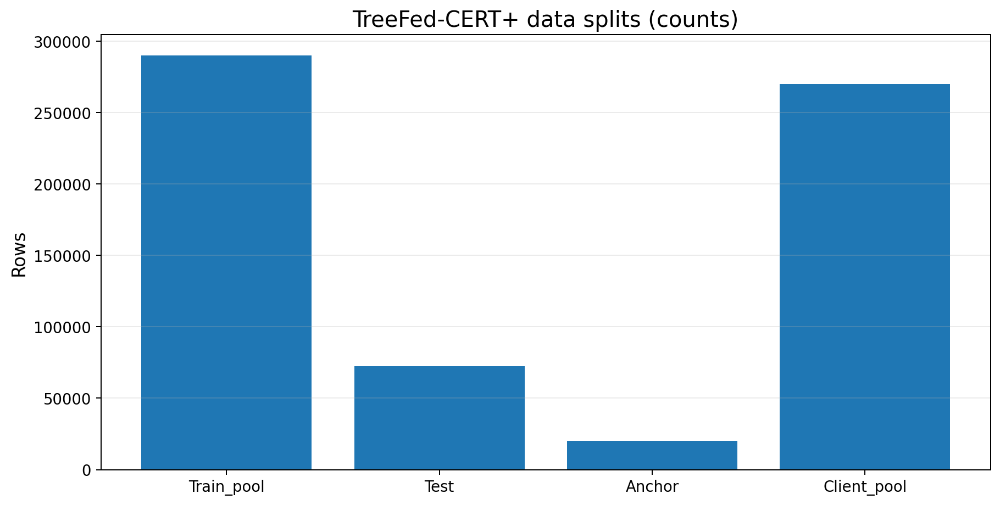

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/splits_counts.png


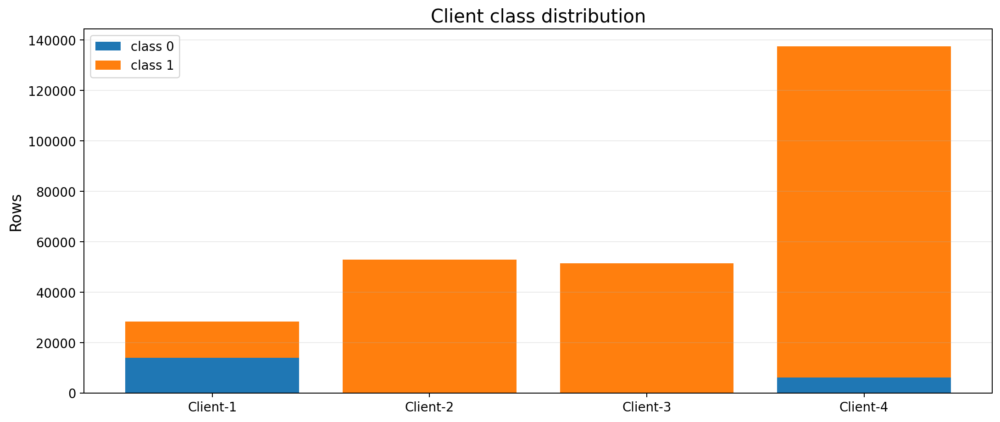

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/clients_class_stacked.png


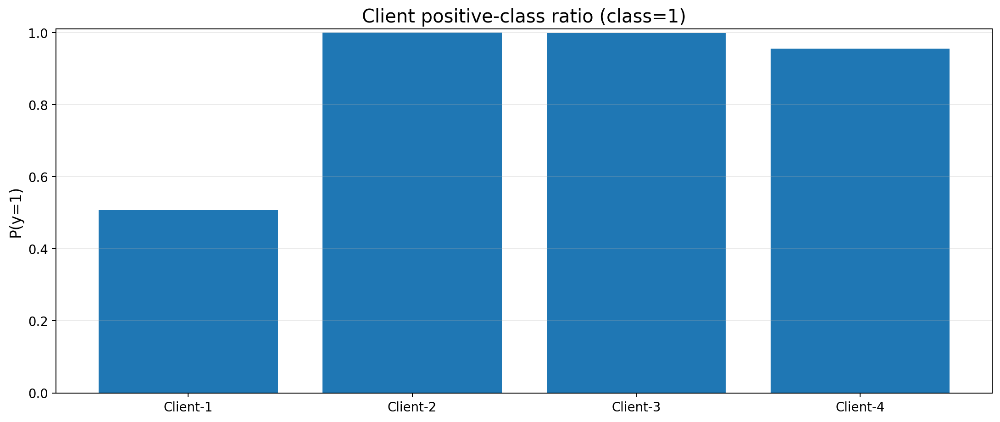

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/clients_pos_ratio.png


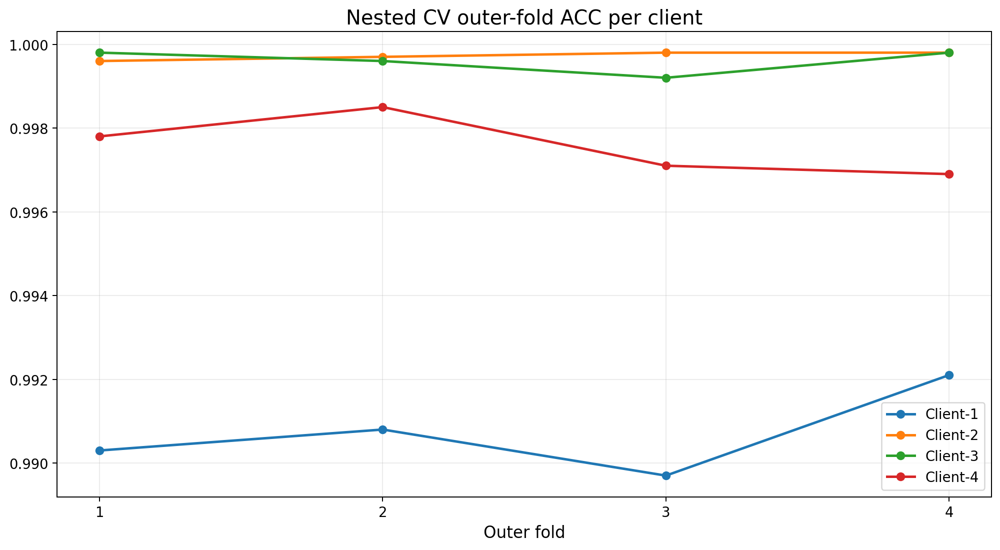

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/clients_outer_acc.png


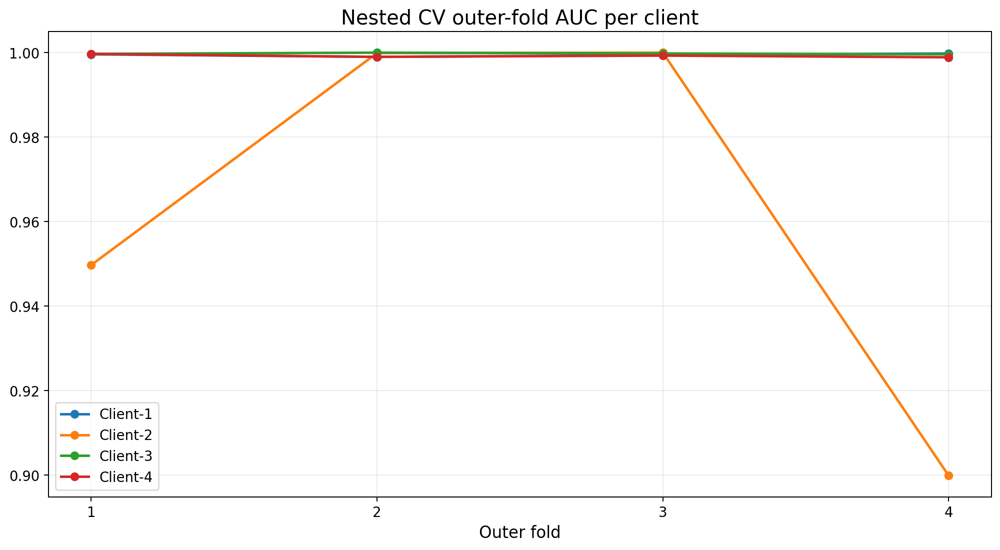

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/clients_outer_auc.png


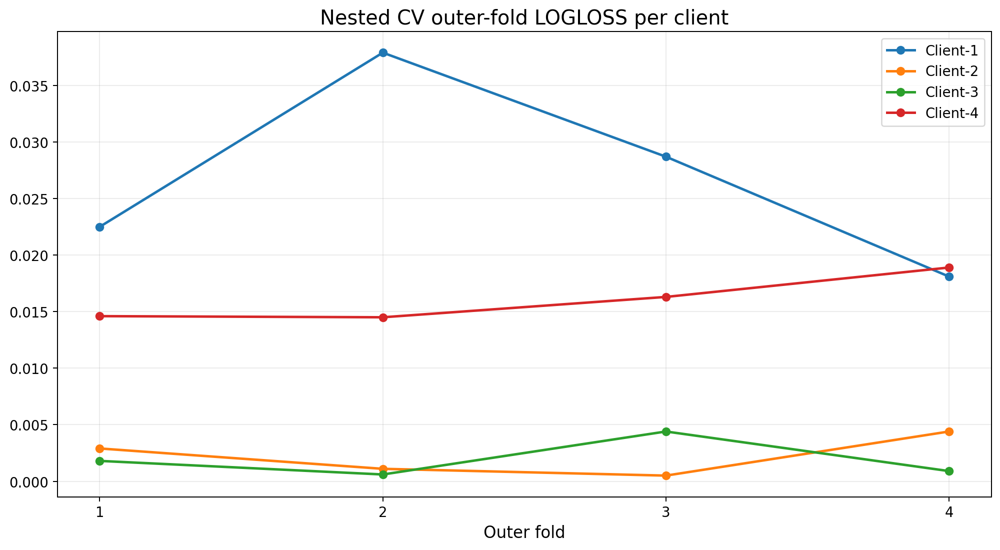

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/clients_outer_logloss.png


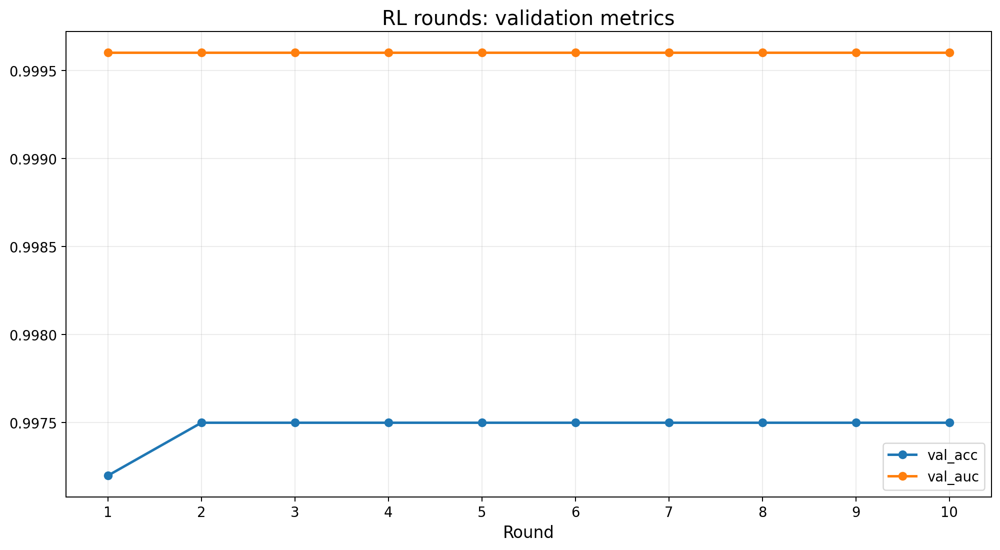

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/rl_val_metrics.png


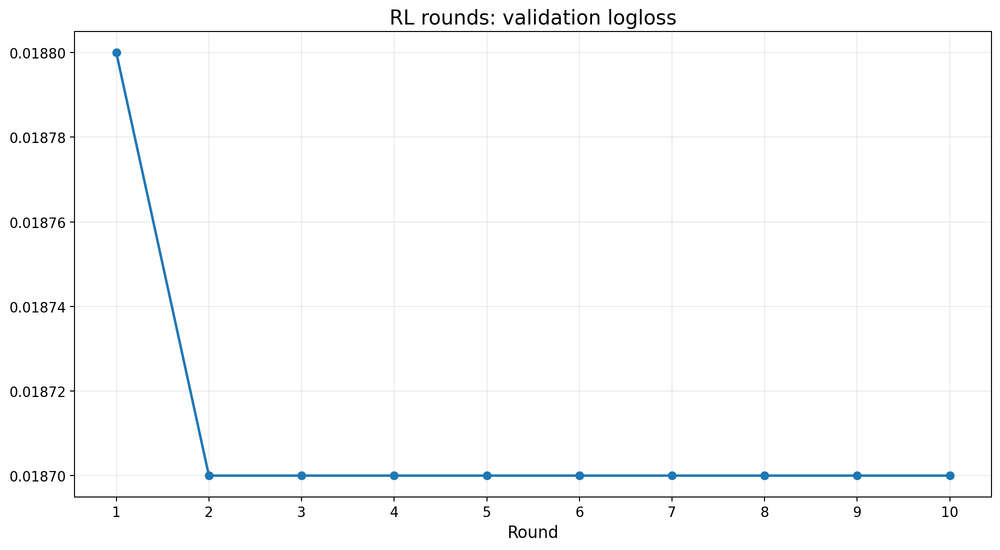

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/rl_val_logloss.png


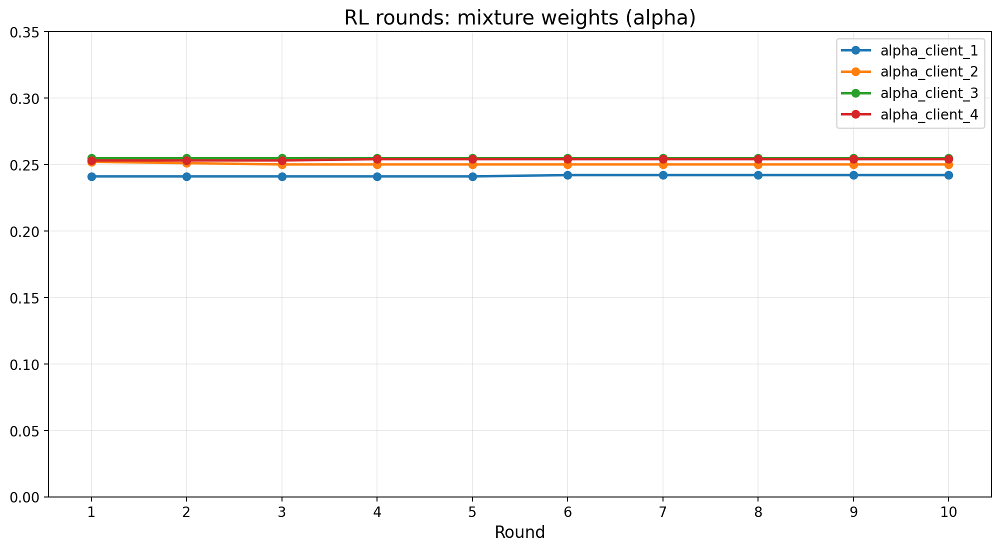

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/rl_alpha_weights.png

=== STUDENT TEST PLOTS ===
Note: y_true from CSV split (seed=42, stratified)


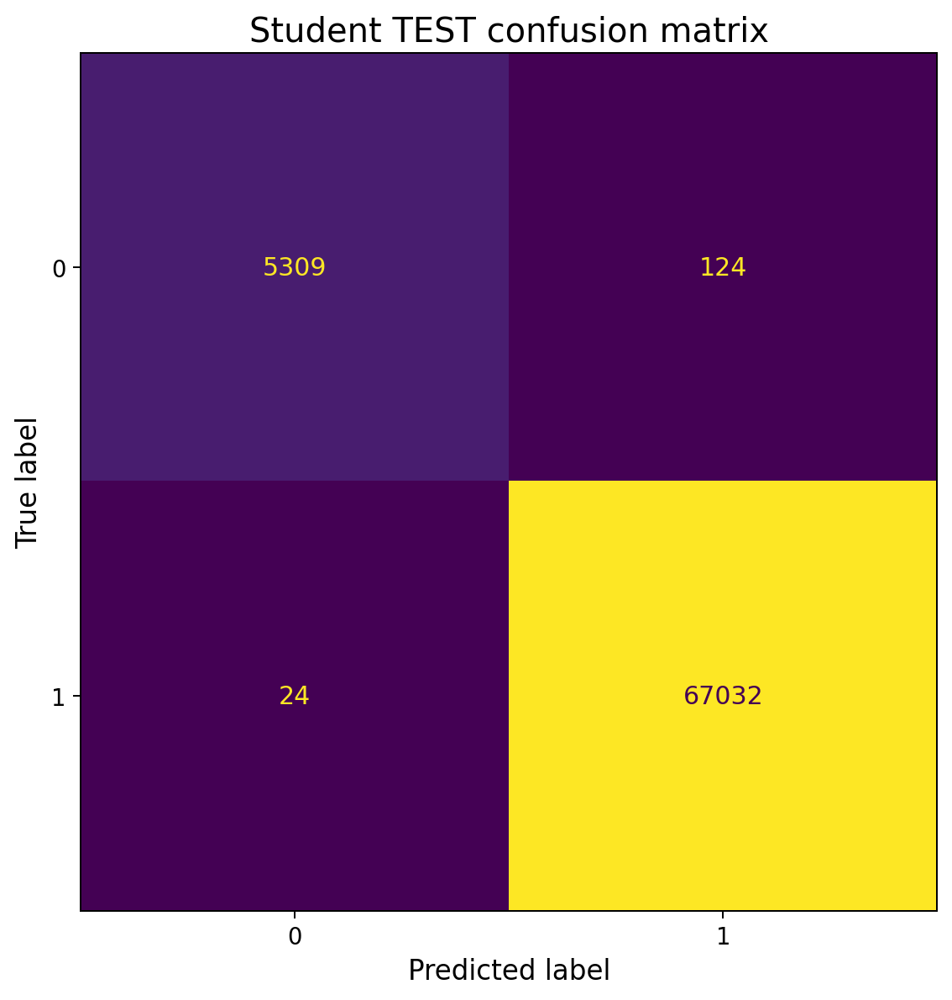

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/student_test_confusion_matrix.png


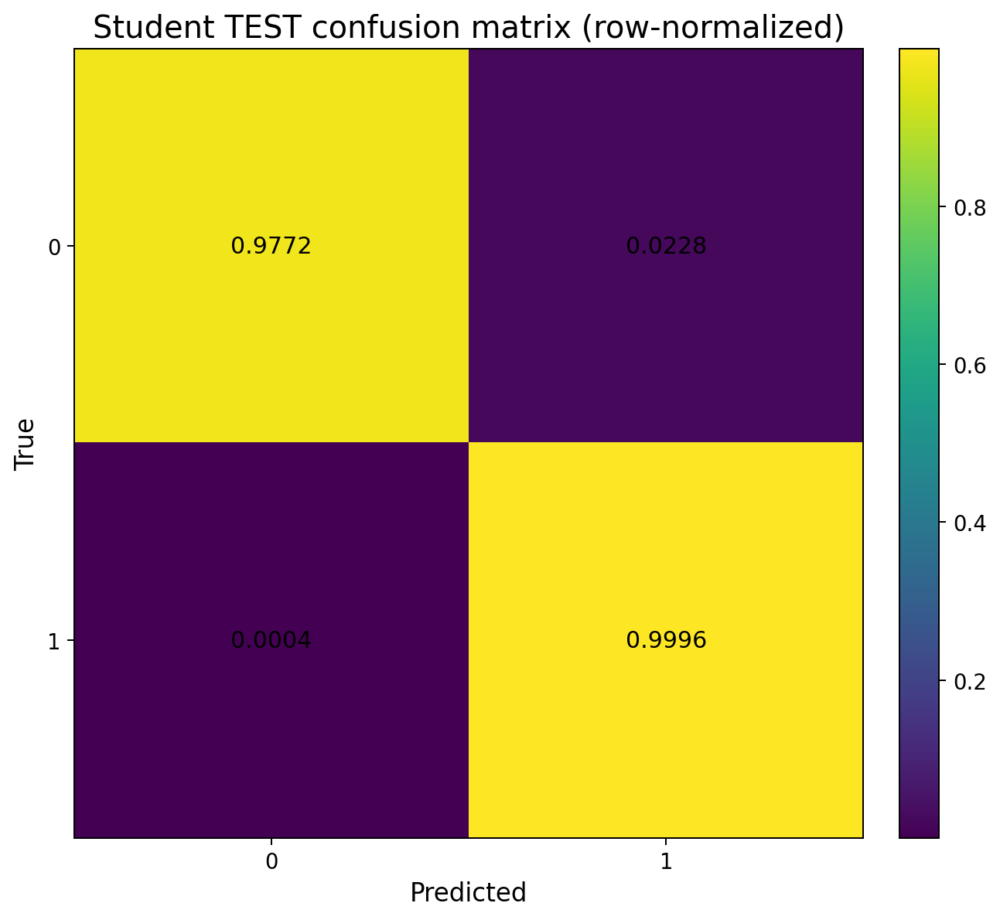

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/student_test_confusion_matrix_normalized.png


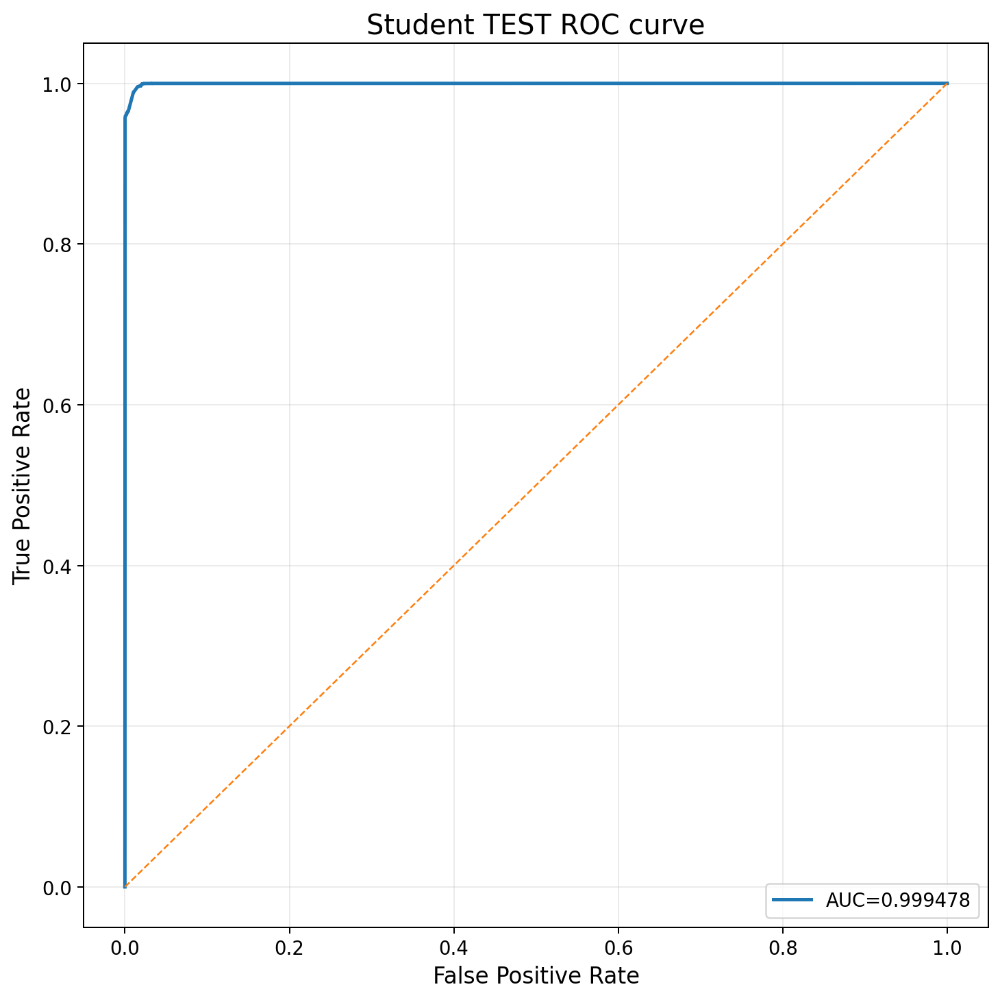

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/student_test_roc.png


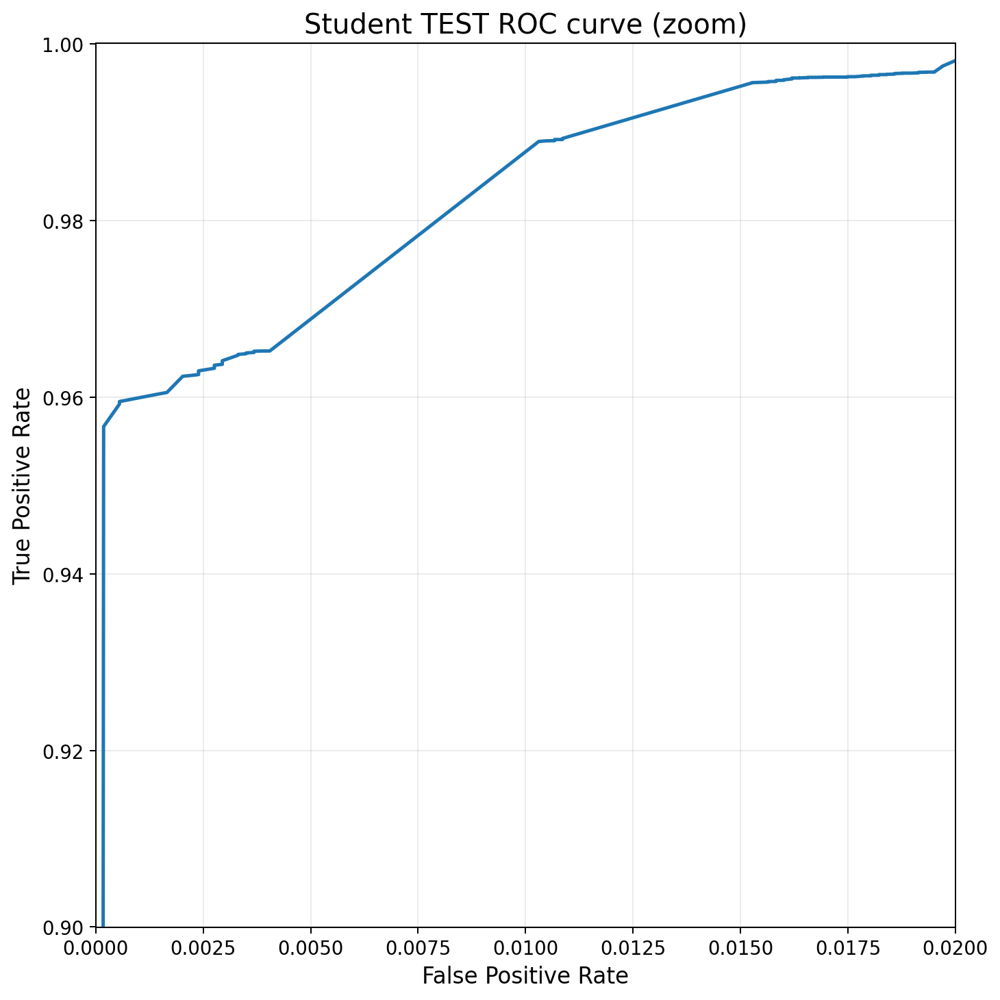

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/student_test_roc_zoom.png


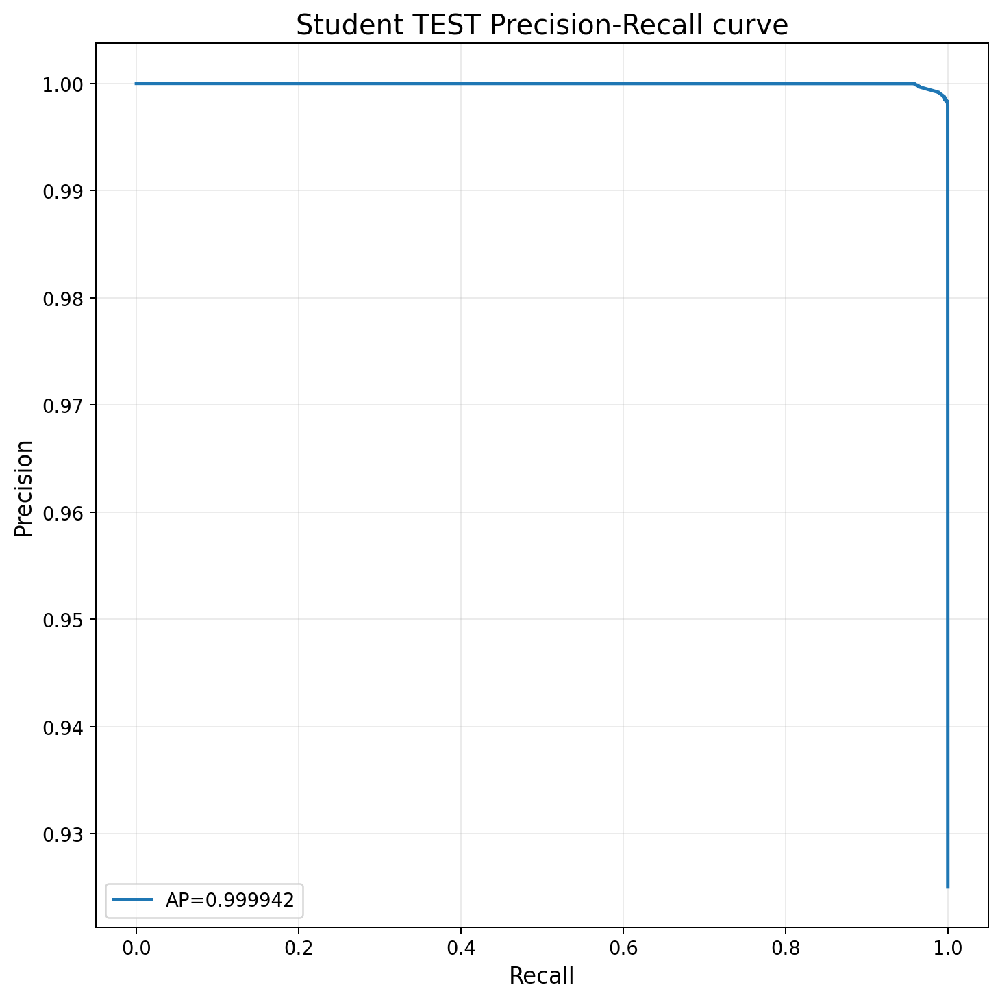

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/student_test_pr_curve.png


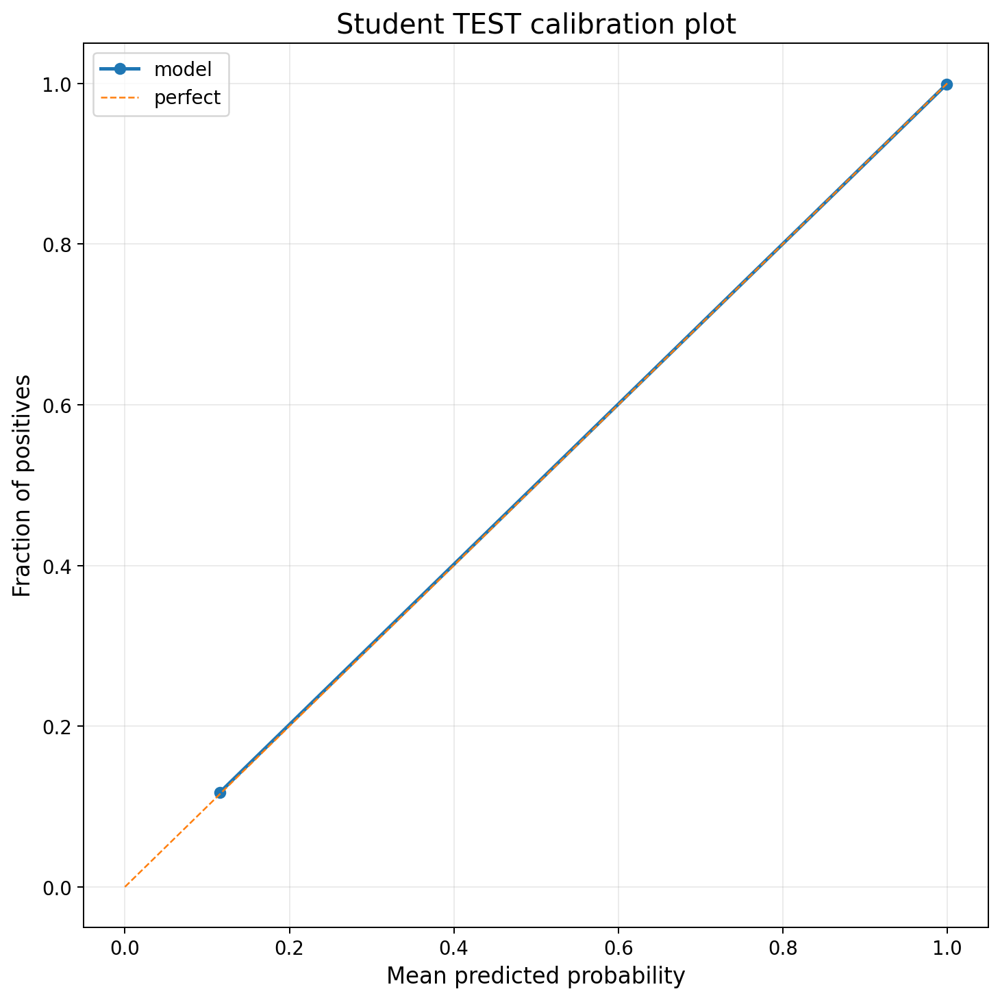

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/student_test_calibration.png


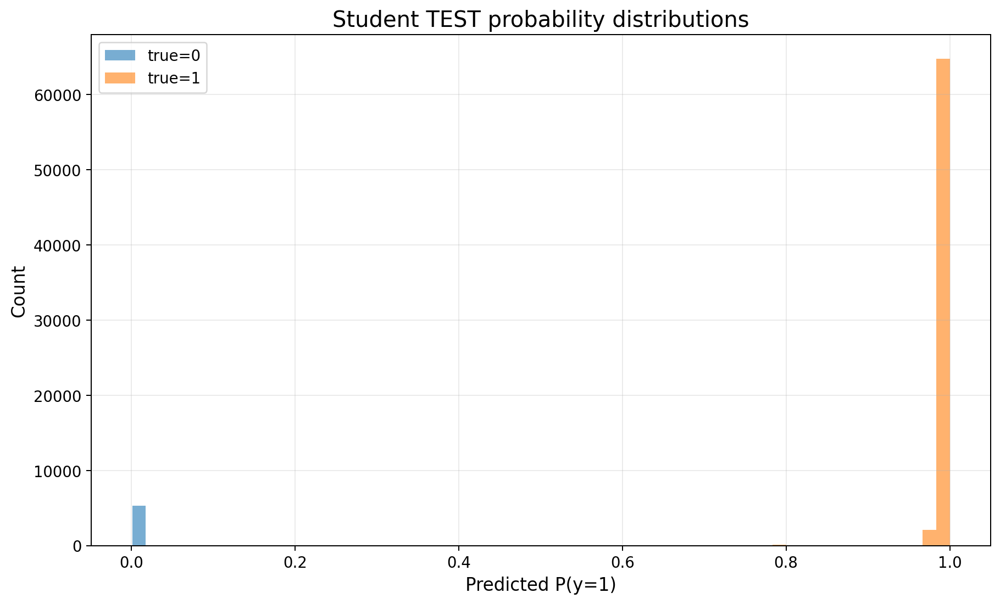

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/student_test_score_hist.png


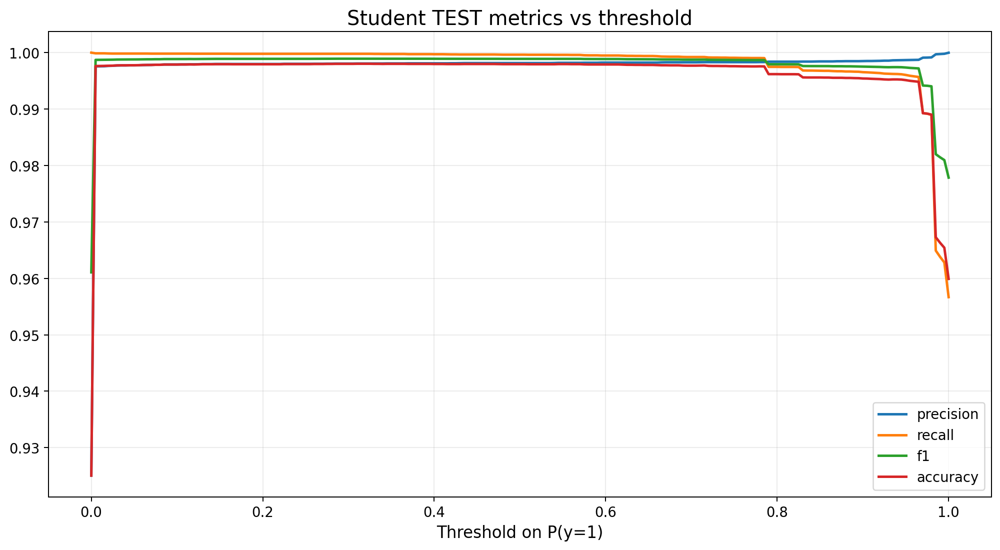

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/student_test_threshold_sweep.png


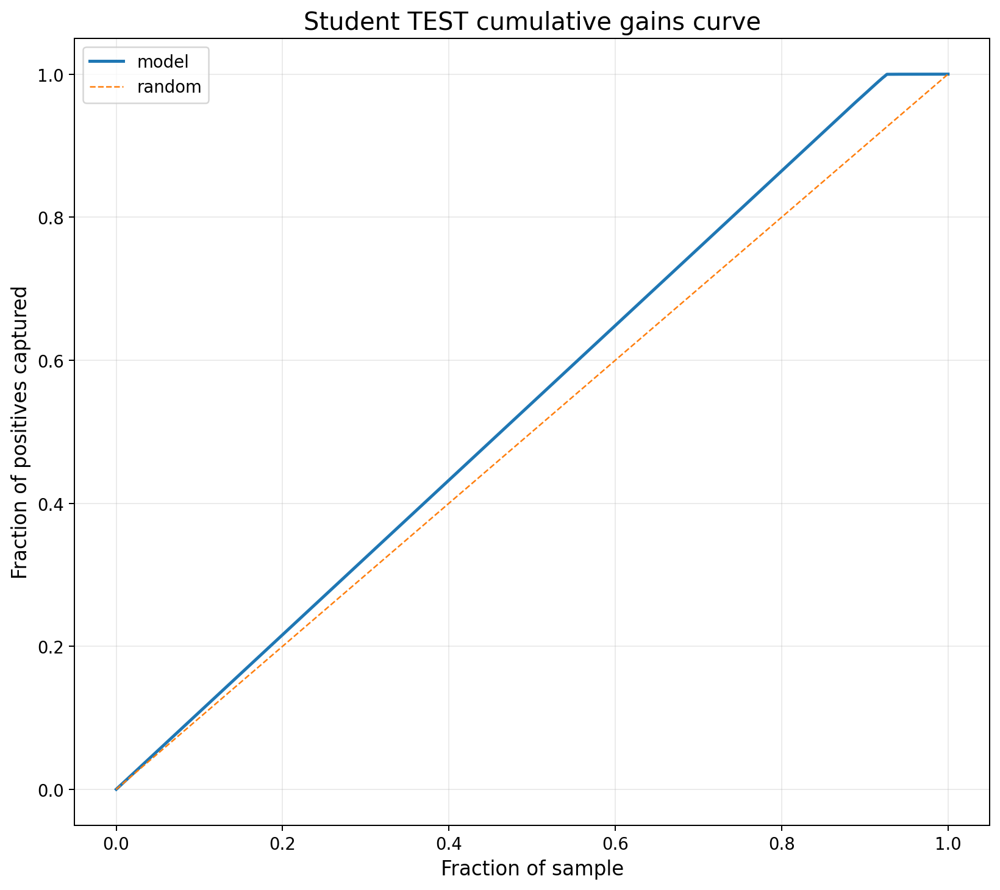

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/student_test_gains.png


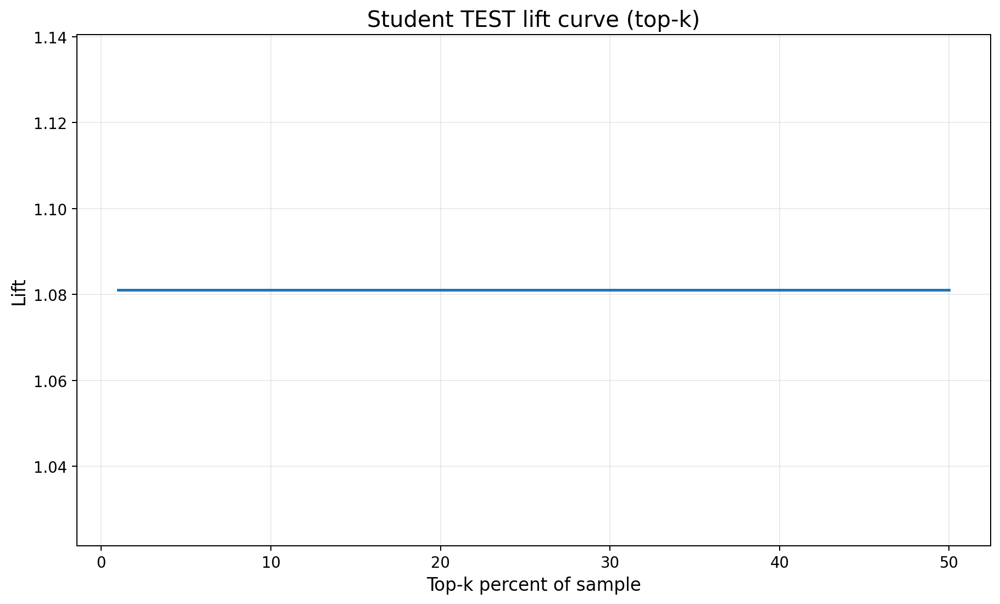

Saved: treefed_cert_run/treefed_20251217_160455/plots_student/student_test_lift.png

Recomputed (from extracted proba): acc= 0.997958310916139 prec= 0.9981535529215558 rec= 0.9996420901932713 f1= 0.9988972670104015 auc= 0.9994779878112595 logloss= 0.0091254580278533

All plots saved to: treefed_cert_run/treefed_20251217_160455/plots_student


In [6]:
import os, pickle, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score,
    precision_score, recall_score, f1_score, accuracy_score, log_loss
)
from sklearn.calibration import calibration_curve

# ============================================================
# CONFIG (set these)
# ============================================================
RUN_DIR = "treefed_cert_run/treefed_20251217_160455"
ARTIFACTS_PKL = os.path.join(RUN_DIR, "artifacts.pkl")

DATA_PATH = "dataset_1_cleaned.csv"   # used only if artifacts lack y_true/y_pred
TARGET_COL = "Label"
SEED = 42
TEST_SIZE = 0.20

# Your reported Student (Stacking) TEST metrics (used for reconstruction fallback)
STUDENT_REPORTED = {
    "accuracy": 0.9980,
    "precision": 0.9982,
    "recall": 0.9996,
    "f1": 0.9989,
    "auc": 0.9996,
    "logloss": 0.0089,
}

# from your log (for plotting)
TEST_N = 72489

# ============================================================
# Plot quality (sharp + clean)
# ============================================================
plt.rcParams.update({
    "figure.dpi": 180,
    "savefig.dpi": 520,
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
})

PLOT_DIR = os.path.join(RUN_DIR, "plots_student")
os.makedirs(PLOT_DIR, exist_ok=True)

def save_show(fig, name):
    path = os.path.join(PLOT_DIR, name)
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved:", path)

# ============================================================
# 1) Utility: robustly search artifacts.pkl for arrays
# ============================================================
def to_numpy(x):
    try:
        import torch
        if isinstance(x, torch.Tensor):
            return x.detach().cpu().numpy()
    except Exception:
        pass
    if isinstance(x, pd.Series):
        return x.values
    if isinstance(x, pd.DataFrame):
        return x.values
    if isinstance(x, np.ndarray):
        return x
    if isinstance(x, (list, tuple)):
        try:
            return np.asarray(x)
        except Exception:
            return None
    return None

def walk_arrays(obj, path="root", out=None):
    if out is None: out = []
    if isinstance(obj, dict):
        for k, v in obj.items():
            walk_arrays(v, path + f".{k}", out)
    elif isinstance(obj, (list, tuple)):
        for i, v in enumerate(obj):
            walk_arrays(v, path + f"[{i}]", out)
    else:
        arr = to_numpy(obj)
        if arr is not None and hasattr(arr, "shape"):
            out.append((path, arr))
    return out

def score_path(p, must_words=None):
    p = p.lower()
    s = 0
    for w in ["student", "stack", "test", "proba", "prob", "pred", "y_test", "ytrue", "labels"]:
        if w in p: s += 2
    if must_words:
        for w in must_words:
            if w in p: s += 5
    return s

def find_best_student_test_arrays(art, test_n=TEST_N):
    found = walk_arrays(art)

    # candidates
    y_cands = []
    pred_cands = []
    proba_cands = []

    for p, a in found:
        a = np.asarray(a)
        if a.ndim == 1 and a.shape[0] == test_n:
            # possible y or pred
            uniq = np.unique(a[~np.isnan(a)] if np.issubdtype(a.dtype, np.floating) else a)
            if len(uniq) <= 10:
                y_cands.append((p, a))
                pred_cands.append((p, a))
        if a.ndim == 2 and a.shape[0] == test_n and a.shape[1] in (2,):
            proba_cands.append((p, a))

    # rank by path score
    y_cands = sorted(y_cands, key=lambda x: score_path(x[0], ["test"]), reverse=True)
    pred_cands = sorted(pred_cands, key=lambda x: score_path(x[0], ["student","test","pred"]), reverse=True)
    proba_cands = sorted(proba_cands, key=lambda x: score_path(x[0], ["student","test","proba"]), reverse=True)

    y_true = None
    y_pred = None
    proba = None

    # pick proba first (best signal)
    if proba_cands:
        proba = proba_cands[0]
    # pick y_true with best score
    if y_cands:
        y_true = y_cands[0]
    # pick y_pred (optional)
    if pred_cands:
        y_pred = pred_cands[0]

    # try to ensure y_true is actually labels (0/1)
    def is_binary01(v):
        v = np.asarray(v).astype(int)
        u = np.unique(v)
        return set(u.tolist()).issubset({0,1})

    if y_true is not None and not is_binary01(y_true[1]):
        # search for any binary vector among y_cands
        for p, a in y_cands:
            if is_binary01(a):
                y_true = (p, a)
                break

    if y_pred is not None and not is_binary01(y_pred[1]):
        for p, a in pred_cands:
            if is_binary01(a):
                y_pred = (p, a)
                break

    return y_true, y_pred, proba

# ============================================================
# 2) Fallback: reconstruct confusion matrix from metrics + test counts
# ============================================================
def reconstruct_cm_from_metrics(N, pos, precision, recall):
    # real-valued counts
    TP = recall * pos
    FP = TP * (1.0/precision - 1.0) if precision > 0 else 0.0
    FN = pos - TP
    neg = N - pos
    TN = neg - FP

    # round carefully and enforce constraints
    TP_i = int(round(TP))
    FP_i = int(round(FP))
    FN_i = int(round(FN))
    TN_i = int(round(TN))

    # fix negatives
    TP_i = max(0, TP_i)
    FP_i = max(0, FP_i)
    FN_i = max(0, FN_i)
    TN_i = max(0, TN_i)

    # enforce totals (small adjustments)
    # adjust to match pos and N
    # ensure TP+FN = pos
    diff_pos = pos - (TP_i + FN_i)
    if diff_pos != 0:
        FN_i += diff_pos
        FN_i = max(0, FN_i)

    # ensure FP+TN = neg
    neg = N - pos
    diff_neg = neg - (FP_i + TN_i)
    if diff_neg != 0:
        TN_i += diff_neg
        TN_i = max(0, TN_i)

    cm = np.array([[TN_i, FP_i],
                   [FN_i, TP_i]], dtype=int)
    return cm

# ============================================================
# 3) Load artifacts (if exists) and/or compute test counts
# ============================================================
y_true = None
y_pred = None
proba_pos = None
source_note = None

if os.path.exists(ARTIFACTS_PKL):
    print("Loading:", ARTIFACTS_PKL)
    with open(ARTIFACTS_PKL, "rb") as f:
        art = pickle.load(f)

    y_t, y_p, p2 = find_best_student_test_arrays(art, test_n=TEST_N)

    if y_t is not None:
        print("Found y_true:", y_t[0], "shape:", np.asarray(y_t[1]).shape)
        y_true = np.asarray(y_t[1]).astype(int)

    if y_p is not None:
        print("Found y_pred:", y_p[0], "shape:", np.asarray(y_p[1]).shape)
        y_pred = np.asarray(y_p[1]).astype(int)

    if p2 is not None:
        print("Found proba:", p2[0], "shape:", np.asarray(p2[1]).shape)
        proba = np.asarray(p2[1], dtype=float)
        proba_pos = proba[:, 1]
else:
    print("artifacts.pkl not found:", ARTIFACTS_PKL)

# If y_true missing, compute from dataset split (only needs CSV)
test_pos = None
if y_true is None:
    if os.path.exists(DATA_PATH):
        print("\nComputing y_test from CSV split (for confusion-matrix reconstruction fallback)...")
        df0 = pd.read_csv(DATA_PATH, low_memory=False)
        y0 = df0[TARGET_COL].astype(int).values
        X0 = df0.drop(columns=[TARGET_COL])

        _, X_test0, _, y_test0 = train_test_split(
            X0, y0, test_size=TEST_SIZE, random_state=SEED, stratify=y0
        )
        if len(y_test0) != TEST_N:
            print("Warning: split produced test size", len(y_test0), "but expected", TEST_N)
        y_true = y_test0.astype(int)
        source_note = "y_true from CSV split (seed=42, stratified)"
    else:
        print("CSV not found:", DATA_PATH)

# If y_pred missing but proba exists -> derive with 0.5 threshold
if y_pred is None and proba_pos is not None:
    y_pred = (proba_pos >= 0.5).astype(int)

# If still missing y_pred or proba, reconstruct CM from reported precision/recall + test counts
cm = None
if y_true is not None:
    test_pos = int((y_true == 1).sum())
    if (y_pred is None) and (proba_pos is None):
        cm = reconstruct_cm_from_metrics(
            N=len(y_true),
            pos=test_pos,
            precision=STUDENT_REPORTED["precision"],
            recall=STUDENT_REPORTED["recall"]
        )
        source_note = "confusion matrix reconstructed from reported precision/recall + true test class counts"
else:
    print("Cannot build confusion matrix: y_true not available.")
    source_note = "no y_true available"

# ============================================================
# 4) PLOTS FROM YOUR RUN OUTPUTS (clients, RL, student)
# ============================================================

# ---- A) Split sizes plot (from your printed shapes) ----
split_sizes = {
    "Train_pool": 289956,
    "Test": 72489,
    "Anchor": 20000,
    "Client_pool": 269956
}
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.bar(list(split_sizes.keys()), list(split_sizes.values()))
ax.set_title("TreeFed-CERT+ data splits (counts)")
ax.set_ylabel("Rows")
ax.grid(True, axis="y", alpha=0.25)
save_show(fig, "splits_counts.png")

# ---- B) Client size + class ratio plot (from your printed dists) ----
clients = {
    "Client-1": (28366, 13973, 14393),
    "Client-2": (52838, 39, 52799),
    "Client-3": (51331, 86, 51245),
    "Client-4": (137421, 6136, 131285),
}
client_names = list(clients.keys())
n = np.array([clients[k][0] for k in client_names])
n0 = np.array([clients[k][1] for k in client_names])
n1 = np.array([clients[k][2] for k in client_names])

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
ax.bar(client_names, n0, label="class 0")
ax.bar(client_names, n1, bottom=n0, label="class 1")
ax.set_title("Client class distribution")
ax.set_ylabel("Rows")
ax.grid(True, axis="y", alpha=0.25)
ax.legend()
save_show(fig, "clients_class_stacked.png")

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
ratio1 = n1 / n
ax.bar(client_names, ratio1)
ax.set_title("Client positive-class ratio (class=1)")
ax.set_ylabel("P(y=1)")
ax.set_ylim(0, 1.01)
ax.grid(True, axis="y", alpha=0.25)
save_show(fig, "clients_pos_ratio.png")

# ---- C) Nested CV per-client outer fold plots (from your printed metrics) ----
client_outer = {
    "Client-1": {"acc":[0.9903,0.9908,0.9897,0.9921], "auc":[0.9996,0.9990,0.9994,0.9998], "logloss":[0.0225,0.0379,0.0287,0.0181]},
    "Client-2": {"acc":[0.9996,0.9997,0.9998,0.9998], "auc":[0.9497,0.9999,1.0000,0.8998], "logloss":[0.0029,0.0011,0.0005,0.0044]},
    "Client-3": {"acc":[0.9998,0.9996,0.9992,0.9998], "auc":[0.9997,1.0000,0.9998,0.9996], "logloss":[0.0018,0.0006,0.0044,0.0009]},
    "Client-4": {"acc":[0.9978,0.9985,0.9971,0.9969], "auc":[0.9997,0.9990,0.9993,0.9989], "logloss":[0.0146,0.0145,0.0163,0.0189]},
}
folds = np.arange(1, 5)

for metric in ["acc","auc","logloss"]:
    fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)
    for cname, dd in client_outer.items():
        ax.plot(folds, dd[metric], marker="o", linewidth=2, label=cname)
    ax.set_title(f"Nested CV outer-fold {metric.upper()} per client")
    ax.set_xlabel("Outer fold")
    ax.set_xticks(folds)
    ax.grid(True, alpha=0.25)
    ax.legend()
    save_show(fig, f"clients_outer_{metric}.png")

# ---- D) RL rounds plots (from your printed history) ----
rl_acc = [0.9972,0.9975,0.9975,0.9975,0.9975,0.9975,0.9975,0.9975,0.9975,0.9975]
rl_auc = [0.9996]*10
rl_logloss = [0.0188,0.0187,0.0187,0.0187,0.0187,0.0187,0.0187,0.0187,0.0187,0.0187]
alpha = np.array([
    [0.241,0.252,0.255,0.253],
    [0.241,0.251,0.255,0.253],
    [0.241,0.250,0.255,0.253],
    [0.241,0.250,0.255,0.254],
    [0.241,0.250,0.255,0.254],
    [0.242,0.250,0.255,0.254],
    [0.242,0.250,0.255,0.254],
    [0.242,0.250,0.255,0.254],
    [0.242,0.250,0.255,0.254],
    [0.242,0.250,0.255,0.254],
], dtype=float)

rounds = np.arange(1, 11)

fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)
ax.plot(rounds, rl_acc, marker="o", linewidth=2, label="val_acc")
ax.plot(rounds, rl_auc, marker="o", linewidth=2, label="val_auc")
ax.set_title("RL rounds: validation metrics")
ax.set_xlabel("Round")
ax.set_xticks(rounds)
ax.grid(True, alpha=0.25)
ax.legend()
save_show(fig, "rl_val_metrics.png")

fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)
ax.plot(rounds, rl_logloss, marker="o", linewidth=2)
ax.set_title("RL rounds: validation logloss")
ax.set_xlabel("Round")
ax.set_xticks(rounds)
ax.grid(True, alpha=0.25)
save_show(fig, "rl_val_logloss.png")

fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)
for i in range(4):
    ax.plot(rounds, alpha[:, i], marker="o", linewidth=2, label=f"alpha_client_{i+1}")
ax.set_title("RL rounds: mixture weights (alpha)")
ax.set_xlabel("Round")
ax.set_xticks(rounds)
ax.set_ylim(0, 0.35)
ax.grid(True, alpha=0.25)
ax.legend()
save_show(fig, "rl_alpha_weights.png")

# ============================================================
# 5) STUDENT TEST PLOTS (confusion matrix guaranteed)
# ============================================================
print("\n=== STUDENT TEST PLOTS ===")
print("Note:", source_note)

# ---- Confusion matrix (exact if y_pred exists; else reconstructed) ----
if y_true is not None:
    if cm is None:
        cm = confusion_matrix(y_true, y_pred, labels=[0,1])

    fig, ax = plt.subplots(figsize=(7.5, 6.5), constrained_layout=True)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1])
    disp.plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title("Student TEST confusion matrix")
    save_show(fig, "student_test_confusion_matrix.png")

    # normalized
    cmn = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1e-12)
    fig, ax = plt.subplots(figsize=(7.5, 6.5), constrained_layout=True)
    im = ax.imshow(cmn, interpolation="nearest")
    ax.set_xticks([0,1]); ax.set_yticks([0,1])
    ax.set_xticklabels([0,1]); ax.set_yticklabels([0,1])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title("Student TEST confusion matrix (row-normalized)")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cmn[i,j]:.4f}", ha="center", va="center", fontsize=12)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    save_show(fig, "student_test_confusion_matrix_normalized.png")

    # ---- If probabilities exist, do real ROC/PR/calibration/threshold plots ----
    if proba_pos is not None and y_true is not None:
        # ROC
        fpr, tpr, thr = roc_curve(y_true, proba_pos)
        auc_val = roc_auc_score(y_true, proba_pos)
        fig, ax = plt.subplots(figsize=(8, 8), constrained_layout=True)
        ax.plot(fpr, tpr, linewidth=2, label=f"AUC={auc_val:.6f}")
        ax.plot([0,1],[0,1], linestyle="--", linewidth=1)
        ax.set_xlabel("False Positive Rate")
        ax.set_ylabel("True Positive Rate")
        ax.set_title("Student TEST ROC curve")
        ax.grid(True, alpha=0.25)
        ax.legend()
        save_show(fig, "student_test_roc.png")

        # ROC zoom
        fig, ax = plt.subplots(figsize=(8, 8), constrained_layout=True)
        ax.plot(fpr, tpr, linewidth=2)
        ax.plot([0,1],[0,1], linestyle="--", linewidth=1)
        ax.set_xlim(0, 0.02)
        ax.set_ylim(0.90, 1.0001)
        ax.set_xlabel("False Positive Rate")
        ax.set_ylabel("True Positive Rate")
        ax.set_title("Student TEST ROC curve (zoom)")
        ax.grid(True, alpha=0.25)
        save_show(fig, "student_test_roc_zoom.png")

        # PR curve
        prec, rec, thr_pr = precision_recall_curve(y_true, proba_pos)
        ap = average_precision_score(y_true, proba_pos)
        fig, ax = plt.subplots(figsize=(8, 8), constrained_layout=True)
        ax.plot(rec, prec, linewidth=2, label=f"AP={ap:.6f}")
        ax.set_xlabel("Recall")
        ax.set_ylabel("Precision")
        ax.set_title("Student TEST Precision-Recall curve")
        ax.grid(True, alpha=0.25)
        ax.legend()
        save_show(fig, "student_test_pr_curve.png")

        # calibration (reliability diagram)
        frac_pos, mean_pred = calibration_curve(y_true, proba_pos, n_bins=12, strategy="quantile")
        fig, ax = plt.subplots(figsize=(8, 8), constrained_layout=True)
        ax.plot(mean_pred, frac_pos, marker="o", linewidth=2, label="model")
        ax.plot([0,1],[0,1], linestyle="--", linewidth=1, label="perfect")
        ax.set_xlabel("Mean predicted probability")
        ax.set_ylabel("Fraction of positives")
        ax.set_title("Student TEST calibration plot")
        ax.grid(True, alpha=0.25)
        ax.legend()
        save_show(fig, "student_test_calibration.png")

        # score distributions
        fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
        ax.hist(proba_pos[y_true==0], bins=60, alpha=0.6, label="true=0")
        ax.hist(proba_pos[y_true==1], bins=60, alpha=0.6, label="true=1")
        ax.set_title("Student TEST probability distributions")
        ax.set_xlabel("Predicted P(y=1)")
        ax.set_ylabel("Count")
        ax.grid(True, alpha=0.25)
        ax.legend()
        save_show(fig, "student_test_score_hist.png")

        # threshold sweep (precision/recall/f1/acc)
        thresholds = np.linspace(0.0, 1.0, 201)
        P, R, F1, ACC = [], [], [], []
        for t in thresholds:
            yp = (proba_pos >= t).astype(int)
            P.append(precision_score(y_true, yp, zero_division=0))
            R.append(recall_score(y_true, yp, zero_division=0))
            F1.append(f1_score(y_true, yp, zero_division=0))
            ACC.append(accuracy_score(y_true, yp))
        fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)
        ax.plot(thresholds, P, linewidth=2, label="precision")
        ax.plot(thresholds, R, linewidth=2, label="recall")
        ax.plot(thresholds, F1, linewidth=2, label="f1")
        ax.plot(thresholds, ACC, linewidth=2, label="accuracy")
        ax.set_title("Student TEST metrics vs threshold")
        ax.set_xlabel("Threshold on P(y=1)")
        ax.grid(True, alpha=0.25)
        ax.legend()
        save_show(fig, "student_test_threshold_sweep.png")

        # gains curve
        order = np.argsort(-proba_pos)
        y_sorted = y_true[order]
        cum_pos = np.cumsum(y_sorted)
        total_pos = max(1, cum_pos[-1])
        x = np.arange(1, len(y_sorted)+1) / len(y_sorted)
        y_gain = cum_pos / total_pos

        fig, ax = plt.subplots(figsize=(9, 8), constrained_layout=True)
        ax.plot(x, y_gain, linewidth=2, label="model")
        ax.plot([0,1],[0,1], linestyle="--", linewidth=1, label="random")
        ax.set_title("Student TEST cumulative gains curve")
        ax.set_xlabel("Fraction of sample")
        ax.set_ylabel("Fraction of positives captured")
        ax.grid(True, alpha=0.25)
        ax.legend()
        save_show(fig, "student_test_gains.png")

        # lift curve (top-k lift)
        # lift at each percentile = (positives rate in top-k) / (overall positive rate)
        overall_rate = y_true.mean()
        topk = np.linspace(0.01, 0.50, 50)
        lifts = []
        for k in topk:
            m = max(1, int(round(k*len(y_true))))
            rate_top = y_sorted[:m].mean()
            lifts.append(rate_top / max(1e-12, overall_rate))
        fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
        ax.plot(topk*100, lifts, linewidth=2)
        ax.set_title("Student TEST lift curve (top-k)")
        ax.set_xlabel("Top-k percent of sample")
        ax.set_ylabel("Lift")
        ax.grid(True, alpha=0.25)
        save_show(fig, "student_test_lift.png")

        # quick metric recompute (sanity)
        try:
            ll = log_loss(y_true, np.column_stack([1-proba_pos, proba_pos]), labels=[0,1])
            print("\nRecomputed (from extracted proba):",
                  "acc=", accuracy_score(y_true, (proba_pos>=0.5).astype(int)),
                  "prec=", precision_score(y_true, (proba_pos>=0.5).astype(int), zero_division=0),
                  "rec=", recall_score(y_true, (proba_pos>=0.5).astype(int), zero_division=0),
                  "f1=", f1_score(y_true, (proba_pos>=0.5).astype(int), zero_division=0),
                  "auc=", roc_auc_score(y_true, proba_pos),
                  "logloss=", ll)
        except Exception as e:
            print("Metric recompute skipped:", str(e))

    else:
        print("\nNo student test probabilities found -> ROC/PR/Calibration/Threshold plots skipped.")
        print("Confusion matrix still produced (exact if y_pred exists; else reconstructed).")
else:
    print("Student confusion matrix skipped: y_true unavailable.")

print("\nAll plots saved to:", PLOT_DIR)


# **Our Model TreeFed-CERT+  vs Other Models to compare**

In [3]:
# ============================================================
# QUICK BASELINES++ (NO NESTED CV / NO TUNING)
# ------------------------------------------------------------
# +10 ML models, +4 DL models, +2 Transformer models
# Metrics: accuracy, AUC (binary OR macro-OVR), precision, recall, f1, logloss
# ============================================================

# --- installs (Colab friendly) ---
!pip -q install -U catboost xgboost lightgbm

import os, math, random, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss, roc_auc_score

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier,
    GradientBoostingClassifier, AdaBoostClassifier, BaggingClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


# =========================
# CONFIG (speed knobs)
# =========================
CFG = {
    "data_path": "dataset_1_cleaned.csv",
    "target_col": "Label",
    "seed": 42,
    "test_size": 0.20,

    # preprocessing
    "topk": 4,  # top-4 + OTHER
    "device": "cuda" if torch.cuda.is_available() else "cpu",

    # forest / boosting sizes
    "rf_n_estimators": 250,
    "et_n_estimators": 400,
    "xgb_n_estimators": 400,
    "lgb_n_estimators": 600,

    # optional caps for *slow-ish* ML models (set None for full)
    "mlp_sklearn_max_train_rows": 150000,
    "qda_max_train_rows": 200000,
    "lda_max_train_rows": 250000,

    # DL speed knobs (set None to use full train; recommended to cap on Colab Free)
    "dl_max_train_rows": 150000,   # None or int
    "dl_epochs": 3,
    "dl_batch_size": 4096,
    "dl_lr": 1e-3,

    # DL dims
    "dl_emb_dim": 16,
    "dl_hidden": 128,
    "dl_drop": 0.2,

    # Transformer dims (light)
    "tr_d_model": 32,
    "tr_nhead": 4,
    "tr_nlayers": 2,
    "tr_dim_ff": 128,
    "tr_drop": 0.1,
}

random.seed(CFG["seed"])
np.random.seed(CFG["seed"])
torch.manual_seed(CFG["seed"])

print("Device:", CFG["device"])


# =========================
# Helpers
# =========================
def safe_proba(proba, eps=1e-12):
    proba = np.asarray(proba, dtype=float)
    proba = np.clip(proba, eps, 1.0)
    proba = proba / (proba.sum(axis=1, keepdims=True) + eps)
    return proba

def align_proba(model_classes, proba, classes_all):
    proba = np.asarray(proba, dtype=float)
    out = np.zeros((proba.shape[0], len(classes_all)), dtype=float)
    idx = {c: i for i, c in enumerate(classes_all)}
    for j, c in enumerate(model_classes):
        out[:, idx[c]] = proba[:, j]
    return safe_proba(out)

def compute_auc(y_true, proba, classes_all):
    classes_all = np.asarray(classes_all)
    idx = {c: i for i, c in enumerate(classes_all)}
    y_idx = np.array([idx[c] for c in y_true], dtype=int)

    K = len(classes_all)
    proba = safe_proba(proba)

    try:
        if K == 2:
            return float(roc_auc_score(y_idx, proba[:, 1]))
        else:
            # macro OVR for multiclass
            return float(roc_auc_score(y_idx, proba, multi_class="ovr", average="macro"))
    except Exception:
        return float("nan")

def compute_metrics(y_true, y_pred, proba, classes_all):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    classes_all = np.asarray(classes_all)

    K = len(classes_all)
    out = {}
    out["accuracy"] = float(accuracy_score(y_true, y_pred))
    out["auc"] = compute_auc(y_true, proba, classes_all)

    if K == 2:
        pos = classes_all[1]
        out["precision"] = float(precision_score(y_true, y_pred, average="binary", pos_label=pos, zero_division=0))
        out["recall"]    = float(recall_score(y_true, y_pred, average="binary", pos_label=pos, zero_division=0))
        out["f1"]        = float(f1_score(y_true, y_pred, average="binary", pos_label=pos, zero_division=0))
    else:
        out["precision"] = float(precision_score(y_true, y_pred, average="macro", zero_division=0))
        out["recall"]    = float(recall_score(y_true, y_pred, average="macro", zero_division=0))
        out["f1"]        = float(f1_score(y_true, y_pred, average="macro", zero_division=0))
        out["precision_weighted"] = float(precision_score(y_true, y_pred, average="weighted", zero_division=0))
        out["recall_weighted"]    = float(recall_score(y_true, y_pred, average="weighted", zero_division=0))
        out["f1_weighted"]        = float(f1_score(y_true, y_pred, average="weighted", zero_division=0))

    proba = safe_proba(proba)
    out["logloss"] = float(log_loss(y_true, proba, labels=classes_all))
    return out

def convert_object_numeric(df, object_cols, threshold=0.98):
    df = df.copy()
    moved = []
    for c in object_cols:
        s = pd.to_numeric(df[c], errors="coerce")
        ok = float(s.notna().mean())
        if ok >= threshold:
            df[c] = s
            moved.append(c)
    return df, moved

def stratified_subsample(X, y, max_rows, seed=42):
    if (max_rows is None) or (len(y) <= max_rows):
        return X, y
    df_tmp = X.copy()
    df_tmp["_y"] = y
    counts = df_tmp["_y"].value_counts()
    frac = max_rows / len(df_tmp)

    parts = []
    for cls, cnt in counts.items():
        take = max(1, int(round(cnt * frac)))
        parts.append(df_tmp[df_tmp["_y"] == cls].sample(n=take, random_state=seed))
    out = pd.concat(parts, axis=0).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    y_out = out["_y"].values
    X_out = out.drop(columns=["_y"])
    return X_out, y_out

class TopKCategory(BaseEstimator, TransformerMixin):
    """Caps each categorical col to Top-K categories; rest -> OTHER."""
    def __init__(self, topk=4):
        self.topk = int(topk)
        self.maps_ = None
        self.cols_ = None

    def fit(self, X, y=None):
        X = pd.DataFrame(X).copy()
        self.cols_ = list(X.columns)
        self.maps_ = {}
        for c in self.cols_:
            s = X[c].astype(str)
            s = s.replace(r"^\s*(?:na|n/a|none|null|nan)\s*$", np.nan, regex=True)
            s = s.replace(r"^\s*$", np.nan, regex=True)
            vc = s.dropna().value_counts()
            self.maps_[c] = set(vc.head(self.topk).index.tolist())
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        X.columns = self.cols_
        for c in self.cols_:
            s = X[c].astype(str)
            s = s.replace(r"^\s*(?:na|n/a|none|null|nan)\s*$", np.nan, regex=True)
            s = s.replace(r"^\s*$", np.nan, regex=True)
            s = s.fillna("OTHER")
            allowed = self.maps_[c]
            X[c] = s.where(s.isin(allowed), "OTHER")
        return X

def make_preprocessor(cat_cols, num_cols, topk=4, scale_num=False):
    ord_enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)

    cat_pipe = Pipeline(steps=[
        ("topk", TopKCategory(topk=topk)),
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ord", ord_enc),
    ])

    num_steps = [("imp", SimpleImputer(strategy="median"))]
    if scale_num:
        num_steps.append(("sc", StandardScaler(with_mean=True, with_std=True)))
    num_pipe = Pipeline(steps=num_steps)

    return ColumnTransformer(
        transformers=[
            ("cat", cat_pipe, cat_cols),
            ("num", num_pipe, num_cols),
        ],
        remainder="drop",
        sparse_threshold=0.0
    )

def eval_model_array(name, clf, Xtr, ytr, Xte, yte, classes_all):
    t0 = time.time()
    clf.fit(Xtr, ytr)
    y_pred = clf.predict(Xte)
    proba = clf.predict_proba(Xte)
    proba = align_proba(clf.classes_, proba, classes_all)
    m = compute_metrics(yte, y_pred, proba, classes_all)
    m["model"] = name
    m["seconds"] = round(time.time() - t0, 2)
    return m


# =========================
# LOAD DATA
# =========================
df = pd.read_csv(CFG["data_path"], low_memory=False)
assert CFG["target_col"] in df.columns

y = df[CFG["target_col"]].astype(int).values
X = df.drop(columns=[CFG["target_col"]]).copy()

obj_cols = [c for c in X.columns if X[c].dtype == "object"]
X, moved = convert_object_numeric(X, obj_cols, threshold=0.98)

cat_cols = [c for c in X.columns if X[c].dtype == "object"]
num_cols = [c for c in X.columns if c not in cat_cols]

classes_all = np.unique(y)
n_classes = len(classes_all)

print(f"Shape: {X.shape} | Cat={len(cat_cols)} | Num={len(num_cols)} | Classes={n_classes}")
if moved:
    print("Object->Numeric:", moved[:10], "..." if len(moved) > 10 else "")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=CFG["test_size"], random_state=CFG["seed"], stratify=y
)


# =========================
# PREP ONCE (FAST)
# =========================
print("\nFitting preprocessors once...")
prep_tree   = make_preprocessor(cat_cols, num_cols, topk=CFG["topk"], scale_num=False)
prep_linear = make_preprocessor(cat_cols, num_cols, topk=CFG["topk"], scale_num=True)

Xt_tr = prep_tree.fit_transform(X_train)
Xt_te = prep_tree.transform(X_test)

Xl_tr = prep_linear.fit_transform(X_train)
Xl_te = prep_linear.transform(X_test)

print("Done. Tree-matrix:", Xt_tr.shape, "| Linear-matrix:", Xl_tr.shape)


# =========================
# 1) ML MODELS (17 total)
# =========================
results = []

# Original set (same idea, but now trained on precomputed matrices)
ML_MODELS = [
    ("RF_plain", RandomForestClassifier(
        random_state=CFG["seed"], n_jobs=-1, n_estimators=CFG["rf_n_estimators"]
    ), "tree"),
    ("RF_balanced", RandomForestClassifier(
        random_state=CFG["seed"]+1, n_jobs=-1, class_weight="balanced", n_estimators=CFG["rf_n_estimators"]
    ), "tree"),
    ("ExtraTrees", ExtraTreesClassifier(
        random_state=CFG["seed"], n_jobs=-1, class_weight="balanced", n_estimators=CFG["et_n_estimators"]
    ), "tree"),
    ("HistGB", HistGradientBoostingClassifier(
        random_state=CFG["seed"]
    ), "tree"),
    ("LogReg", LogisticRegression(
        max_iter=300, n_jobs=-1
    ), "linear"),
]

# XGBoost
if n_classes == 2:
    xgb_clf = XGBClassifier(
        random_state=CFG["seed"],
        n_estimators=CFG["xgb_n_estimators"],
        max_depth=6,
        learning_rate=0.1,
        subsample=0.9,
        colsample_bytree=0.9,
        tree_method="hist",
        eval_metric="logloss",
        objective="binary:logistic",
        n_jobs=-1
    )
else:
    xgb_clf = XGBClassifier(
        random_state=CFG["seed"],
        n_estimators=CFG["xgb_n_estimators"],
        max_depth=6,
        learning_rate=0.1,
        subsample=0.9,
        colsample_bytree=0.9,
        tree_method="hist",
        eval_metric="mlogloss",
        objective="multi:softprob",
        num_class=n_classes,
        n_jobs=-1
    )
ML_MODELS.append(("XGBoost", xgb_clf, "tree"))

# +10 more ML models
# LightGBM
if n_classes == 2:
    lgb_clf = LGBMClassifier(
        random_state=CFG["seed"],
        n_estimators=CFG["lgb_n_estimators"],
        learning_rate=0.05,
        num_leaves=63,
        subsample=0.9,
        colsample_bytree=0.9,
        n_jobs=-1
    )
else:
    lgb_clf = LGBMClassifier(
        random_state=CFG["seed"],
        n_estimators=CFG["lgb_n_estimators"],
        learning_rate=0.05,
        num_leaves=63,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="multiclass",
        num_class=n_classes,
        n_jobs=-1
    )

ML_MODELS += [
    ("LightGBM", lgb_clf, "tree"),
    ("GradBoost", GradientBoostingClassifier(random_state=CFG["seed"]), "tree"),
    ("AdaBoost", AdaBoostClassifier(random_state=CFG["seed"], n_estimators=400, learning_rate=0.5), "tree"),
    ("BaggingTree", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=CFG["seed"]),
        n_estimators=120,
        random_state=CFG["seed"],
        n_jobs=-1
    ), "tree"),
    ("DecisionTree", DecisionTreeClassifier(random_state=CFG["seed"]), "tree"),
    ("GaussianNB", GaussianNB(), "linear"),
    ("SGD_Logistic", SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=1000, tol=1e-3, random_state=CFG["seed"]), "linear"),
    ("LDA", LinearDiscriminantAnalysis(), "linear"),
    ("QDA", QuadraticDiscriminantAnalysis(reg_param=1e-3), "linear"),
    ("MLP_sklearn", MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        alpha=1e-4,
        batch_size=4096,
        learning_rate_init=1e-3,
        max_iter=30,
        early_stopping=True,
        random_state=CFG["seed"]
    ), "linear"),
]

def maybe_cap_for_model(name, Xtr, ytr):
    if name == "MLP_sklearn":
        return stratified_subsample(Xtr, ytr, CFG["mlp_sklearn_max_train_rows"], seed=CFG["seed"])
    if name == "QDA":
        return stratified_subsample(Xtr, ytr, CFG["qda_max_train_rows"], seed=CFG["seed"])
    if name == "LDA":
        return stratified_subsample(Xtr, ytr, CFG["lda_max_train_rows"], seed=CFG["seed"])
    return Xtr, ytr

print("\n================ ML TRAINING ================")
for name, clf, kind in ML_MODELS:
    try:
        print("Training:", name)
        if kind == "tree":
            Xtr, ytr = maybe_cap_for_model(name, Xt_tr, y_train)
            results.append(eval_model_array(name, clf, Xtr, ytr, Xt_te, y_test, classes_all))
        else:
            Xtr, ytr = maybe_cap_for_model(name, Xl_tr, y_train)
            results.append(eval_model_array(name, clf, Xtr, ytr, Xl_te, y_test, classes_all))
    except Exception as e:
        print(f"  [SKIP] {name} failed:", str(e))

# CatBoost (handles categoricals directly, but we still Top-K cap using TRAIN only)
print("\nTraining: CatBoost")
try:
    Xtr_cb = X_train.copy()
    Xte_cb = X_test.copy()
    for c in cat_cols:
        vc = Xtr_cb[c].astype(str).value_counts()
        top = set(vc.head(CFG["topk"]).index.tolist())
        Xtr_cb[c] = Xtr_cb[c].astype(str).where(Xtr_cb[c].astype(str).isin(top), "OTHER")
        Xte_cb[c] = Xte_cb[c].astype(str).where(Xte_cb[c].astype(str).isin(top), "OTHER")

    cat_idx = [Xtr_cb.columns.get_loc(c) for c in cat_cols]
    cb = CatBoostClassifier(
        loss_function="MultiClass" if n_classes > 2 else "Logloss",
        verbose=False,
        random_seed=CFG["seed"]
    )
    t0 = time.time()
    cb.fit(Xtr_cb, y_train, cat_features=cat_idx)

    y_pred_cb = cb.predict(Xte_cb).reshape(-1).astype(int)
    proba_cb = cb.predict_proba(Xte_cb)
    proba_cb = align_proba(cb.classes_, proba_cb, classes_all)
    m_cb = compute_metrics(y_test, y_pred_cb, proba_cb, classes_all)
    m_cb["model"] = "CatBoost"
    m_cb["seconds"] = round(time.time() - t0, 2)
    results.append(m_cb)
except Exception as e:
    print("  [SKIP] CatBoost failed:", str(e))


# =========================
# 2) DL + TRANSFORMERS (PyTorch)
# =========================
# map labels -> 0..C-1 for Torch
class_to_idx = {c: i for i, c in enumerate(classes_all)}
y_train_idx = np.array([class_to_idx[c] for c in y_train], dtype=np.int64)
y_test_idx  = np.array([class_to_idx[c] for c in y_test], dtype=np.int64)

class FoldEncoder:
    """Leakage-safe train-fitted encoder used on the FULL train set (no tuning)."""
    def __init__(self, cat_cols, num_cols, topk=4):
        self.cat_cols = list(cat_cols)
        self.num_cols = list(num_cols)
        self.topk = int(topk)
        self.cat_maps = {}
        self.num_mean = None
        self.num_std = None

    def fit(self, X_train: pd.DataFrame):
        # numeric
        if self.num_cols:
            Xn = X_train[self.num_cols].astype(np.float32)
            self.num_mean = Xn.mean(axis=0).values
            self.num_std  = Xn.std(axis=0).values
            self.num_std[self.num_std == 0] = 1.0
        else:
            self.num_mean = np.array([], dtype=np.float32)
            self.num_std  = np.array([], dtype=np.float32)

        # categorical: top-k + OTHER
        for c in self.cat_cols:
            s = X_train[c].astype(str)
            s = s.replace(r"^\s*(?:na|n/a|none|null|nan)\s*$", np.nan, regex=True)
            s = s.replace(r"^\s*$", np.nan, regex=True)
            vc = s.dropna().value_counts()
            top = vc.head(self.topk).index.tolist()
            mapping = {v: i for i, v in enumerate(top)}
            mapping["OTHER"] = len(top)
            self.cat_maps[c] = mapping
        return self

    def transform(self, X: pd.DataFrame):
        # cat codes
        Xc = []
        for c in self.cat_cols:
            mp = self.cat_maps[c]
            s = X[c].astype(str)
            s = s.replace(r"^\s*(?:na|n/a|none|null|nan)\s*$", np.nan, regex=True)
            s = s.replace(r"^\s*$", np.nan, regex=True)
            s = s.fillna("OTHER")
            s = s.where(s.isin(mp.keys()), "OTHER")
            Xc.append(s.map(mp).fillna(mp["OTHER"]).astype(np.int64).values.reshape(-1, 1))
        Xc = np.concatenate(Xc, axis=1) if Xc else np.zeros((len(X), 0), dtype=np.int64)

        # num standardized
        if self.num_cols:
            Xn = X[self.num_cols].astype(np.float32).values
            Xn = (Xn - self.num_mean) / self.num_std
        else:
            Xn = np.zeros((len(X), 0), dtype=np.float32)

        return Xc, Xn

class TabDS(Dataset):
    def __init__(self, Xc, Xn, y_idx):
        self.Xc = torch.from_numpy(Xc).long()
        self.Xn = torch.from_numpy(Xn).float()
        self.y  = torch.from_numpy(np.asarray(y_idx)).long()
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        return self.Xc[i], self.Xn[i], self.y[i]

def make_loaders(Xc_tr, Xn_tr, y_tr, Xc_va, Xn_va, y_va, batch=4096):
    tr = DataLoader(TabDS(Xc_tr, Xn_tr, y_tr), batch_size=batch, shuffle=True, num_workers=0)
    va = DataLoader(TabDS(Xc_va, Xn_va, y_va), batch_size=batch, shuffle=False, num_workers=0)
    return tr, va

@torch.no_grad()
def torch_predict_proba(model, loader, device):
    model.eval()
    probs = []
    ys = []
    for Xc, Xn, yb in loader:
        Xc = Xc.to(device)
        Xn = Xn.to(device)
        logits = model(Xc, Xn)
        p = torch.softmax(logits, dim=1).cpu().numpy()
        probs.append(p)
        ys.append(yb.numpy())
    return np.vstack(probs), np.concatenate(ys)

def train_torch(model, tr_loader, va_loader, epochs=3, lr=1e-3, device="cpu"):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_state = None
    best_acc = -1.0

    for ep in range(1, epochs+1):
        model.train()
        for Xc, Xn, yb in tr_loader:
            Xc = Xc.to(device)
            Xn = Xn.to(device)
            yb = yb.to(device)
            opt.zero_grad()
            logits = model(Xc, Xn)
            loss = F.cross_entropy(logits, yb)
            loss.backward()
            opt.step()

        p_va, y_va = torch_predict_proba(model, va_loader, device=device)
        yhat_idx = np.argmax(p_va, axis=1)
        acc = accuracy_score(y_va, yhat_idx)
        if acc > best_acc:
            best_acc = acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"  epoch {ep}: val_acc={acc:.4f}")

    if best_state:
        model.load_state_dict(best_state)
    return model

# --------- DL models ---------
class MLPModel(nn.Module):
    def __init__(self, n_classes, n_cat, cat_card, n_num, emb_dim=16, hidden=128, drop=0.2):
        super().__init__()
        self.n_classes = n_classes
        self.n_cat = n_cat

        self.embs = nn.ModuleList([nn.Embedding(cat_card, emb_dim) for _ in range(n_cat)]) if n_cat > 0 else None
        in_dim = (n_cat * emb_dim) + n_num
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(drop),
            nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(drop),
            nn.Linear(hidden, n_classes)
        )

    def forward(self, Xc, Xn):
        if self.n_cat > 0:
            em = torch.cat([self.embs[i](Xc[:, i]) for i in range(self.n_cat)], dim=1)
            x = torch.cat([em, Xn], dim=1)
        else:
            x = Xn
        return self.net(x)

class ResMLP(nn.Module):
    def __init__(self, n_classes, n_cat, cat_card, n_num, emb_dim=16, hidden=128, depth=3, drop=0.2):
        super().__init__()
        self.n_classes = n_classes
        self.n_cat = n_cat
        self.embs = nn.ModuleList([nn.Embedding(cat_card, emb_dim) for _ in range(n_cat)]) if n_cat > 0 else None
        in_dim = (n_cat * emb_dim) + n_num
        self.inp = nn.Linear(in_dim, hidden)
        self.blocks = nn.ModuleList([
            nn.Sequential(
                nn.LayerNorm(hidden),
                nn.Linear(hidden, hidden),
                nn.GELU(),
                nn.Dropout(drop),
                nn.Linear(hidden, hidden),
                nn.Dropout(drop),
            ) for _ in range(depth)
        ])
        self.out = nn.Sequential(nn.LayerNorm(hidden), nn.Linear(hidden, n_classes))

    def forward(self, Xc, Xn):
        if self.n_cat > 0:
            em = torch.cat([self.embs[i](Xc[:, i]) for i in range(self.n_cat)], dim=1)
            x = torch.cat([em, Xn], dim=1)
        else:
            x = Xn
        h = self.inp(x)
        for b in self.blocks:
            h = h + b(h)
        return self.out(h)

class GatedMLP(nn.Module):
    def __init__(self, n_classes, n_cat, cat_card, n_num, emb_dim=16, hidden=128, depth=3, drop=0.2):
        super().__init__()
        self.n_classes = n_classes
        self.n_cat = n_cat
        self.embs = nn.ModuleList([nn.Embedding(cat_card, emb_dim) for _ in range(n_cat)]) if n_cat > 0 else None
        in_dim = (n_cat * emb_dim) + n_num
        self.inp = nn.Linear(in_dim, hidden)
        self.layers = nn.ModuleList([nn.Linear(hidden, hidden * 2) for _ in range(depth)])
        self.drop = nn.Dropout(drop)
        self.out = nn.Linear(hidden, n_classes)

    def forward(self, Xc, Xn):
        if self.n_cat > 0:
            em = torch.cat([self.embs[i](Xc[:, i]) for i in range(self.n_cat)], dim=1)
            x = torch.cat([em, Xn], dim=1)
        else:
            x = Xn
        h = F.relu(self.inp(x))
        for lin in self.layers:
            z = lin(h)
            a, b = z.chunk(2, dim=1)
            h = self.drop(a * torch.sigmoid(b))
        return self.out(h)

class DeepFM(nn.Module):
    def __init__(self, n_classes, n_cat, cat_card, n_num, k=16, hidden=128, drop=0.2):
        super().__init__()
        self.n_classes = n_classes
        self.n_cat = n_cat
        self.n_num = n_num
        self.k = k

        self.cat_emb = nn.ModuleList([nn.Embedding(cat_card, k) for _ in range(n_cat)]) if n_cat > 0 else None
        self.cat_lin = nn.ModuleList([nn.Embedding(cat_card, n_classes) for _ in range(n_cat)]) if n_cat > 0 else None

        self.num_emb = nn.Parameter(torch.randn(n_num, k) * 0.02) if n_num > 0 else None
        self.num_lin = nn.Parameter(torch.zeros(n_num, n_classes)) if n_num > 0 else None

        self.bias = nn.Parameter(torch.zeros(n_classes))
        self.fm_proj = nn.Linear(k, n_classes, bias=False)
        self.mlp = nn.Sequential(
            nn.Linear((n_cat + n_num) * k, hidden),
            nn.ReLU(),
            nn.Dropout(drop),
            nn.Linear(hidden, n_classes),
        )

    def forward(self, Xc, Xn):
        B = Xn.shape[0]
        logits_lin = self.bias.unsqueeze(0).expand(B, -1)
        v_list = []

        if self.n_cat > 0:
            for i in range(self.n_cat):
                e = self.cat_emb[i](Xc[:, i])      # [B,k]
                v_list.append(e)
                logits_lin = logits_lin + self.cat_lin[i](Xc[:, i])  # [B,C]

        if self.n_num > 0:
            v_num = Xn.unsqueeze(-1) * self.num_emb.unsqueeze(0)     # [B,n_num,k]
            for j in range(self.n_num):
                v_list.append(v_num[:, j, :])
            logits_lin = logits_lin + (Xn @ self.num_lin)            # [B,C]

        V = torch.stack(v_list, dim=1) if len(v_list) > 0 else torch.zeros((B, 0, self.k), device=Xn.device)
        sum_v = V.sum(dim=1)
        inter = 0.5 * (sum_v * sum_v - (V * V).sum(dim=1))          # [B,k]
        deep_in = V.reshape(B, -1) if V.numel() > 0 else torch.zeros((B, 0), device=Xn.device)

        logits = logits_lin + self.fm_proj(inter) + self.mlp(deep_in)
        return logits

class WideDeep(nn.Module):
    def __init__(self, n_classes, n_cat, cat_card, n_num, emb_dim=16, hidden=128, drop=0.2):
        super().__init__()
        self.n_classes = n_classes
        self.n_cat = n_cat
        self.n_num = n_num

        self.cat_lin = nn.ModuleList([nn.Embedding(cat_card, n_classes) for _ in range(n_cat)]) if n_cat > 0 else None
        self.num_lin = nn.Parameter(torch.zeros(n_num, n_classes)) if n_num > 0 else None
        self.bias = nn.Parameter(torch.zeros(n_classes))

        self.embs = nn.ModuleList([nn.Embedding(cat_card, emb_dim) for _ in range(n_cat)]) if n_cat > 0 else None
        in_dim = (n_cat * emb_dim) + n_num
        self.deep = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(drop),
            nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(drop),
            nn.Linear(hidden, n_classes)
        )

    def forward(self, Xc, Xn):
        B = Xn.shape[0]
        wide = self.bias.unsqueeze(0).expand(B, -1)
        if self.n_cat > 0:
            for i in range(self.n_cat):
                wide = wide + self.cat_lin[i](Xc[:, i])
        if self.n_num > 0:
            wide = wide + (Xn @ self.num_lin)

        if self.n_cat > 0:
            em = torch.cat([self.embs[i](Xc[:, i]) for i in range(self.n_cat)], dim=1)
            x = torch.cat([em, Xn], dim=1)
        else:
            x = Xn

        return wide + self.deep(x)

class NFM(nn.Module):
    def __init__(self, n_classes, n_cat, cat_card, n_num, k=16, hidden=128, drop=0.2):
        super().__init__()
        self.n_classes = n_classes
        self.n_cat = n_cat
        self.n_num = n_num
        self.k = k

        self.cat_emb = nn.ModuleList([nn.Embedding(cat_card, k) for _ in range(n_cat)]) if n_cat > 0 else None
        self.num_emb = nn.Parameter(torch.randn(n_num, k) * 0.02) if n_num > 0 else None

        self.bias = nn.Parameter(torch.zeros(n_classes))
        self.cat_lin = nn.ModuleList([nn.Embedding(cat_card, n_classes) for _ in range(n_cat)]) if n_cat > 0 else None
        self.num_lin = nn.Parameter(torch.zeros(n_num, n_classes)) if n_num > 0 else None

        self.bi_proj = nn.Linear(k, hidden)
        self.out = nn.Sequential(
            nn.ReLU(),
            nn.Dropout(drop),
            nn.Linear(hidden, n_classes)
        )

    def forward(self, Xc, Xn):
        B = Xn.shape[0]
        lin = self.bias.unsqueeze(0).expand(B, -1)

        v_list = []

        if self.n_cat > 0:
            for i in range(self.n_cat):
                v_list.append(self.cat_emb[i](Xc[:, i]))
                lin = lin + self.cat_lin[i](Xc[:, i])

        if self.n_num > 0:
            v_num = Xn.unsqueeze(-1) * self.num_emb.unsqueeze(0)  # [B,n_num,k]
            for j in range(self.n_num):
                v_list.append(v_num[:, j, :])
            lin = lin + (Xn @ self.num_lin)

        V = torch.stack(v_list, dim=1) if len(v_list) > 0 else torch.zeros((B, 0, self.k), device=Xn.device)
        sum_v = V.sum(dim=1)
        inter = 0.5 * (sum_v * sum_v - (V * V).sum(dim=1))  # [B,k]

        h = self.bi_proj(inter)
        return lin + self.out(h)

# --------- Transformers ---------
class TabTransformer(nn.Module):
    def __init__(self, n_classes, n_cat, cat_card, n_num, d_model=32, nhead=4, nlayers=2, dim_ff=128, drop=0.1):
        super().__init__()
        self.n_classes = n_classes
        self.n_cat = n_cat
        self.n_num = n_num
        self.d_model = d_model

        self.cat_embs = nn.ModuleList([nn.Embedding(cat_card, d_model) for _ in range(n_cat)]) if n_cat > 0 else None
        self.num_proj = nn.Linear(n_num, n_num * d_model) if n_num > 0 else None

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_ff,
            dropout=drop, batch_first=True, activation="gelu"
        )
        self.enc = nn.TransformerEncoder(enc_layer, num_layers=nlayers)
        self.cls = nn.Sequential(nn.LayerNorm(d_model), nn.Linear(d_model, n_classes))

    def forward(self, Xc, Xn):
        tokens = []
        if self.n_cat > 0:
            for i in range(self.n_cat):
                tokens.append(self.cat_embs[i](Xc[:, i]).unsqueeze(1))  # [B,1,d]
        if self.n_num > 0:
            proj = self.num_proj(Xn).view(Xn.size(0), self.n_num, self.d_model)  # [B,n_num,d]
            tokens.append(proj)

        x = torch.cat(tokens, dim=1)  # [B,T,d]
        h = self.enc(x)
        pooled = h.mean(dim=1)
        return self.cls(pooled)

class TabTransformerCLS(nn.Module):
    def __init__(self, n_classes, n_cat, cat_card, n_num, d_model=32, nhead=4, nlayers=2, dim_ff=128, drop=0.1):
        super().__init__()
        self.n_classes = n_classes
        self.n_cat = n_cat
        self.n_num = n_num
        self.d_model = d_model

        self.cls_tok = nn.Parameter(torch.zeros(1, 1, d_model))
        nn.init.normal_(self.cls_tok, std=0.02)

        self.cat_embs = nn.ModuleList([nn.Embedding(cat_card, d_model) for _ in range(n_cat)]) if n_cat > 0 else None
        self.num_proj = nn.Linear(n_num, n_num * d_model) if n_num > 0 else None

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_ff,
            dropout=drop, batch_first=True, activation="gelu"
        )
        self.enc = nn.TransformerEncoder(enc_layer, num_layers=nlayers)
        self.head = nn.Sequential(nn.LayerNorm(d_model), nn.Linear(d_model, n_classes))

    def forward(self, Xc, Xn):
        B = Xn.size(0)
        tokens = [self.cls_tok.expand(B, -1, -1)]
        if self.n_cat > 0:
            for i in range(self.n_cat):
                tokens.append(self.cat_embs[i](Xc[:, i]).unsqueeze(1))
        if self.n_num > 0:
            proj = self.num_proj(Xn).view(B, self.n_num, self.d_model)
            tokens.append(proj)

        x = torch.cat(tokens, dim=1)
        h = self.enc(x)
        cls_out = h[:, 0, :]
        return self.head(cls_out)

class FTTransformer(nn.Module):
    """Feature-tokenizer Transformer (num tokens via learned (w,b) per feature) + CLS."""
    def __init__(self, n_classes, n_cat, cat_card, n_num, d_model=32, nhead=4, nlayers=2, dim_ff=128, drop=0.1):
        super().__init__()
        self.n_classes = n_classes
        self.n_cat = n_cat
        self.n_num = n_num
        self.d_model = d_model

        self.cls_tok = nn.Parameter(torch.zeros(1, 1, d_model))
        nn.init.normal_(self.cls_tok, std=0.02)

        self.cat_embs = nn.ModuleList([nn.Embedding(cat_card, d_model) for _ in range(n_cat)]) if n_cat > 0 else None

        if n_num > 0:
            self.num_w = nn.Parameter(torch.randn(n_num, d_model) * 0.02)
            self.num_b = nn.Parameter(torch.zeros(n_num, d_model))
        else:
            self.num_w = None
            self.num_b = None

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_ff,
            dropout=drop, batch_first=True, activation="gelu"
        )
        self.enc = nn.TransformerEncoder(enc_layer, num_layers=nlayers)
        self.head = nn.Sequential(nn.LayerNorm(d_model), nn.Linear(d_model, n_classes))

    def forward(self, Xc, Xn):
        B = Xn.size(0)
        tokens = [self.cls_tok.expand(B, -1, -1)]

        if self.n_cat > 0:
            for i in range(self.n_cat):
                tokens.append(self.cat_embs[i](Xc[:, i]).unsqueeze(1))

        if self.n_num > 0:
            # [B,n_num,1] * [1,n_num,d] + [1,n_num,d] -> [B,n_num,d]
            num_tok = Xn.unsqueeze(-1) * self.num_w.unsqueeze(0) + self.num_b.unsqueeze(0)
            tokens.append(num_tok)

        x = torch.cat(tokens, dim=1)
        h = self.enc(x)
        cls_out = h[:, 0, :]
        return self.head(cls_out)


# ---- DL train/val split (from training set only) ----
X_tr_dl, X_va_dl, y_tr_dl_idx, y_va_dl_idx = train_test_split(
    X_train, y_train_idx, test_size=0.10, random_state=CFG["seed"], stratify=y_train_idx
)

# optional DL cap for speed
if CFG["dl_max_train_rows"] is not None and len(y_tr_dl_idx) > CFG["dl_max_train_rows"]:
    X_tr_dl, y_tr_dl_idx = stratified_subsample(X_tr_dl, y_tr_dl_idx, CFG["dl_max_train_rows"], seed=CFG["seed"])

enc = FoldEncoder(cat_cols, num_cols, topk=CFG["topk"]).fit(X_tr_dl)
Xc_tr, Xn_tr = enc.transform(X_tr_dl)
Xc_va, Xn_va = enc.transform(X_va_dl)
Xc_te, Xn_te = enc.transform(X_test)

tr_loader, va_loader = make_loaders(Xc_tr, Xn_tr, y_tr_dl_idx, Xc_va, Xn_va, y_va_dl_idx, batch=CFG["dl_batch_size"])
te_loader = DataLoader(TabDS(Xc_te, Xn_te, y_test_idx), batch_size=CFG["dl_batch_size"], shuffle=False)

cat_card = CFG["topk"] + 1
n_cat = Xc_tr.shape[1]
n_num = Xn_tr.shape[1]

print("\n================ TORCH TRAINING ================")
TORCH_MODELS = [
    ("DL_MLP", MLPModel(n_classes, n_cat, cat_card, n_num, emb_dim=CFG["dl_emb_dim"], hidden=CFG["dl_hidden"], drop=CFG["dl_drop"])),
    ("DL_DeepFM", DeepFM(n_classes, n_cat, cat_card, n_num, k=CFG["dl_emb_dim"], hidden=CFG["dl_hidden"], drop=CFG["dl_drop"])),
    ("DL_WideDeep", WideDeep(n_classes, n_cat, cat_card, n_num, emb_dim=CFG["dl_emb_dim"], hidden=CFG["dl_hidden"], drop=CFG["dl_drop"])),
    ("DL_ResMLP", ResMLP(n_classes, n_cat, cat_card, n_num, emb_dim=CFG["dl_emb_dim"], hidden=CFG["dl_hidden"], depth=3, drop=CFG["dl_drop"])),
    ("DL_GatedMLP", GatedMLP(n_classes, n_cat, cat_card, n_num, emb_dim=CFG["dl_emb_dim"], hidden=CFG["dl_hidden"], depth=3, drop=CFG["dl_drop"])),
    ("DL_NFM", NFM(n_classes, n_cat, cat_card, n_num, k=CFG["dl_emb_dim"], hidden=CFG["dl_hidden"], drop=CFG["dl_drop"])),

    ("Transformer_TabTransformer", TabTransformer(n_classes, n_cat, cat_card, n_num,
                                                  d_model=CFG["tr_d_model"], nhead=CFG["tr_nhead"],
                                                  nlayers=CFG["tr_nlayers"], dim_ff=CFG["tr_dim_ff"], drop=CFG["tr_drop"])),
    ("Transformer_TabTransformerCLS", TabTransformerCLS(n_classes, n_cat, cat_card, n_num,
                                                        d_model=CFG["tr_d_model"], nhead=CFG["tr_nhead"],
                                                        nlayers=CFG["tr_nlayers"], dim_ff=CFG["tr_dim_ff"], drop=CFG["tr_drop"])),
    ("Transformer_FTTransformer", FTTransformer(n_classes, n_cat, cat_card, n_num,
                                                d_model=CFG["tr_d_model"], nhead=CFG["tr_nhead"],
                                                nlayers=CFG["tr_nlayers"], dim_ff=CFG["tr_dim_ff"], drop=CFG["tr_drop"])),
]

for name, model in TORCH_MODELS:
    try:
        print("\nTraining:", name)
        t0 = time.time()
        model = train_torch(model, tr_loader, va_loader, epochs=CFG["dl_epochs"], lr=CFG["dl_lr"], device=CFG["device"])
        p_te, y_te_idx = torch_predict_proba(model, te_loader, device=CFG["device"])
        yhat_idx = np.argmax(p_te, axis=1)
        yhat = classes_all[yhat_idx]  # back to original labels

        m = compute_metrics(y_test, yhat, p_te, classes_all)
        m["model"] = name
        m["seconds"] = round(time.time() - t0, 2)
        results.append(m)
    except Exception as e:
        print(f"  [SKIP] {name} failed:", str(e))


# =========================
# FINAL REPORT
# =========================
res_df = pd.DataFrame(results)

cols = ["model", "accuracy", "auc", "precision", "recall", "f1", "logloss", "seconds"]
for c in ["precision_weighted", "recall_weighted", "f1_weighted"]:
    if c in res_df.columns:
        cols.insert(-2, c)

res_df = res_df[cols].sort_values(["accuracy", "auc"], ascending=False).reset_index(drop=True)

print("\n================ RESULTS (sorted by accuracy, then AUC) ================\n")
print(res_df.to_string(index=False))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 9.1 MB/s eta 0:00:00
Device: cpu
Shape: (362445, 28) | Cat=9 | Num=19 | Classes=2

Fitting preprocessors once...
Done. Tree-matrix: (289956, 28) | Linear-matrix: (289956, 28)

================ ML TRAINING ================
Training: RF_plain
Training: RF_balanced
Training: ExtraTrees
Training: HistGB
Training: LogReg
Training: XGBoost
Training: LightGBM
[LightGBM] [Info] Number of positive: 268223, number of negative: 21733
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.060216 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3174
[LightGBM] [Info] Number of data points in the train set: 289956, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.925047 -> initscore=2.512987
[LightGBM] [Info] Start training from score 2.512987
Training: GradBoost
Training: 

# **Compare our model with other through diagram**

                           model  accuracy      auc  precision   recall       f1  logloss  seconds
TreeFed-CERT+ (Student Stacking)  0.998000 0.999600   0.998200 0.999600 0.998900 0.008900      NaN
                          LogReg  0.986895 0.992643   0.989892 0.996003 0.992938 0.042311     5.09
                          DL_NFM  0.986481 0.995273   0.989249 0.996212 0.992718 0.039761    17.20
                    SGD_Logistic  0.985805 0.991999   0.988893 0.995839 0.992354 0.043944     1.07
   Transformer_TabTransformerCLS  0.985046 0.994210   0.990032 0.993841 0.991933 0.047075   370.44
                      GaussianNB  0.974148 0.978440   0.993638 0.978317 0.985918 0.413316     0.30


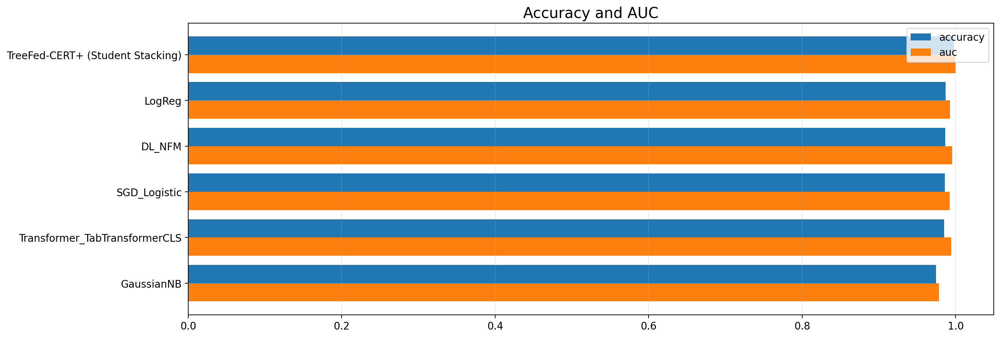

Saved: compare_plots/grouped_hbar_accuracy_auc.png


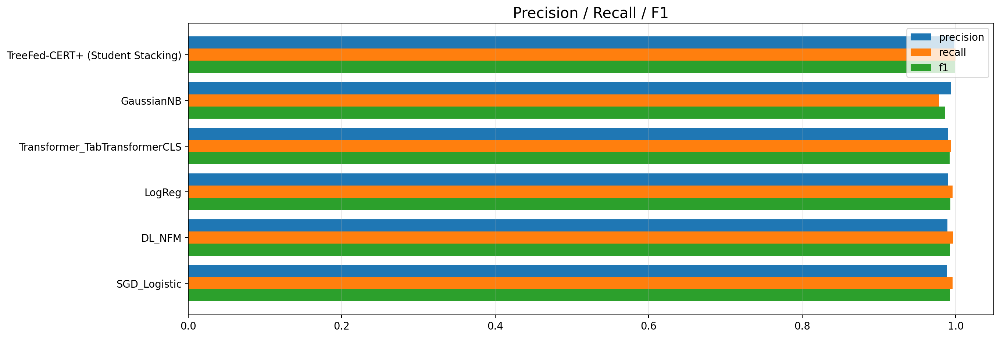

Saved: compare_plots/grouped_hbar_precision_recall_f1.png


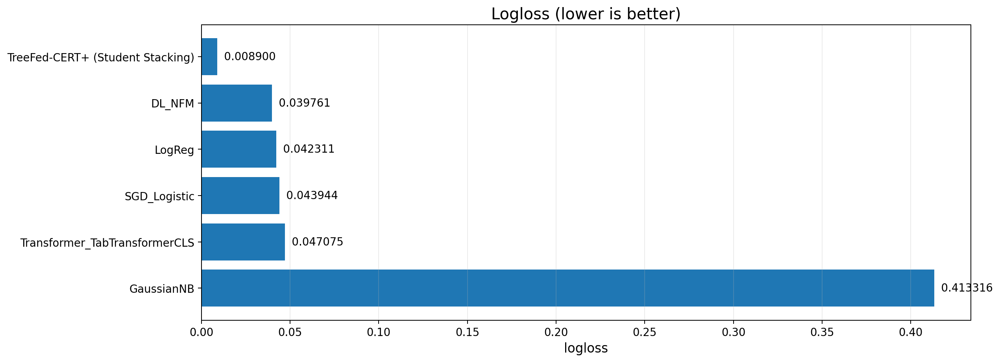

Saved: compare_plots/hbar_logloss.png


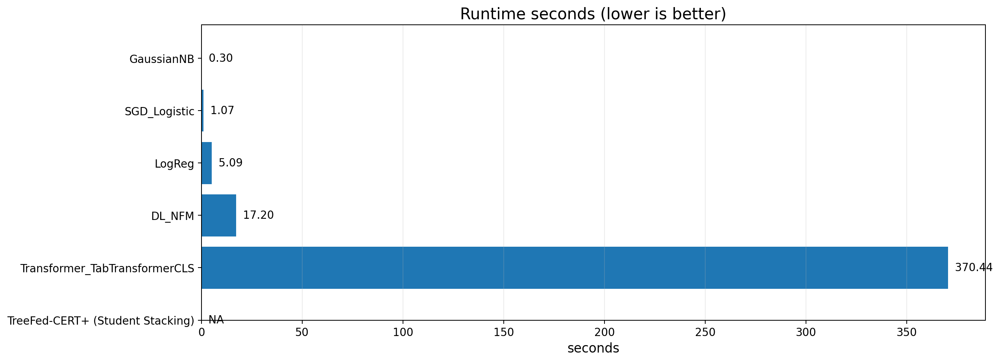

Saved: compare_plots/hbar_seconds.png


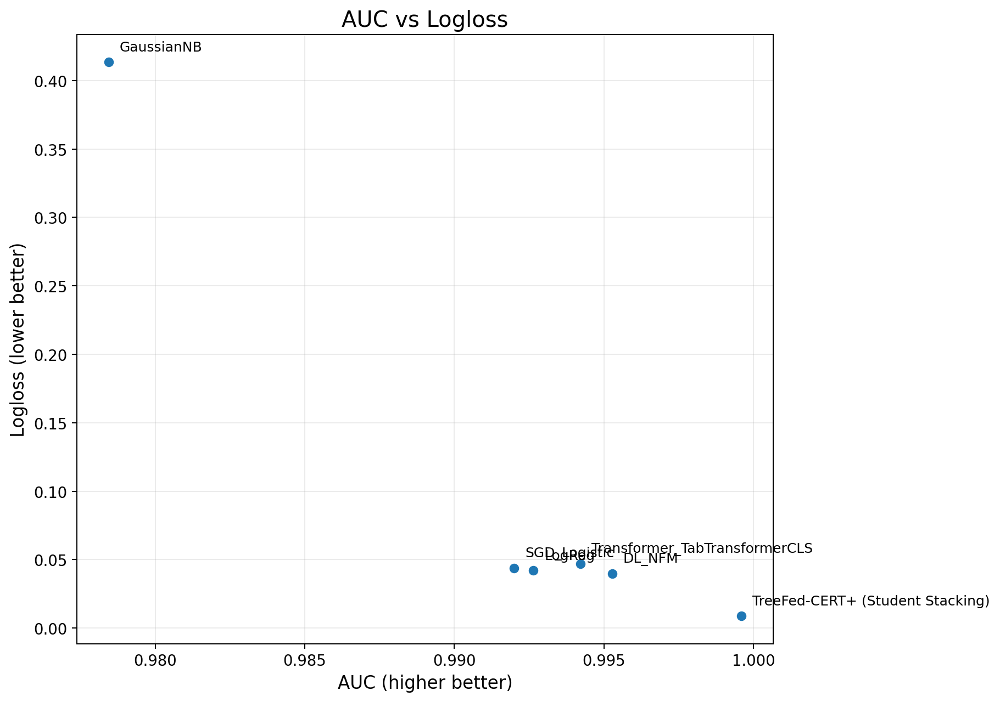

Saved: compare_plots/scatter_auc_vs_logloss.png


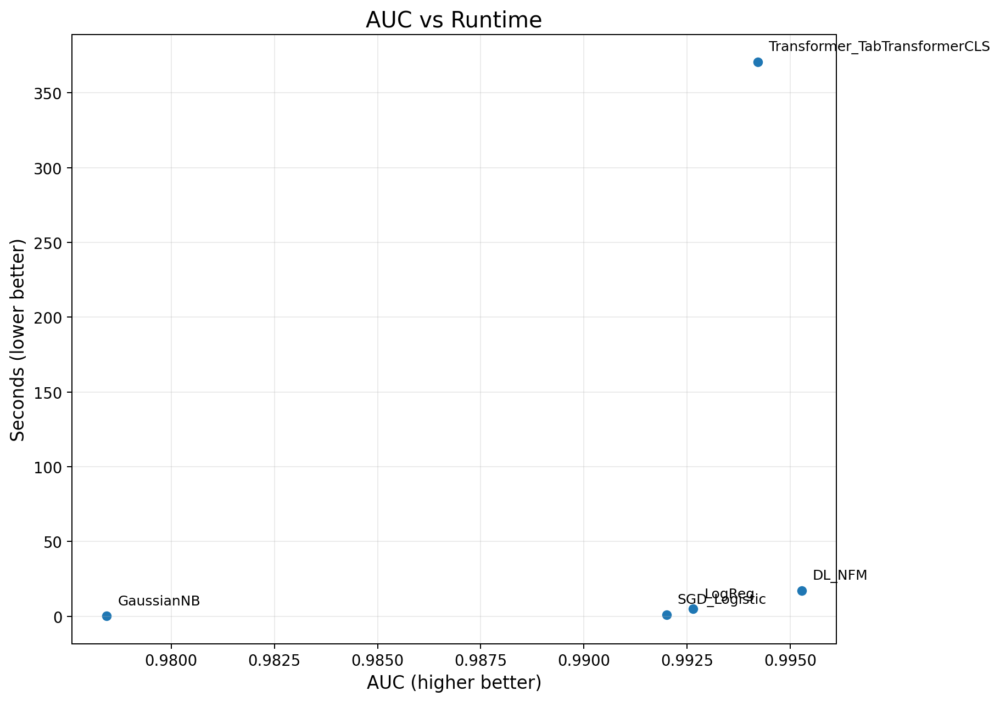

Saved: compare_plots/scatter_auc_vs_seconds.png


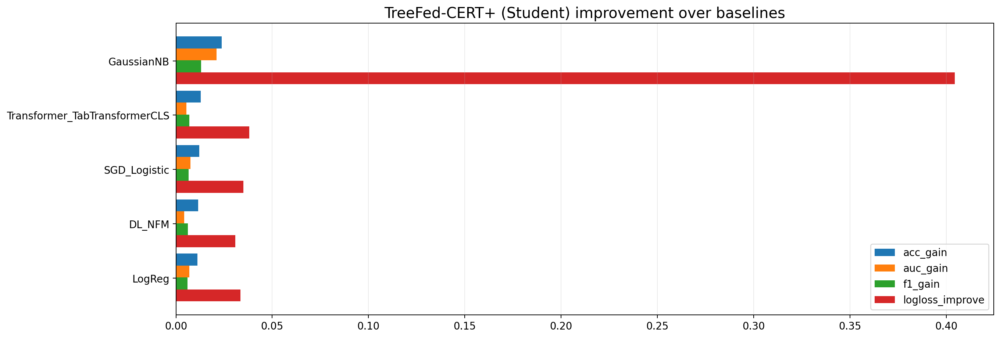

Saved: compare_plots/treefed_delta_vs_baselines.png


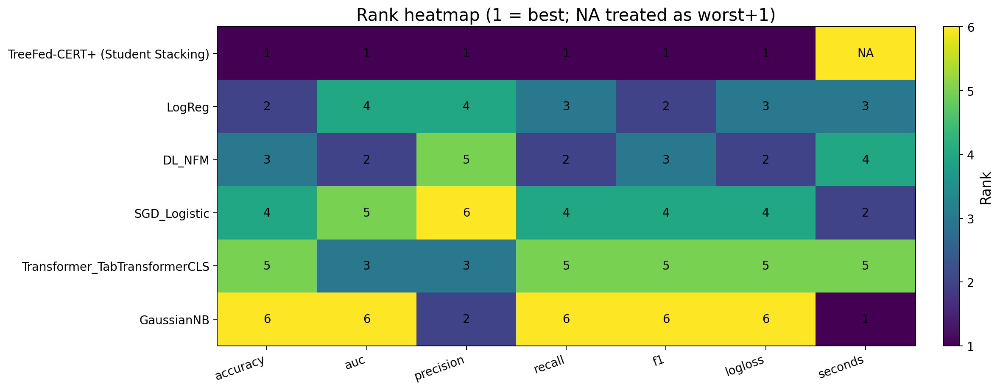

Saved: compare_plots/rank_heatmap.png

TreeFed gains over each baseline:
                        model  acc_gain  auc_gain  f1_gain  logloss_improve
                   GaussianNB  0.023852  0.021160 0.012982         0.404416
Transformer_TabTransformerCLS  0.012954  0.005390 0.006967         0.038175
                 SGD_Logistic  0.012195  0.007601 0.006546         0.035044
                       DL_NFM  0.011519  0.004327 0.006182         0.030861
                       LogReg  0.011105  0.006957 0.005962         0.033411


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 0) YOUR METRICS -> df  (define it every time)
# ============================================================
rows = [
    # model, acc, auc, prec, rec, f1, logloss, seconds
    ("TreeFed-CERT+ (Student Stacking)", 0.9980, 0.9996, 0.9982, 0.9996, 0.9989, 0.0089, np.nan),

    ("LogReg", 0.986895, 0.992643, 0.989892, 0.996003, 0.992938, 0.042311, 5.09),
    ("DL_NFM", 0.986481, 0.995273, 0.989249, 0.996212, 0.992718, 0.039761, 17.20),
    ("SGD_Logistic", 0.985805, 0.991999, 0.988893, 0.995839, 0.992354, 0.043944, 1.07),
    ("Transformer_TabTransformerCLS", 0.985046, 0.994210, 0.990032, 0.993841, 0.991933, 0.047075, 370.44),
    ("GaussianNB", 0.974148, 0.978440, 0.993638, 0.978317, 0.985918, 0.413316, 0.30),
]

df = pd.DataFrame(rows, columns=["model","accuracy","auc","precision","recall","f1","logloss","seconds"])

# ============================================================
# 1) PLOT QUALITY (sharp + clean)
# ============================================================
plt.rcParams.update({
    "figure.dpi": 180,
    "savefig.dpi": 520,
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
})

OUT_DIR = "compare_plots"
os.makedirs(OUT_DIR, exist_ok=True)

def save_show(fig, name):
    path = os.path.join(OUT_DIR, name)
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved:", path)

def annotate_points(ax, x, y, labels):
    for xi, yi, lab in zip(x, y, labels):
        ax.annotate(lab, (xi, yi), xytext=(8, 6), textcoords="offset points",
                    fontsize=10, ha="left", va="bottom")

# ============================================================
# 2) PLOT FUNCTIONS (horizontal = readable)
# ============================================================
def hbar_metric(metric, title, higher_is_better=True):
    d = df.copy().sort_values(metric, ascending=not higher_is_better).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(14, max(5, 0.6*len(d))), constrained_layout=True)
    y = np.arange(len(d))
    ax.barh(y, d[metric].values)
    ax.set_yticks(y)
    ax.set_yticklabels(d["model"].tolist())
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel(metric)
    ax.grid(True, axis="x", alpha=0.25)

    for i, v in enumerate(d[metric].values):
        if np.isnan(v):
            txt = "NA"
        else:
            txt = f"{v:.6f}" if metric != "seconds" else f"{v:.2f}"
        ax.text(v if not np.isnan(v) else 0.0, i, "  " + txt, va="center", fontsize=11)

    save_show(fig, f"hbar_{metric}.png")

def grouped_hbars(metrics, title, higher_is_better=True):
    d = df.set_index("model")[metrics].copy()
    d = d.sort_values(metrics[0], ascending=not higher_is_better)

    fig, ax = plt.subplots(figsize=(15, max(5, 0.65*len(d))), constrained_layout=True)
    y = np.arange(len(d))
    height = 0.8 / len(metrics)

    for j, m in enumerate(metrics):
        ax.barh(y + j*height, d[m].values, height=height, label=m)

    ax.set_yticks(y + height*(len(metrics)-1)/2)
    ax.set_yticklabels(d.index.tolist())
    ax.invert_yaxis()
    ax.set_title(title)
    ax.grid(True, axis="x", alpha=0.25)
    ax.legend()

    save_show(fig, f"grouped_hbar_{'_'.join(metrics)}.png")

def delta_vs_treefed():
    base = df[df["model"].str.contains("TreeFed", case=False)].iloc[0]
    others = df[~df["model"].str.contains("TreeFed", case=False)].copy()

    deltas = pd.DataFrame({
        "model": others["model"],
        "acc_gain": base["accuracy"] - others["accuracy"],
        "auc_gain": base["auc"] - others["auc"],
        "f1_gain":  base["f1"] - others["f1"],
        "logloss_improve": others["logloss"] - base["logloss"],  # positive = TreeFed better
    }).sort_values("acc_gain", ascending=False)

    fig, ax = plt.subplots(figsize=(15, max(5, 0.6*len(deltas))), constrained_layout=True)
    y = np.arange(len(deltas))
    ax.barh(y - 0.24, deltas["acc_gain"], height=0.22, label="acc_gain")
    ax.barh(y - 0.02, deltas["auc_gain"], height=0.22, label="auc_gain")
    ax.barh(y + 0.20, deltas["f1_gain"],  height=0.22, label="f1_gain")
    ax.barh(y + 0.42, deltas["logloss_improve"], height=0.22, label="logloss_improve")

    ax.set_yticks(y + 0.10)
    ax.set_yticklabels(deltas["model"].tolist())
    ax.invert_yaxis()
    ax.set_title("TreeFed-CERT+ (Student) improvement over baselines")
    ax.grid(True, axis="x", alpha=0.25)
    ax.legend()

    save_show(fig, "treefed_delta_vs_baselines.png")
    return deltas

def heatmap_ranks():
    score_cols_hi = ["accuracy","auc","precision","recall","f1"]
    score_cols_lo = ["logloss","seconds"]

    d = df.set_index("model").copy()

    ranks = pd.DataFrame(index=d.index)
    nan_mask = pd.DataFrame(False, index=d.index, columns=score_cols_hi + score_cols_lo)

    for c in score_cols_hi:
        nan_mask[c] = d[c].isna()
        r = d[c].rank(ascending=False, method="min")
        ranks[c] = r.fillna(r.max() + 1)

    for c in score_cols_lo:
        nan_mask[c] = d[c].isna()
        r = d[c].rank(ascending=True, method="min")
        ranks[c] = r.fillna(r.max() + 1)

    mat = ranks.values.astype(float)

    fig, ax = plt.subplots(figsize=(13, 5), constrained_layout=True)
    im = ax.imshow(mat, aspect="auto", interpolation="nearest")

    ax.set_yticks(np.arange(len(ranks.index)))
    ax.set_yticklabels(ranks.index.tolist())

    ax.set_xticks(np.arange(len(ranks.columns)))
    ax.set_xticklabels(ranks.columns.tolist(), rotation=20, ha="right")

    ax.set_title("Rank heatmap (1 = best; NA treated as worst+1)")
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            txt = "NA" if nan_mask.iloc[i, j] else str(int(round(mat[i, j])))
            ax.text(j, i, txt, ha="center", va="center", fontsize=11)

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.ax.set_ylabel("Rank", rotation=90)

    save_show(fig, "rank_heatmap.png")
    return ranks

def scatter_plots():
    fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)
    ax.scatter(df["auc"], df["logloss"])
    annotate_points(ax, df["auc"], df["logloss"], df["model"])
    ax.set_xlabel("AUC (higher better)")
    ax.set_ylabel("Logloss (lower better)")
    ax.set_title("AUC vs Logloss")
    ax.grid(True, alpha=0.25)
    save_show(fig, "scatter_auc_vs_logloss.png")

    d = df.dropna(subset=["seconds"]).copy()
    fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)
    ax.scatter(d["auc"], d["seconds"])
    annotate_points(ax, d["auc"], d["seconds"], d["model"])
    ax.set_xlabel("AUC (higher better)")
    ax.set_ylabel("Seconds (lower better)")
    ax.set_title("AUC vs Runtime")
    ax.grid(True, alpha=0.25)
    save_show(fig, "scatter_auc_vs_seconds.png")

# ============================================================
# 3) RUN EVERYTHING
# ============================================================
print(df.to_string(index=False))

grouped_hbars(["accuracy","auc"], "Accuracy and AUC", higher_is_better=True)
grouped_hbars(["precision","recall","f1"], "Precision / Recall / F1", higher_is_better=True)

hbar_metric("logloss", "Logloss (lower is better)", higher_is_better=False)
hbar_metric("seconds", "Runtime seconds (lower is better)", higher_is_better=False)

scatter_plots()
deltas = delta_vs_treefed()
ranks = heatmap_ranks()

print("\nTreeFed gains over each baseline:")
print(deltas.to_string(index=False))


# **XAI of the best our model**

In [7]:
# =========================
# CELL 1: FIX UNPICKLE + LOAD ARTIFACTS
# =========================
import os, glob, pickle, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

# Required because artifacts.pkl stored this class from __main__
class TopKCategory(BaseEstimator, TransformerMixin):
    def __init__(self, topk=4):
        self.topk = int(topk)
        self.maps_ = None
        self.cols_ = None

    def fit(self, X, y=None):
        X = pd.DataFrame(X).copy()
        self.cols_ = list(X.columns)
        self.maps_ = {}
        for c in self.cols_:
            s = X[c].astype(str)
            s = s.replace(r"^\s*(?:na|n/a|none|null|nan)\s*$", np.nan, regex=True)
            s = s.replace(r"^\s*$", np.nan, regex=True)
            vc = s.dropna().value_counts()
            self.maps_[c] = set(vc.head(self.topk).index.tolist())
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        if self.cols_ is not None:
            X.columns = self.cols_
        for c in self.cols_:
            s = X[c].astype(str)
            s = s.replace(r"^\s*(?:na|n/a|none|null|nan)\s*$", np.nan, regex=True)
            s = s.replace(r"^\s*$", np.nan, regex=True)
            s = s.fillna("OTHER")
            allowed = self.maps_.get(c, set())
            X[c] = s.where(s.isin(allowed), "OTHER") if allowed else s
        return X

# Load latest artifacts.pkl
pkl_candidates = sorted(
    glob.glob("treefed_cert_run/**/artifacts.pkl", recursive=True),
    key=lambda p: os.path.getmtime(p)
)
if not pkl_candidates:
    raise FileNotFoundError("No artifacts.pkl found under treefed_cert_run/**")

ARTIFACTS_PATH = pkl_candidates[-1]
print("Using artifacts:", ARTIFACTS_PATH)

with open(ARTIFACTS_PATH, "rb") as f:
    art = pickle.load(f)

print("Loaded OK. Keys:", list(art.keys()))


Using artifacts: treefed_cert_run/treefed_20251217_160455/artifacts.pkl
Loaded OK. Keys: ['CFG', 'summary', 'splits', 'nested', 'client_certificates', 'client_best_params', 'teachers', 'server_preprocessor', 'student_model', 'probs', 'rl_history']


Using artifacts: treefed_cert_run/treefed_20251217_160455/artifacts.pkl
Clients: 4 | Final alpha: [0.2416, 0.2497, 0.2547, 0.254]
Data: (362445, 28) | Cat: 9 | Num: 19 | y dist: {0: np.int64(27166), 1: np.int64(335279)}


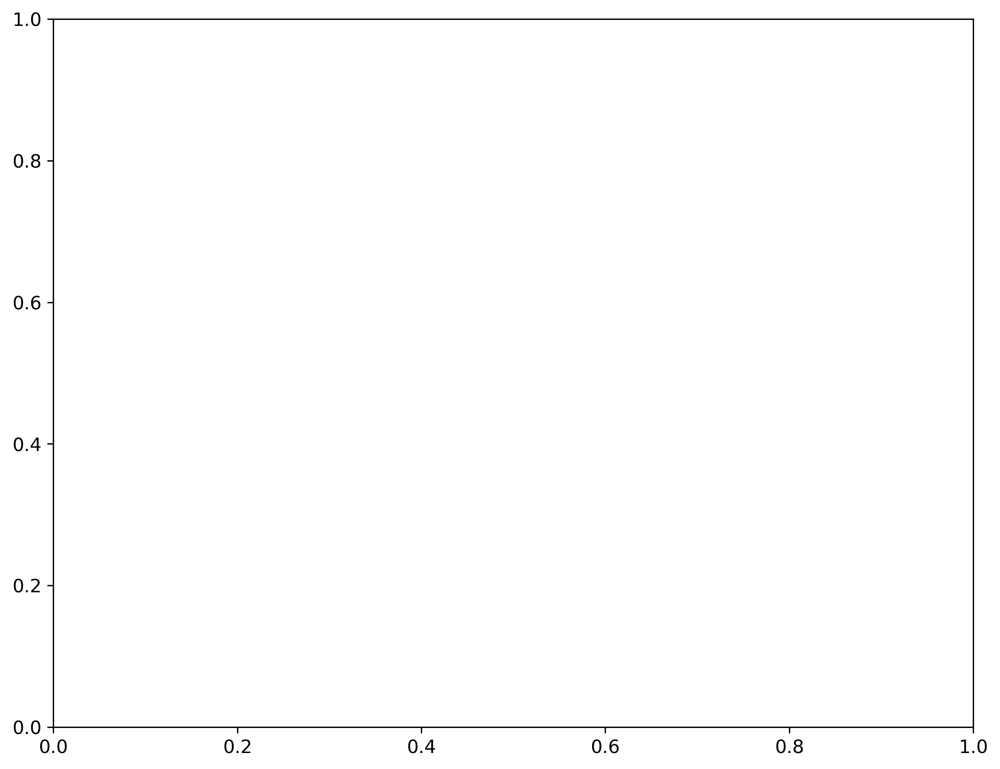

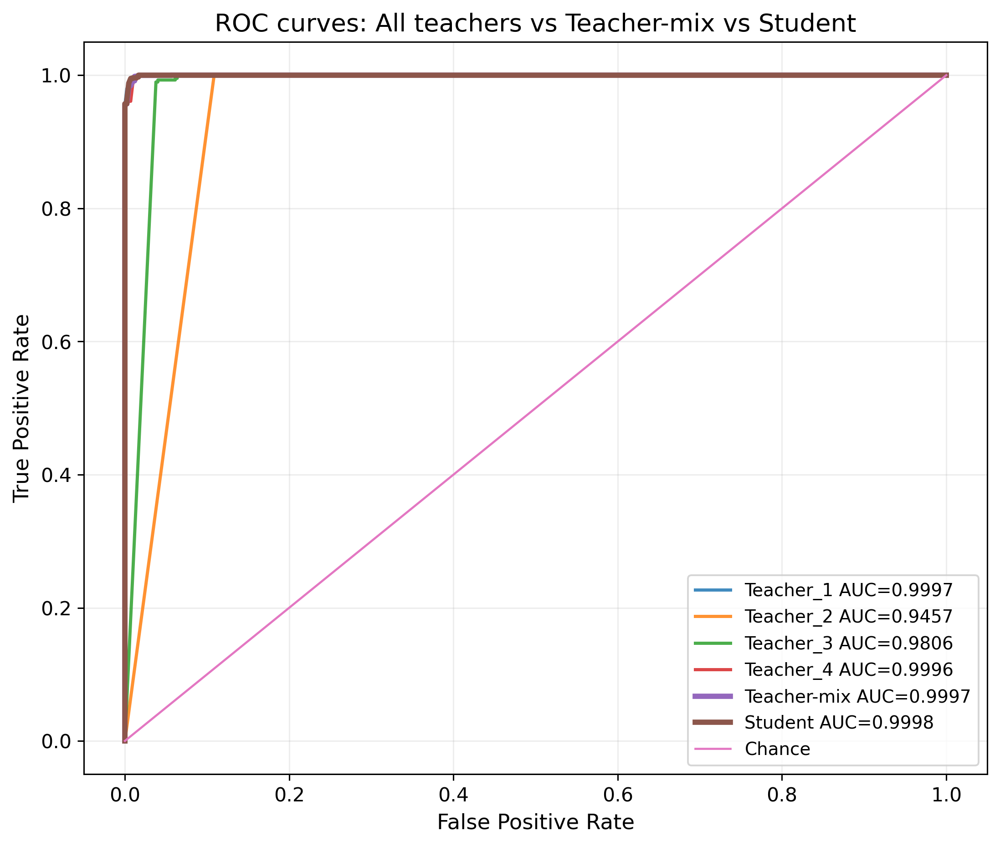

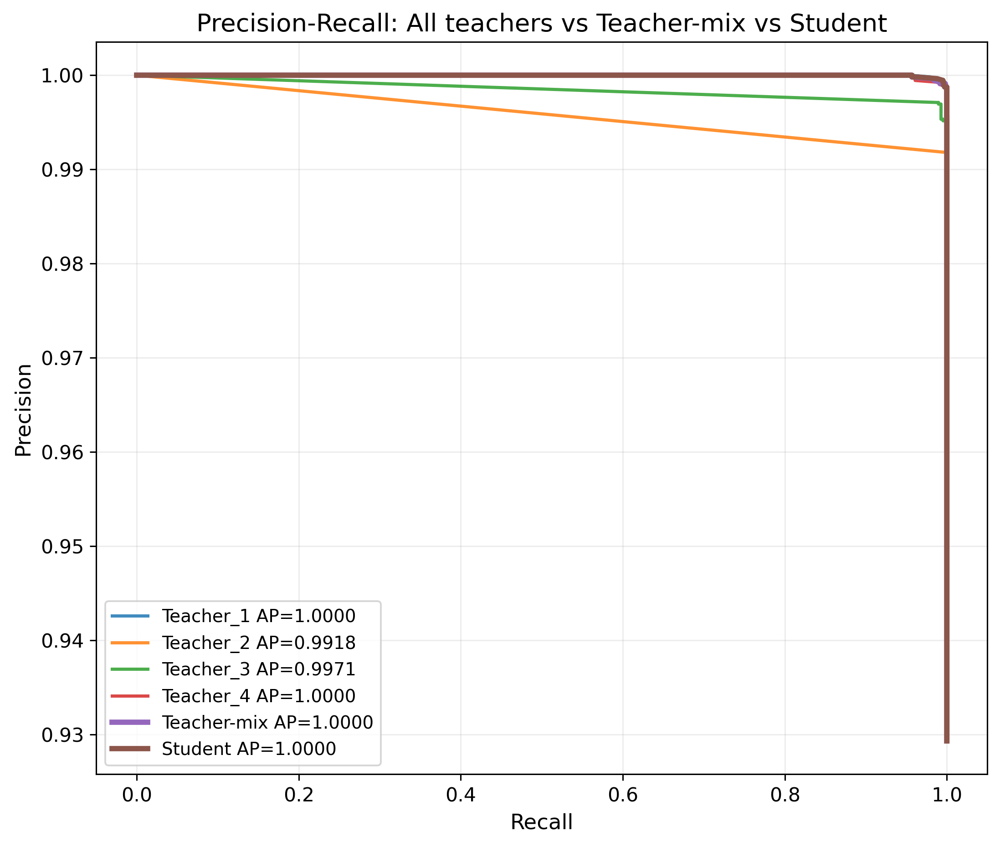

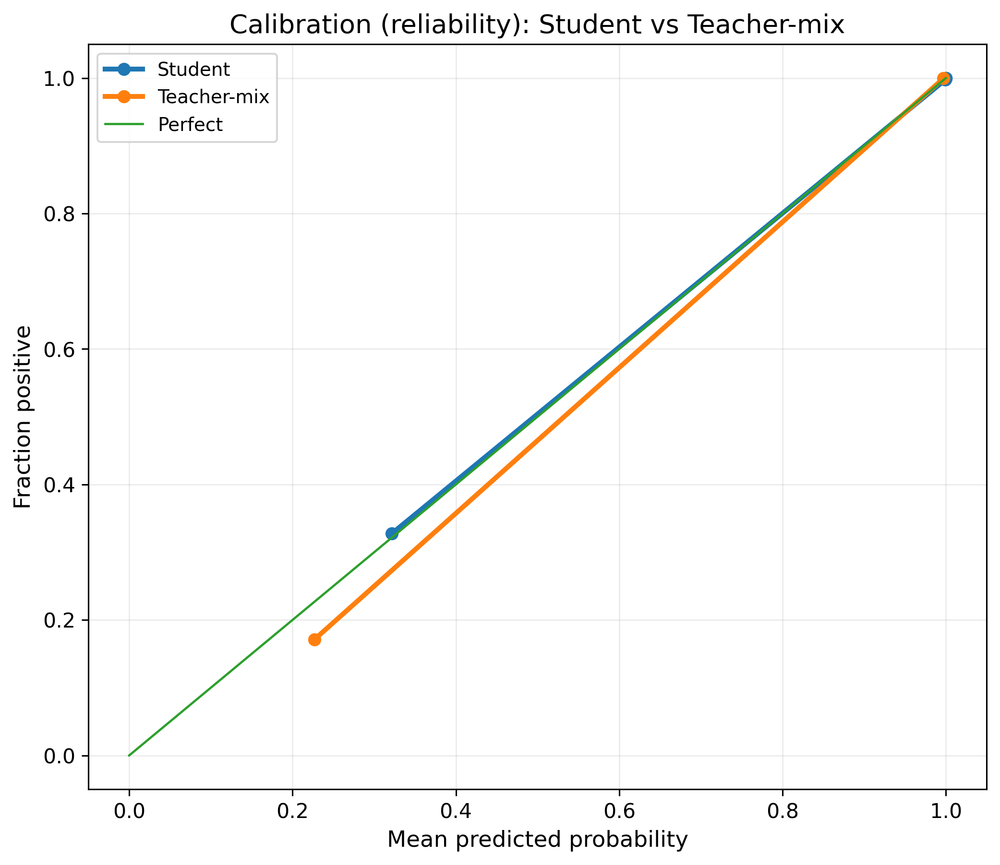

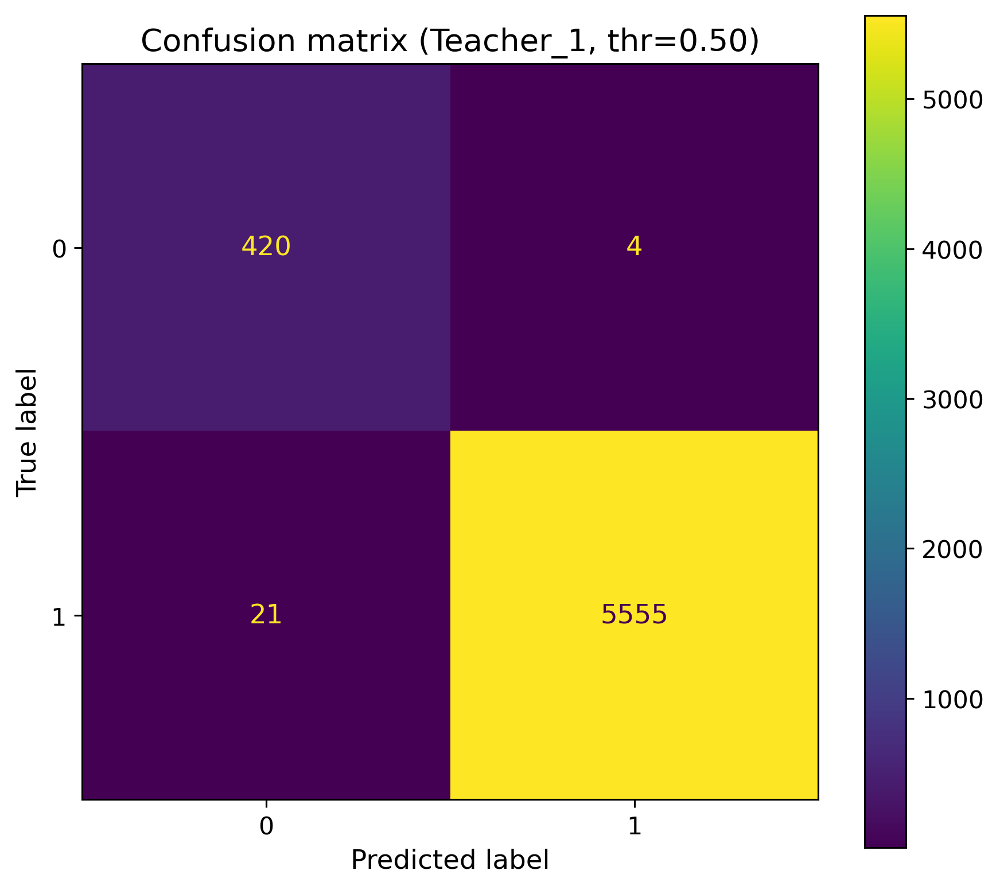

...

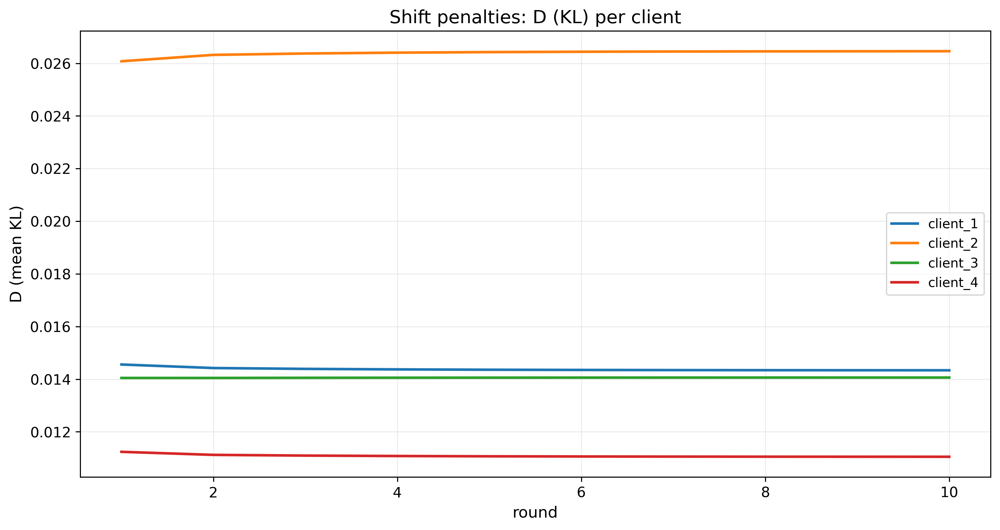

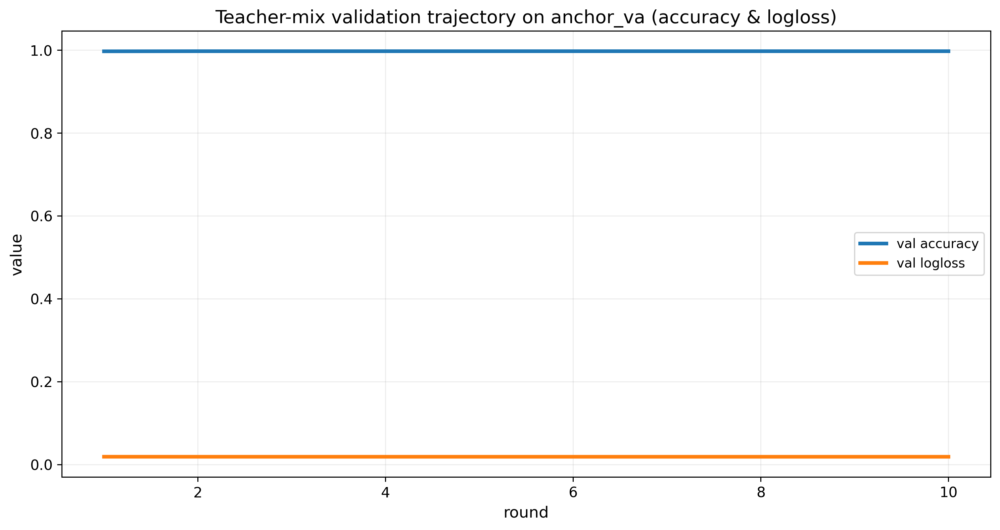

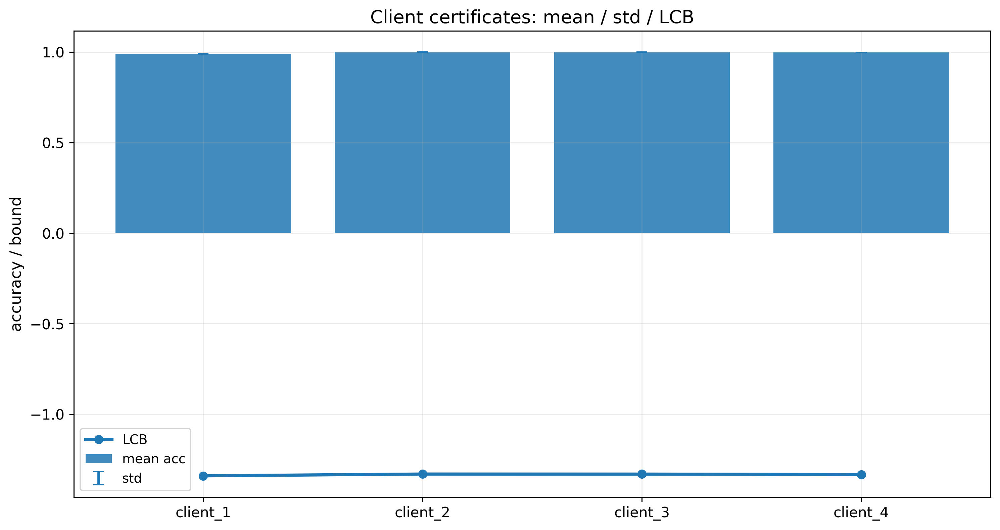

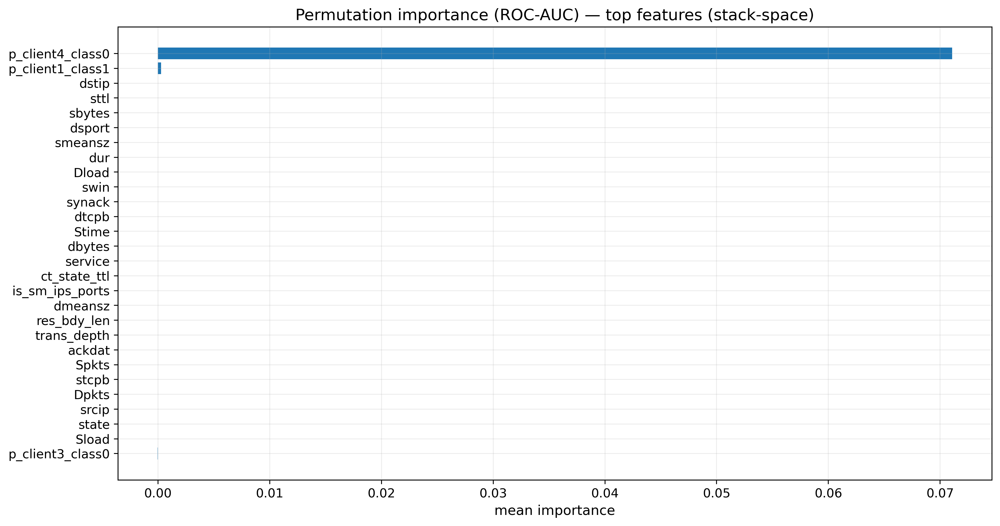

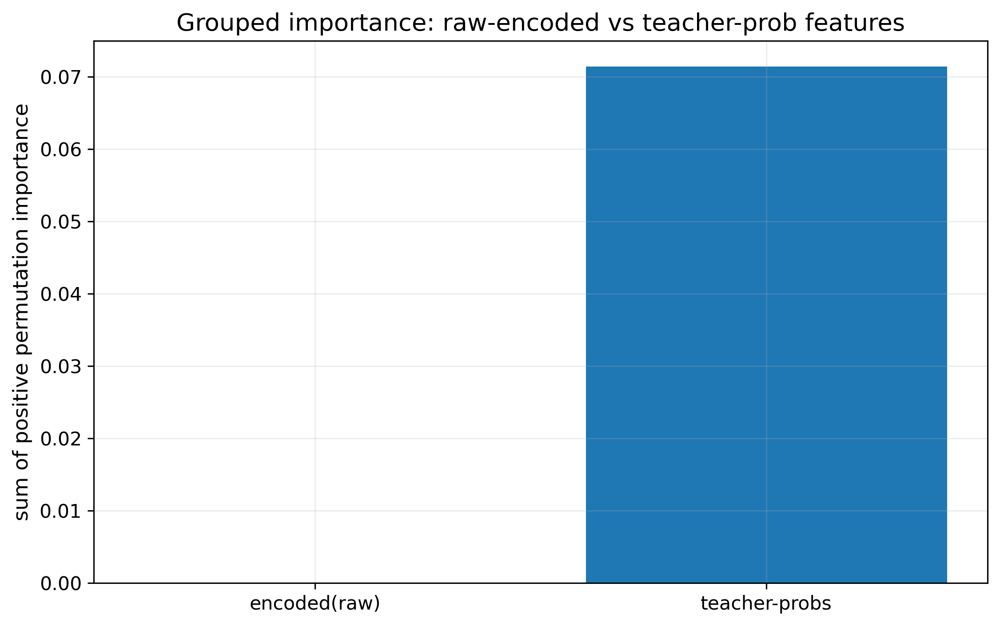

PDP/ICE/ALE numeric features: ['dtcpb', 'dbytes', 'swin', 'Sload']


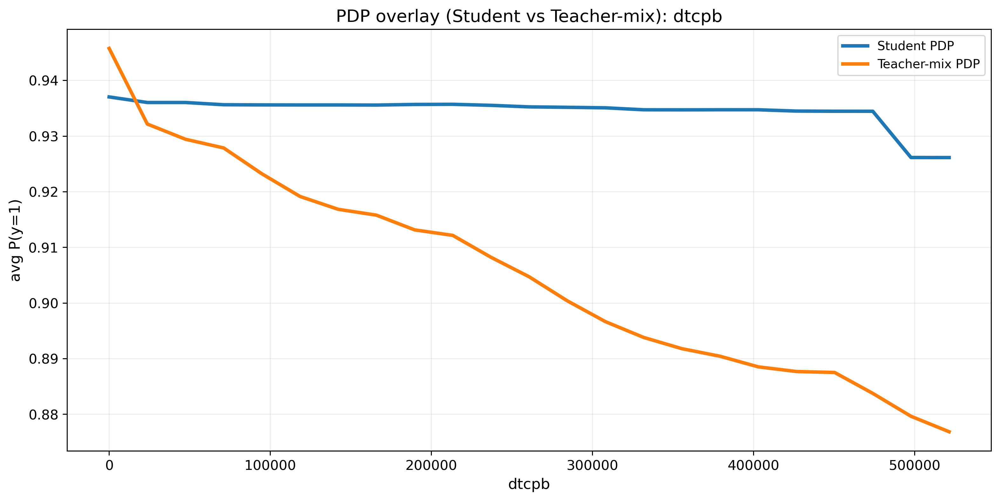

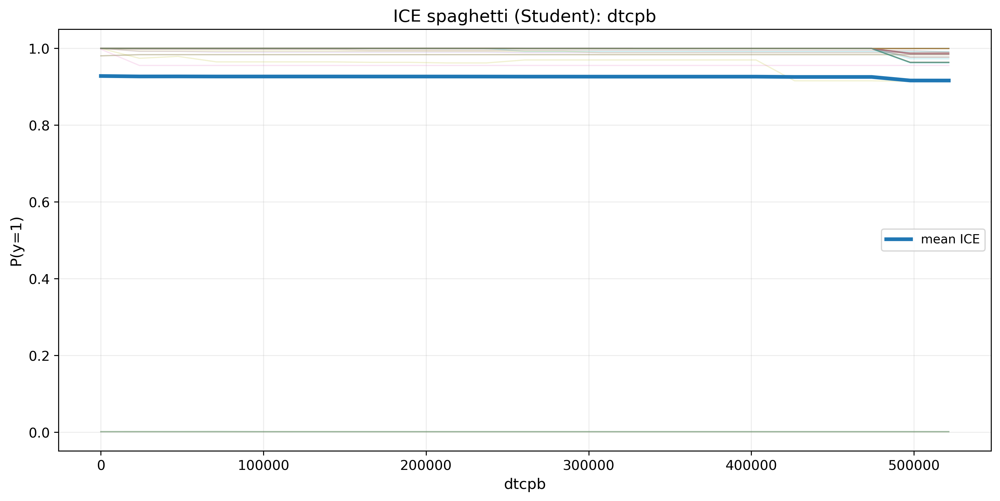

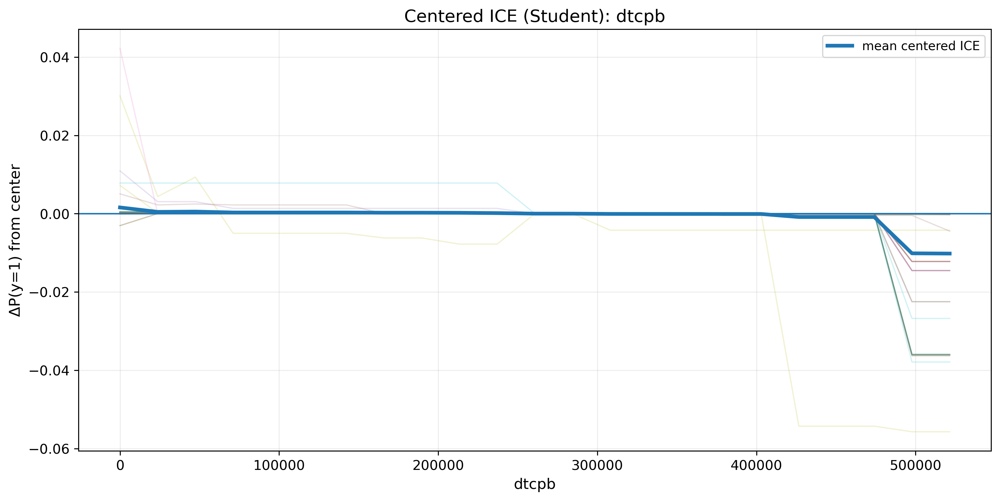

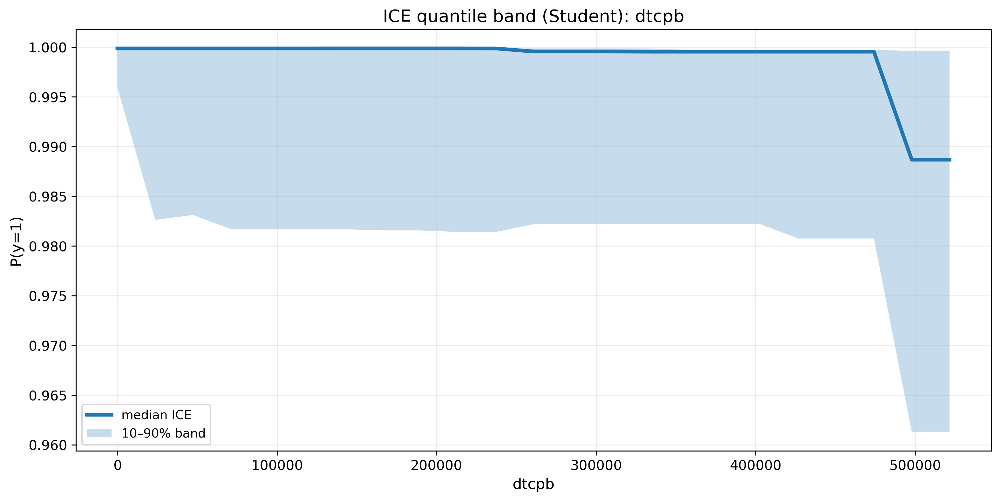

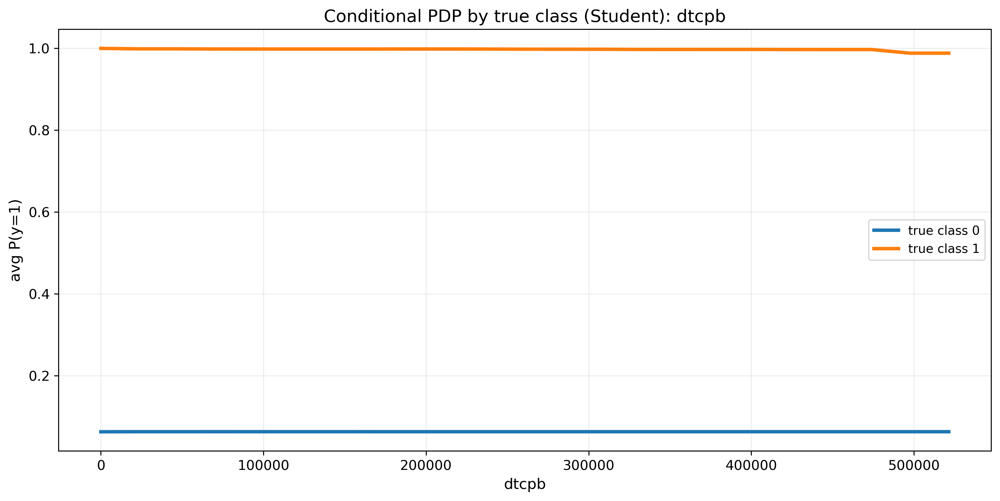

...

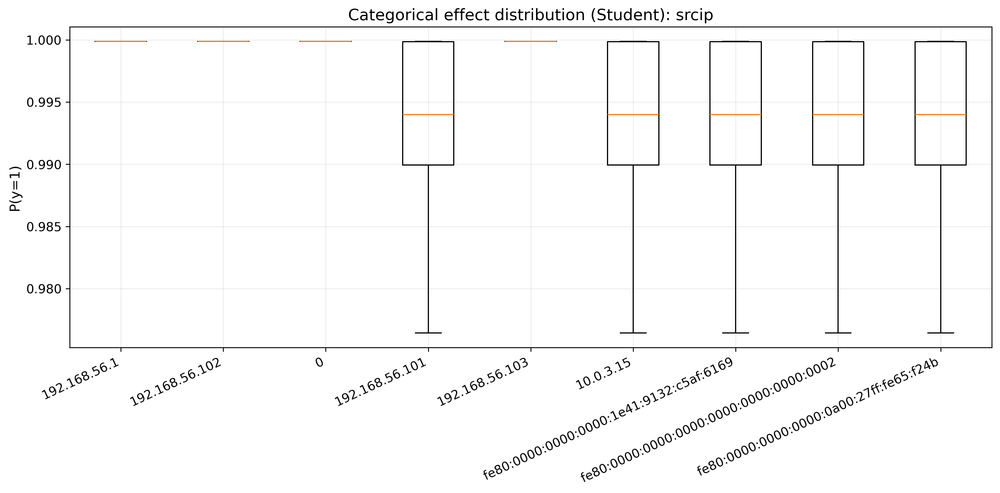

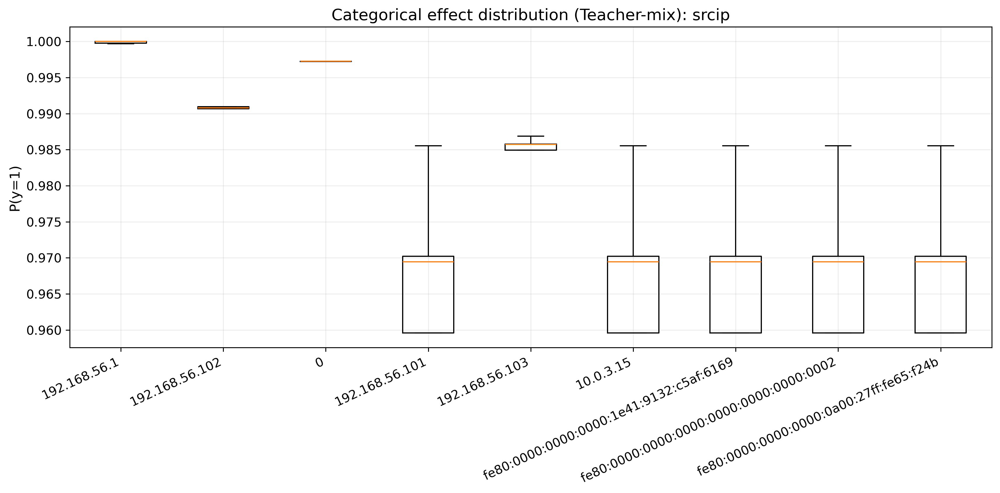

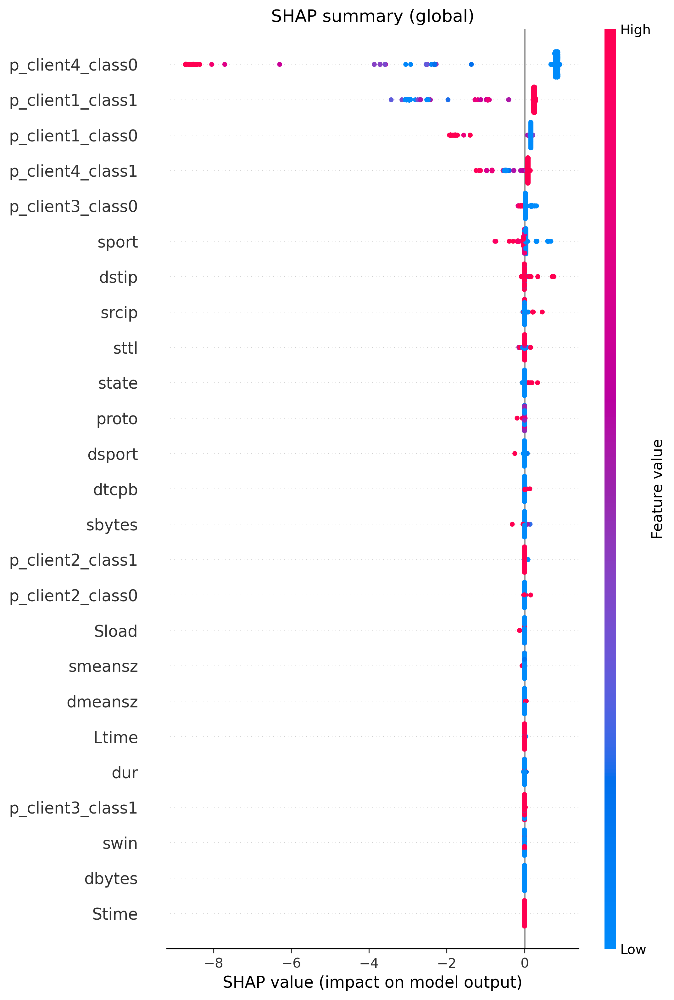

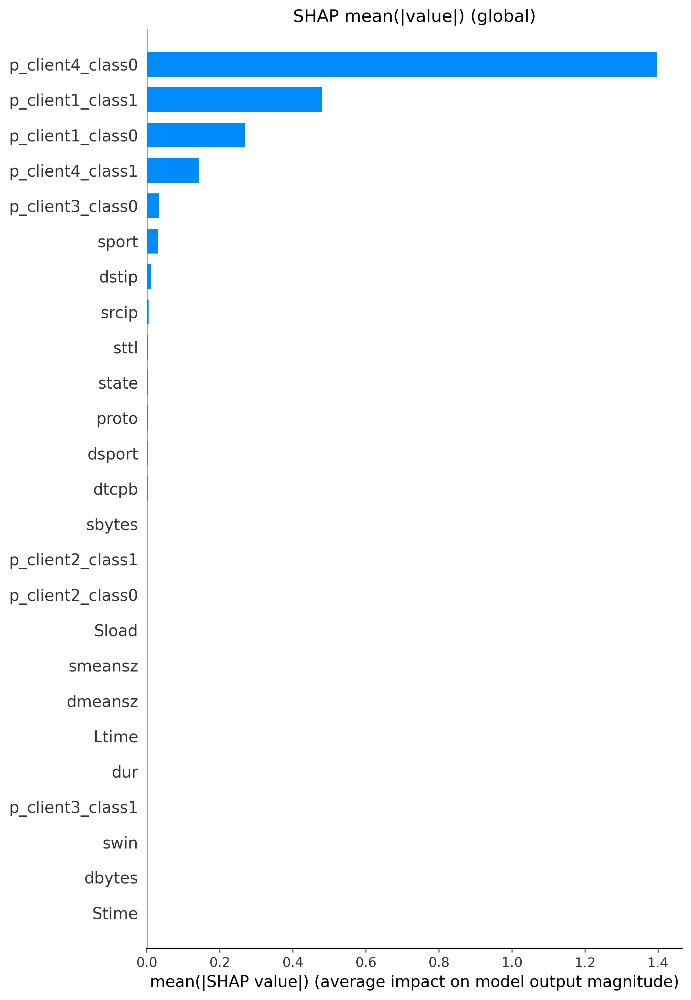

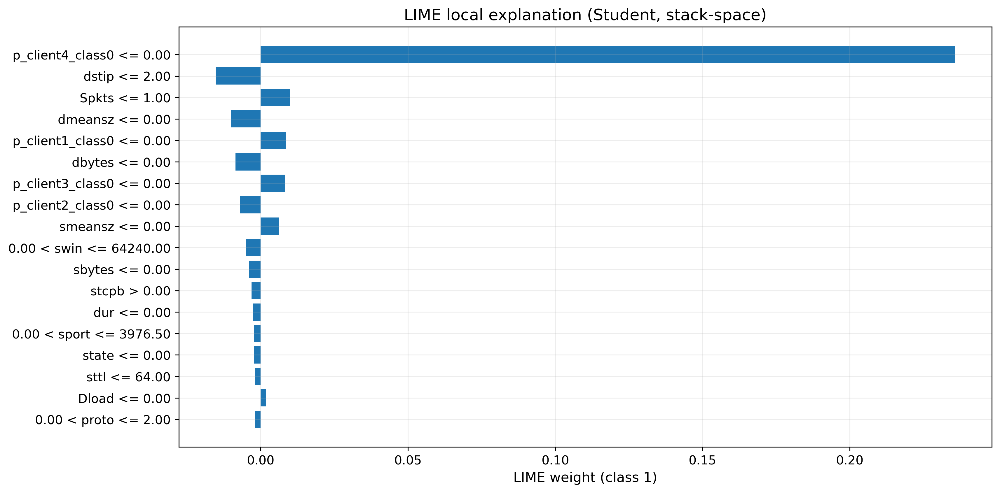

In [9]:
# ============================================================
# TREEFED-CERT+: FULL XAI + PROCESS PLOTS (NO SAVING)
# - Fixes artifacts.pkl unpickle TopKCategory
# - Fixes 2D contour crash by robust 2D grid + auto-skip
# - Many PDP/ICE/ALE variants
# ============================================================

import os, glob, pickle, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import (
    roc_curve, auc,
    precision_recall_curve, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

# -------------------------
# USER KNOBS (speed/amount)
# -------------------------
SEED = 42
rng = np.random.default_rng(SEED)

DATA_PATH  = "dataset_1_cleaned.csv"
TARGET_COL = "Label"

# main evaluation sample sizes
N_CMP = 6000          # ROC/PR/CM/Calib sample
N_PI  = 2000          # permutation importance sample
PI_REPEATS = 2

# PDP/ICE/ALE
MAX_PDP_FEATURES = 4  # how many numeric features to run the full PDP/ICE/ALE suite on
N_PDP_BASE = 240      # rows used for PDP/ICE/ALE computations
ICE_LINES  = 70       # ICE lines per feature
GRID1D     = 23       # points in 1D grid
BINS_ALE   = 18       # ALE bins

# 2D PDP
DO_2D_PDP  = True
GRID2D     = 16
N_SURF     = 180

# categorical PDP
MAX_CAT_LEVELS = 10

# SHAP/LIME (guarded)
DO_SHAP = True
DO_LIME = True

# -------------------------
# Matplotlib styling
# -------------------------
plt.rcParams.update({
    "figure.dpi": 280,
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
})

def newfig(title, figsize=(11.2, 5.6)):
    plt.figure(figsize=figsize)
    plt.title(title)
    plt.grid(True, alpha=0.22)

# ============================================================
# 1) Fix artifacts unpickle (TopKCategory)
# ============================================================
class TopKCategory(BaseEstimator, TransformerMixin):
    def __init__(self, topk=4):
        self.topk = int(topk)
        self.maps_ = None
        self.cols_ = None

    def fit(self, X, y=None):
        X = pd.DataFrame(X).copy()
        self.cols_ = list(X.columns)
        self.maps_ = {}
        for c in self.cols_:
            s = X[c].astype(str)
            s = s.replace(r"^\s*(?:na|n/a|none|null|nan)\s*$", np.nan, regex=True)
            s = s.replace(r"^\s*$", np.nan, regex=True)
            vc = s.dropna().value_counts()
            self.maps_[c] = set(vc.head(self.topk).index.tolist())
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        if self.cols_ is not None:
            X.columns = self.cols_
        for c in self.cols_:
            s = X[c].astype(str)
            s = s.replace(r"^\s*(?:na|n/a|none|null|nan)\s*$", np.nan, regex=True)
            s = s.replace(r"^\s*$", np.nan, regex=True)
            s = s.fillna("OTHER")
            allowed = self.maps_.get(c, set())
            X[c] = s.where(s.isin(allowed), "OTHER") if allowed else s
        return X

# load latest artifacts.pkl
pkl_candidates = sorted(
    glob.glob("treefed_cert_run/**/artifacts.pkl", recursive=True),
    key=lambda p: os.path.getmtime(p)
)
if not pkl_candidates:
    raise FileNotFoundError("No artifacts.pkl found under treefed_cert_run/**")

ARTIFACTS_PATH = pkl_candidates[-1]
print("Using artifacts:", ARTIFACTS_PATH)

with open(ARTIFACTS_PATH, "rb") as f:
    art = pickle.load(f)

teachers   = art["teachers"]
server_pre = art["server_preprocessor"]
student    = art["student_model"]
summary    = art.get("summary", {})
rl_hist    = art.get("rl_history", [])

classes_all = np.array(summary.get("classes_all", [0, 1]), dtype=int)
if len(classes_all) != 2:
    raise ValueError(f"Expected binary; got classes {classes_all}")

pos_label = classes_all[1]
pos_idx_student = int(np.where(student.classes_ == pos_label)[0][0])

alpha_final = np.array(summary.get("final_alpha", [1/len(teachers)]*len(teachers)), dtype=float)
alpha_final = alpha_final / (alpha_final.sum() + 1e-12)

cat_cols = summary.get("cat_cols", None)
num_cols = summary.get("num_cols", None)

print("Clients:", len(teachers), "| Final alpha:", [float(f"{a:.4f}") for a in alpha_final])

# ============================================================
# 2) Load dataset (robust Label -> int)
# ============================================================
df = pd.read_csv(DATA_PATH, low_memory=False)
if TARGET_COL not in df.columns:
    raise KeyError(f"Target column '{TARGET_COL}' not found.")

y_raw = df[TARGET_COL].replace(
    [np.inf, -np.inf, "inf", "-inf", "INF", "-INF", "nan", "NaN", "", " ", "NULL", "null"],
    np.nan
)
y_num = pd.to_numeric(y_raw, errors="coerce")
keep = y_num.notna().values

df = df.loc[keep].reset_index(drop=True)
y  = y_num.loc[keep].astype(int).values
X  = df.drop(columns=[TARGET_COL]).copy()

if cat_cols is None or num_cols is None:
    cat_cols = [c for c in X.columns if X[c].dtype == "object"]
    num_cols = [c for c in X.columns if c not in cat_cols]

print("Data:", X.shape, "| Cat:", len(cat_cols), "| Num:", len(num_cols), "| y dist:", dict(pd.Series(y).value_counts().sort_index()))

# ============================================================
# 3) Prob helpers (NO retraining)
# ============================================================
def predict_proba_aligned(pipeline, X_df, classes_all):
    proba = pipeline.predict_proba(X_df)
    model_classes = pipeline.named_steps["clf"].classes_
    out = np.zeros((len(X_df), len(classes_all)), dtype=np.float32)
    idx = {c: i for i, c in enumerate(classes_all)}
    for j, c in enumerate(model_classes):
        out[:, idx[c]] = proba[:, j]
    out = np.clip(out, 1e-12, 1.0)
    out = out / (out.sum(axis=1, keepdims=True) + 1e-12)
    return out

def collect_teacher_probs(X_df):
    probs_list = []
    for ci in range(1, len(teachers) + 1):
        probs_list.append(predict_proba_aligned(teachers[f"client_{ci}"], X_df, classes_all))
    return np.stack(probs_list, axis=0)  # (C,N,2)

def teacher_mix_proba_pos(X_df):
    P = collect_teacher_probs(X_df)  # (C,N,2)
    mix = np.sum(alpha_final[:, None, None] * P, axis=0)
    return mix[:, 1]

def student_proba_pos(X_df):
    # student needs: server_pre.transform(X) + concat teacher probs features
    X_enc = server_pre.transform(X_df)
    if hasattr(X_enc, "toarray"):
        X_enc = X_enc.toarray()
    P = collect_teacher_probs(X_df)  # (C,N,2)
    F = np.concatenate([P[i] for i in range(P.shape[0])], axis=1)  # (N, C*2)
    X_stack = np.hstack([X_enc, F]).astype(np.float32)
    return student.predict_proba(X_stack)[:, pos_idx_student], X_stack

# stack feature names (for permutation importance plots)
enc_feature_names = list(cat_cols) + list(num_cols)
prob_feature_names = []
for ci in range(1, len(teachers) + 1):
    prob_feature_names += [f"p_client{ci}_class{classes_all[0]}", f"p_client{ci}_class{classes_all[1]}"]
stack_feature_names = enc_feature_names + prob_feature_names

# ============================================================
# 4) Core comparison plots: ROC/PR/Calib/CM (Teachers + Mix + Student)
# ============================================================
cmp_idx = rng.choice(len(X), size=min(N_CMP, len(X)), replace=False)
X_cmp = X.iloc[cmp_idx].reset_index(drop=True)
y_cmp = y[cmp_idx].astype(int)

# probs
p_student, _ = student_proba_pos(X_cmp)
p_mix = teacher_mix_proba_pos(X_cmp)

# per-teacher probs for ROC/PR
p_teachers = {}
for ci in range(1, len(teachers) + 1):
    Pci = predict_proba_aligned(teachers[f"client_{ci}"], X_cmp, classes_all)[:, 1]
    p_teachers[f"Teacher_{ci}"] = Pci

# ROC (all)
newfig("ROC curves: All teachers vs Teacher-mix vs Student", figsize=(8.0, 6.8))
for name, p in p_teachers.items():
    fpr, tpr, _ = roc_curve(y_cmp, p, pos_label=pos_label)
    plt.plot(fpr, tpr, linewidth=1.8, alpha=0.85, label=f"{name} AUC={auc(fpr,tpr):.4f}")
fpr, tpr, _ = roc_curve(y_cmp, p_mix, pos_label=pos_label)
plt.plot(fpr, tpr, linewidth=3.0, label=f"Teacher-mix AUC={auc(fpr,tpr):.4f}")
fpr, tpr, _ = roc_curve(y_cmp, p_student, pos_label=pos_label)
plt.plot(fpr, tpr, linewidth=3.0, label=f"Student AUC={auc(fpr,tpr):.4f}")
plt.plot([0,1],[0,1], linewidth=1.2, label="Chance")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout(); plt.show()

# PR (all)
newfig("Precision-Recall: All teachers vs Teacher-mix vs Student", figsize=(8.0, 6.8))
for name, p in p_teachers.items():
    pr, rc, _ = precision_recall_curve(y_cmp, p, pos_label=pos_label)
    ap = average_precision_score(y_cmp, p)
    plt.plot(rc, pr, linewidth=1.8, alpha=0.85, label=f"{name} AP={ap:.4f}")
pr, rc, _ = precision_recall_curve(y_cmp, p_mix, pos_label=pos_label)
plt.plot(rc, pr, linewidth=3.0, label=f"Teacher-mix AP={average_precision_score(y_cmp,p_mix):.4f}")
pr, rc, _ = precision_recall_curve(y_cmp, p_student, pos_label=pos_label)
plt.plot(rc, pr, linewidth=3.0, label=f"Student AP={average_precision_score(y_cmp,p_student):.4f}")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.legend()
plt.tight_layout(); plt.show()

# Calibration overlay: Student vs Mix
prob_true_s, prob_pred_s = calibration_curve(y_cmp, p_student, n_bins=12, strategy="quantile")
prob_true_t, prob_pred_t = calibration_curve(y_cmp, p_mix, n_bins=12, strategy="quantile")
newfig("Calibration (reliability): Student vs Teacher-mix", figsize=(7.6, 6.6))
plt.plot(prob_pred_s, prob_true_s, marker="o", linewidth=2.6, label="Student")
plt.plot(prob_pred_t, prob_true_t, marker="o", linewidth=2.6, label="Teacher-mix")
plt.plot([0,1],[0,1], linewidth=1.2, label="Perfect")
plt.xlabel("Mean predicted probability"); plt.ylabel("Fraction positive")
plt.legend()
plt.tight_layout(); plt.show()

# Confusion matrices (each teacher + mix + student), threshold=0.5
def show_cm(title, y_true, p_pos):
    yhat = (p_pos >= 0.5).astype(int)
    cm = confusion_matrix(y_true, yhat, labels=classes_all)
    fig = plt.figure(figsize=(6.5, 5.8), dpi=280); ax = fig.add_subplot(111)
    ConfusionMatrixDisplay(cm, display_labels=classes_all).plot(ax=ax, values_format="d")
    ax.set_title(title)
    plt.tight_layout(); plt.show()

for name, p in p_teachers.items():
    show_cm(f"Confusion matrix ({name}, thr=0.50)", y_cmp, p)

show_cm("Confusion matrix (Teacher-mix, thr=0.50)", y_cmp, p_mix)
show_cm("Confusion matrix (Student, thr=0.50)", y_cmp, p_student)

# Probability agreement plots (process sanity checks)
newfig("Probability agreement: Student vs Teacher-mix (scatter)", figsize=(7.2, 6.6))
plt.scatter(p_mix, p_student, s=8, alpha=0.35)
plt.xlabel("Teacher-mix P(y=1)"); plt.ylabel("Student P(y=1)")
plt.tight_layout(); plt.show()

diff = p_student - p_mix
newfig("Probability difference: Student - Teacher-mix (hist)", figsize=(8.2, 5.2))
plt.hist(diff, bins=50, alpha=0.9)
plt.xlabel("Student P(y=1) - Teacher-mix P(y=1)"); plt.ylabel("count")
plt.tight_layout(); plt.show()

# ============================================================
# 5) RL / certificate process plots (NOT final output metrics)
# ============================================================
if rl_hist:
    rounds = np.array([h["round"] for h in rl_hist], dtype=int)
    alpha_hist = np.array([h["alpha"] for h in rl_hist], dtype=float)  # (T,C)
    Q_hist = np.array([h["Q"] for h in rl_hist], dtype=float)
    D_hist = np.array([h["D"] for h in rl_hist], dtype=float)
    val_acc = np.array([h["mix_val_metrics"]["accuracy"] for h in rl_hist], dtype=float)
    val_ll  = np.array([h["mix_val_metrics"]["logloss"]  for h in rl_hist], dtype=float)

    newfig("RL weights (alpha) evolution", figsize=(10.8, 5.8))
    for i in range(alpha_hist.shape[1]):
        plt.plot(rounds, alpha_hist[:, i], linewidth=2.4, label=f"client_{i+1}")
    plt.xlabel("round"); plt.ylabel("alpha weight")
    plt.legend()
    plt.tight_layout(); plt.show()

    newfig("RL value signals: Q (reward advantage) per client", figsize=(10.8, 5.8))
    for i in range(Q_hist.shape[1]):
        plt.plot(rounds, Q_hist[:, i], linewidth=2.0, label=f"client_{i+1}")
    plt.axhline(0.0, linewidth=1.2)
    plt.xlabel("round"); plt.ylabel("Q")
    plt.legend()
    plt.tight_layout(); plt.show()

    newfig("Shift penalties: D (KL) per client", figsize=(10.8, 5.8))
    for i in range(D_hist.shape[1]):
        plt.plot(rounds, D_hist[:, i], linewidth=2.0, label=f"client_{i+1}")
    plt.xlabel("round"); plt.ylabel("D (mean KL)")
    plt.legend()
    plt.tight_layout(); plt.show()

    newfig("Teacher-mix validation trajectory on anchor_va (accuracy & logloss)", figsize=(10.8, 5.8))
    plt.plot(rounds, val_acc, linewidth=2.8, label="val accuracy")
    plt.plot(rounds, val_ll,  linewidth=2.8, label="val logloss")
    plt.xlabel("round"); plt.ylabel("value")
    plt.legend()
    plt.tight_layout(); plt.show()

# certificate bars if available
cert = art.get("client_certificates", None)
if cert:
    lcb = []
    mean = []
    std = []
    names = []
    for i in range(1, len(teachers)+1):
        c = cert.get(f"client_{i}", {})
        names.append(f"client_{i}")
        lcb.append(float(c.get("LCB", 0.0) or 0.0))
        mean.append(float(c.get("mean", 0.0) or 0.0))
        std.append(float(c.get("std", 0.0) or 0.0))

    x = np.arange(len(names))
    newfig("Client certificates: mean / std / LCB", figsize=(10.8, 5.8))
    plt.bar(x, mean, alpha=0.85, label="mean acc")
    plt.errorbar(x, mean, yerr=std, fmt="none", capsize=4, linewidth=2.0, label="std")
    plt.plot(x, lcb, marker="o", linewidth=2.4, label="LCB")
    plt.xticks(x, names)
    plt.ylabel("accuracy / bound")
    plt.legend()
    plt.tight_layout(); plt.show()

# ============================================================
# 6) Permutation importance (stack-space) + grouped importance
# ============================================================
pi_idx = rng.choice(len(X), size=min(max(N_PI, 2500), len(X)), replace=False)
X_pi_raw = X.iloc[pi_idx].reset_index(drop=True)
y_pi = y[pi_idx].astype(int)

p_tmp, X_stack_pi = student_proba_pos(X_pi_raw)

pi_sub = rng.choice(len(X_stack_pi), size=min(N_PI, len(X_stack_pi)), replace=False)
X_pi = X_stack_pi[pi_sub].astype(np.float32)
y_pi2 = y_pi[pi_sub].astype(int)

pi = permutation_importance(
    student, X_pi, y_pi2,
    scoring="roc_auc",
    n_repeats=PI_REPEATS,
    random_state=SEED,
    n_jobs=-1
)
imp = pi.importances_mean
top = np.argsort(-imp)[:28]

newfig("Permutation importance (ROC-AUC) — top features (stack-space)", figsize=(12.4, 6.6))
plt.barh([stack_feature_names[i] for i in top][::-1], imp[top][::-1])
plt.xlabel("mean importance")
plt.tight_layout(); plt.show()

# grouped: original(approx) vs teacher-prob features
enc_n = len(enc_feature_names)
imp_enc = float(np.sum(np.maximum(0.0, imp[:enc_n])))
imp_prob = float(np.sum(np.maximum(0.0, imp[enc_n:])))
newfig("Grouped importance: raw-encoded vs teacher-prob features", figsize=(8.2, 5.2))
plt.bar(["encoded(raw)", "teacher-probs"], [imp_enc, imp_prob])
plt.ylabel("sum of positive permutation importance")
plt.tight_layout(); plt.show()

# ============================================================
# 7) PDP/ICE/ALE pack (RAW-SPACE) — MANY VARIANTS
# ============================================================
def is_good_numeric(col):
    s = pd.to_numeric(X[col], errors="coerce")
    return (s.notna().mean() > 0.97) and (s.nunique() > 12)

good_nums = [c for c in num_cols if is_good_numeric(c)]
if not good_nums:
    print("No strong numeric columns found for PDP/ICE/ALE. Skipping PDP/ICE.")
else:
    # pick top variance numeric features
    var_list = []
    for c in good_nums:
        s = pd.to_numeric(X[c], errors="coerce").dropna().values
        var_list.append((c, float(np.var(s))))
    var_list.sort(key=lambda t: -t[1])
    pdp_feats = [c for c, _ in var_list[:MAX_PDP_FEATURES]]

    base_idx = rng.choice(len(X), size=min(N_PDP_BASE, len(X)), replace=False)
    X_base = X.iloc[base_idx].reset_index(drop=True)
    y_base = y[base_idx].astype(int)

    def grid_quantile_1d(Xdf, feature, m=23):
        s = pd.to_numeric(Xdf[feature], errors="coerce").dropna().values
        if len(s) == 0:
            return np.array([])
        qs = np.linspace(0.02, 0.98, m)
        g = np.unique(np.quantile(s, qs))
        if len(g) < 8:
            lo, hi = float(np.min(s)), float(np.max(s))
            if hi > lo:
                g = np.linspace(lo, hi, max(12, m))
            else:
                g = np.array([lo])
        return g

    def pdp_curve(feature, grid, Xsrc, proba_fn):
        out = []
        for v in grid:
            Xt = Xsrc.copy()
            Xt[feature] = v
            out.append(float(np.mean(proba_fn(Xt))))
        return np.array(out, dtype=float)

    def ice_curves(feature, grid, Xsrc, proba_fn, n_lines=60):
        idx = rng.choice(len(Xsrc), size=min(n_lines, len(Xsrc)), replace=False)
        Xlines = Xsrc.iloc[idx].copy().reset_index(drop=True)
        curves = []
        for v in grid:
            Xt = Xlines.copy()
            Xt[feature] = v
            curves.append(proba_fn(Xt))
        return Xlines, np.vstack(curves).T  # (n_lines, len(grid))

    def centered_ice(ice):
        j0 = ice.shape[1] // 2
        return ice - ice[:, [j0]]

    def ale_numeric(feature, Xsrc, proba_fn, bins=18):
        x = pd.to_numeric(Xsrc[feature], errors="coerce")
        good = x.notna()
        Xc = Xsrc.loc[good].copy().reset_index(drop=True)
        x = x.loc[good].values
        if len(x) == 0:
            return np.array([]), np.array([])
        edges = np.unique(np.quantile(x, np.linspace(0.0, 1.0, bins + 1)))
        if len(edges) < 8:
            lo, hi = float(np.min(x)), float(np.max(x))
            if hi > lo:
                edges = np.linspace(lo, hi, bins + 1)
            else:
                return np.array([lo]), np.array([0.0])

        effects, mids = [], []
        for i in range(len(edges) - 1):
            lo, hi = edges[i], edges[i + 1]
            mask = (x >= lo) & (x <= hi if i == len(edges) - 2 else x < hi)
            if mask.sum() == 0:
                continue
            X_lo = Xc.loc[mask].copy()
            X_hi = Xc.loc[mask].copy()
            X_lo[feature] = lo
            X_hi[feature] = hi
            effects.append(float(np.mean(proba_fn(X_hi) - proba_fn(X_lo))))
            mids.append(0.5 * (lo + hi))
        ale = np.cumsum(np.array(effects, dtype=float))
        ale = ale - float(np.mean(ale))
        return np.array(mids, dtype=float), ale

    # wrappers returning only p(y=1)
    def proba_student_only(Xdf):
        p, _ = student_proba_pos(Xdf)
        return p

    def proba_mix_only(Xdf):
        return teacher_mix_proba_pos(Xdf)

    print("PDP/ICE/ALE numeric features:", pdp_feats)

    for feat in pdp_feats:
        g = grid_quantile_1d(X_base, feat, m=GRID1D)
        if len(g) < 2:
            print(f"Skip {feat}: too few unique grid points.")
            continue

        pdp_s = pdp_curve(feat, g, X_base, proba_student_only)
        pdp_t = pdp_curve(feat, g, X_base, proba_mix_only)

        newfig(f"PDP overlay (Student vs Teacher-mix): {feat}", figsize=(11.4, 5.8))
        plt.plot(g, pdp_s, linewidth=2.8, label="Student PDP")
        plt.plot(g, pdp_t, linewidth=2.8, label="Teacher-mix PDP")
        plt.xlabel(feat); plt.ylabel("avg P(y=1)")
        plt.legend()
        plt.tight_layout(); plt.show()

        # ICE spaghetti
        _, ice_s = ice_curves(feat, g, X_base, proba_student_only, n_lines=ICE_LINES)
        newfig(f"ICE spaghetti (Student): {feat}", figsize=(11.4, 5.8))
        for i in range(ice_s.shape[0]):
            plt.plot(g, ice_s[i], alpha=0.20, linewidth=1.0)
        plt.plot(g, ice_s.mean(axis=0), linewidth=3.0, label="mean ICE")
        plt.xlabel(feat); plt.ylabel("P(y=1)")
        plt.legend()
        plt.tight_layout(); plt.show()

        # centered ICE
        ice_sc = centered_ice(ice_s)
        newfig(f"Centered ICE (Student): {feat}", figsize=(11.4, 5.8))
        for i in range(ice_sc.shape[0]):
            plt.plot(g, ice_sc[i], alpha=0.20, linewidth=1.0)
        plt.plot(g, ice_sc.mean(axis=0), linewidth=3.0, label="mean centered ICE")
        plt.axhline(0.0, linewidth=1.2)
        plt.xlabel(feat); plt.ylabel("ΔP(y=1) from center")
        plt.legend()
        plt.tight_layout(); plt.show()

        # ICE quantile band
        q10 = np.quantile(ice_s, 0.10, axis=0)
        q50 = np.quantile(ice_s, 0.50, axis=0)
        q90 = np.quantile(ice_s, 0.90, axis=0)
        newfig(f"ICE quantile band (Student): {feat}", figsize=(11.4, 5.8))
        plt.plot(g, q50, linewidth=3.0, label="median ICE")
        plt.fill_between(g, q10, q90, alpha=0.25, label="10–90% band")
        plt.xlabel(feat); plt.ylabel("P(y=1)")
        plt.legend()
        plt.tight_layout(); plt.show()

        # class-conditional PDP (student)
        idx0 = np.where(y_base == classes_all[0])[0]
        idx1 = np.where(y_base == classes_all[1])[0]
        if len(idx0) > 10 and len(idx1) > 10:
            X0 = X_base.iloc[idx0].reset_index(drop=True)
            X1 = X_base.iloc[idx1].reset_index(drop=True)
            pdp0 = pdp_curve(feat, g, X0, proba_student_only)
            pdp1 = pdp_curve(feat, g, X1, proba_student_only)

            newfig(f"Conditional PDP by true class (Student): {feat}", figsize=(11.4, 5.8))
            plt.plot(g, pdp0, linewidth=2.8, label=f"true class {classes_all[0]}")
            plt.plot(g, pdp1, linewidth=2.8, label=f"true class {classes_all[1]}")
            plt.xlabel(feat); plt.ylabel("avg P(y=1)")
            plt.legend()
            plt.tight_layout(); plt.show()

        # PDP slope
        slope = np.gradient(pdp_s, g)
        newfig(f"PDP slope (Student): {feat}", figsize=(11.4, 5.2))
        plt.plot(g, slope, linewidth=2.8)
        plt.axhline(0.0, linewidth=1.2)
        plt.xlabel(feat); plt.ylabel("d PDP / d feature")
        plt.tight_layout(); plt.show()

        # ALE overlay
        mids_s, ale_s = ale_numeric(feat, X_base, proba_student_only, bins=BINS_ALE)
        mids_t, ale_t = ale_numeric(feat, X_base, proba_mix_only, bins=BINS_ALE)
        if len(mids_s) >= 2 and len(mids_t) >= 2:
            newfig(f"ALE overlay (Student vs Teacher-mix): {feat}", figsize=(11.4, 5.8))
            plt.plot(mids_s, ale_s, linewidth=2.8, label="Student ALE")
            plt.plot(mids_t, ale_t, linewidth=2.8, label="Teacher-mix ALE")
            plt.axhline(0.0, linewidth=1.2)
            plt.xlabel(feat); plt.ylabel("ALE (centered)")
            plt.legend()
            plt.tight_layout(); plt.show()

    # ============================================================
    # 2D PDP contours (FIXED): robust grids + auto-skip
    # ============================================================
    if DO_2D_PDP and len(pdp_feats) >= 2:
        f1, f2 = pdp_feats[0], pdp_feats[1]
        surf_idx = rng.choice(len(X), size=min(N_SURF, len(X)), replace=False)
        Xsurf = X.iloc[surf_idx].reset_index(drop=True)

        def safe_grid_2d(Xdf, feat, n=16):
            s = pd.to_numeric(Xdf[feat], errors="coerce").dropna().values
            if len(s) == 0:
                return np.array([])
            qs = np.linspace(0.05, 0.95, n)
            g = np.unique(np.quantile(s, qs))
            # If unique quantiles collapse, fall back to linspace
            if len(g) < 4:
                lo, hi = float(np.min(s)), float(np.max(s))
                if hi > lo:
                    g = np.linspace(lo, hi, max(8, n))
                else:
                    # constant feature, cannot do 2D surface
                    return np.array([lo])
            return g

        g1 = safe_grid_2d(Xsurf, f1, n=GRID2D)
        g2 = safe_grid_2d(Xsurf, f2, n=GRID2D)

        if len(g1) < 2 or len(g2) < 2:
            print(f"Skip 2D PDP: grid collapsed (len(g1)={len(g1)}, len(g2)={len(g2)}). Feature may be near-constant.")
        else:
            Zs = np.zeros((len(g2), len(g1)), dtype=float)
            Zt = np.zeros((len(g2), len(g1)), dtype=float)

            for i, v2 in enumerate(g2):
                Xtmp2 = Xsurf.copy()
                Xtmp2[f2] = v2
                for j, v1 in enumerate(g1):
                    Xtmp = Xtmp2.copy()
                    Xtmp[f1] = v1
                    Zs[i, j] = float(np.mean(proba_student_only(Xtmp)))
                    Zt[i, j] = float(np.mean(proba_mix_only(Xtmp)))

            plt.figure(figsize=(9.8, 7.6), dpi=280)
            cs = plt.contourf(g1, g2, Zs, levels=18)
            plt.colorbar(cs, label="avg P(y=1)")
            plt.xlabel(f1); plt.ylabel(f2)
            plt.title(f"2D PDP contour (Student): {f1} vs {f2}")
            plt.tight_layout(); plt.show()

            plt.figure(figsize=(9.8, 7.6), dpi=280)
            gap = Zt - Zs
            cs = plt.contourf(g1, g2, gap, levels=18)
            plt.colorbar(cs, label="(Teacher-mix - Student) avg P(y=1)")
            plt.xlabel(f1); plt.ylabel(f2)
            plt.title(f"2D PDP gap contour (Teacher-mix - Student): {f1} vs {f2}")
            plt.tight_layout(); plt.show()

# ============================================================
# 8) Categorical PDP + distributions
# ============================================================
if len(cat_cols) > 0:
    cat = cat_cols[0]
    base_idx = rng.choice(len(X), size=min(N_PDP_BASE, len(X)), replace=False)
    Xc = X.iloc[base_idx].reset_index(drop=True)

    vals = Xc[cat].astype(str).value_counts().head(MAX_CAT_LEVELS).index.tolist()
    if len(vals) >= 2:
        pdp_cat_s, pdp_cat_t = [], []
        dist_cat_s, dist_cat_t = [], []

        for v in vals:
            Xt = Xc.copy()
            Xt[cat] = v
            ps = student_proba_pos(Xt)[0]
            pt = teacher_mix_proba_pos(Xt)
            pdp_cat_s.append(float(np.mean(ps)))
            pdp_cat_t.append(float(np.mean(pt)))
            dist_cat_s.append(ps)
            dist_cat_t.append(pt)

        x = np.arange(len(vals))
        newfig(f"Categorical PDP (Student vs Teacher-mix): {cat}", figsize=(12.2, 6.2))
        plt.bar(x - 0.18, pdp_cat_s, width=0.36, label="Student")
        plt.bar(x + 0.18, pdp_cat_t, width=0.36, label="Teacher-mix")
        plt.xticks(x, vals, rotation=25, ha="right")
        plt.ylabel("avg P(y=1)")
        plt.legend()
        plt.tight_layout(); plt.show()

        plt.figure(figsize=(12.4, 6.2), dpi=280)
        plt.boxplot(dist_cat_s, labels=vals, showfliers=False)
        plt.xticks(rotation=25, ha="right")
        plt.ylabel("P(y=1)")
        plt.title(f"Categorical effect distribution (Student): {cat}")
        plt.grid(True, alpha=0.22)
        plt.tight_layout(); plt.show()

        plt.figure(figsize=(12.4, 6.2), dpi=280)
        plt.boxplot(dist_cat_t, labels=vals, showfliers=False)
        plt.xticks(rotation=25, ha="right")
        plt.ylabel("P(y=1)")
        plt.title(f"Categorical effect distribution (Teacher-mix): {cat}")
        plt.grid(True, alpha=0.22)
        plt.tight_layout(); plt.show()

# ============================================================
# 9) Optional SHAP + LIME (guarded so it won't crash your runtime)
# ============================================================
if DO_SHAP:
    try:
        import shap
        # small sample from stack-space
        sh_n = 1200
        bg_n = 400

        idx = rng.choice(len(X), size=min(2500, len(X)), replace=False)
        X_sh_raw = X.iloc[idx].reset_index(drop=True)

        p_tmp, X_stack_sh = student_proba_pos(X_sh_raw)
        perm = np.arange(len(X_stack_sh)); rng.shuffle(perm)
        bg_idx = perm[:min(bg_n, len(perm))]
        sh_idx = perm[min(bg_n, len(perm)):min(bg_n + sh_n, len(perm))]

        X_bg = X_stack_sh[bg_idx].astype(np.float32)
        X_ev = X_stack_sh[sh_idx].astype(np.float32)

        expl = shap.TreeExplainer(student)
        sv = expl(X_ev)
        # try to get class-1 shap values robustly
        if hasattr(sv, "values"):
            vals = sv.values
            shap_vals = vals if vals.ndim == 2 else vals[:, :, pos_idx_student]
        else:
            shap_vals = np.asarray(sv)

        plt.figure(figsize=(12.6, 6.3), dpi=280)
        shap.summary_plot(shap_vals, X_ev, feature_names=stack_feature_names, show=False, max_display=25)
        plt.title("SHAP summary (global)")
        plt.tight_layout(); plt.show()

        plt.figure(figsize=(12.2, 6.1), dpi=280)
        shap.summary_plot(shap_vals, X_ev, feature_names=stack_feature_names, plot_type="bar", show=False, max_display=25)
        plt.title("SHAP mean(|value|) (global)")
        plt.tight_layout(); plt.show()

    except Exception as e:
        print("SHAP skipped (environment issue):", repr(e))

if DO_LIME:
    try:
        from lime.lime_tabular import LimeTabularExplainer

        # local in stack-space
        idx = rng.choice(len(X), size=min(2000, len(X)), replace=False)
        X_l_raw = X.iloc[idx].reset_index(drop=True)
        p_tmp, X_stack_l = student_proba_pos(X_l_raw)

        bg_n = min(500, len(X_stack_l))
        bg_idx = rng.choice(len(X_stack_l), size=bg_n, replace=False)
        lime_bg = X_stack_l[bg_idx].astype(np.float64)

        local_i = int(rng.integers(0, len(X_stack_l)))
        x_local = X_stack_l[local_i].astype(np.float64)

        lime_exp = LimeTabularExplainer(
            training_data=lime_bg,
            feature_names=stack_feature_names,
            class_names=[str(classes_all[0]), str(classes_all[1])],
            mode="classification",
            discretize_continuous=True,
            random_state=SEED
        )
        exp = lime_exp.explain_instance(
            data_row=x_local,
            predict_fn=lambda Z: student.predict_proba(Z.astype(np.float32)),
            num_features=18
        )
        pairs = exp.as_list(label=1)
        labels = [p[0] for p in pairs][::-1]
        weights = np.array([p[1] for p in pairs][::-1])

        newfig("LIME local explanation (Student, stack-space)", figsize=(12.4, 6.2))
        plt.barh(labels, weights)
        plt.xlabel("LIME weight (class 1)")
        plt.tight_layout(); plt.show()

    except Exception as e:
        print("LIME skipped (environment issue):", repr(e))
